# Forecasting related time series with `numpyro_forecast`

A collection of time series is **related** when the series follow similar processes, when they move together, or both. Monthly employment growth in the 50 US states and the District of Columbia is an example: each state has its own level and its own dynamics, the dynamics look alike across states, and a national recession pulls every state down at once. [Müller and Watson (2026)](https://doi.org/10.1002/jae.70050) build a forecasting model for such a collection, the **related time series** (RTS) model, from familiar parts: one AR(12) per series, hierarchical priors that pool the parameters across series, Student-t innovations, additive outliers, stochastic volatility, time-varying parameters and common factors. They add the parts one at a time, which gives a ladder of seven models, and they evaluate each rung in a pseudo-out-of-sample forecast experiment on the state employment data.

This notebook reimplements the first five rungs of that ladder with NumPyro and `numpyro_forecast`, as a Bayesian workflow: a check on the current model that fails motivates the next model, and every model gets a prior predictive check, a fit with NUTS, its diagnostics and a posterior predictive check. The parts are:

- Data and task. The 51 growth series, their common features (similar persistence, outliers, volatility that comes and goes), the $h$-month growth rates to forecast and the three losses of the paper.
- Model 0. The OLS AR(12) per state, the benchmark that every later result is relative to.
- Models I to V. Bayesian shrinkage with a Minnesota prior, hierarchical priors across states, Student-t innovations, additive outliers, and a low-frequency stochastic volatility with a common component. Each model is the previous one with one switch turned on in a single model function built on [`ssoe`](../../reference/models.ssoe.html).
- Evaluation. The paper's forecast experiment at horizons of one, three and six months, scored with the root mean squared error, the quantile losses and the 90-10 interval loss relative to Model 0, plus the coverage of the intervals, a leave-future-out log score and stacking weights.

The paper's Models VI (time-varying parameters) and VII (common factors), its two other datasets and its Bayes factors are not covered here. The data ship with the package as [`load_state_employment`](../../reference/datasets.load_state_employment.html). Every departure from the paper's specification is stated in the cell where it applies and collected in the discussion.

## Prepare notebook

In [1]:
import warnings

# preliz warns at import time when PyMC is not installed; this example does not use PyMC.
warnings.filterwarnings("ignore", message="PyMC not installed", category=UserWarning)

from collections.abc import Callable
from functools import partial
from time import perf_counter

import arviz as az
import jax
import jax.numpy as jnp
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
import pandas as pd
import preliz as pz
import xarray as xr
from arviz_plots import PlotCollection
from jax import random
from jax.scipy.optimize import minimize
from jax.scipy.special import logsumexp
from matplotlib.collections import PolyCollection
from matplotlib.ticker import PercentFormatter
from numpyro.infer import MCMC, NUTS, Predictive, init_to_median

from numpyro_forecast import (
    BacktestResult,
    Horizon,
    backtest,
    eval_crps,
    eval_rmse,
    forecast,
    predictions_to_datatree,
    ssoe,
    to_datatree,
)
from numpyro_forecast.datasets import load_state_employment
from numpyro_forecast.metrics import eval_interval_score, eval_pinball
from numpyro_forecast.typing import Array, ForecastFn, ForecastModel, ModelFactory
from numpyro_forecast.var import companion_matrix

az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = [12, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"
# arviz-plots warns whenever `aes` maps `alpha`, even to `["prob"]` as the plots below do.
warnings.filterwarnings(
    "ignore", message="When multiple credible intervals are plotted", category=UserWarning
)

numpyro.set_host_device_count(n=4)
rng_key = random.PRNGKey(seed=42)

%load_ext autoreload
%autoreload 2
%load_ext jaxtyping
%jaxtyping.typechecker beartype.beartype
%config InlineBackend.figure_format = "retina"

## Data

The series are the monthly, seasonally adjusted levels of total nonfarm employment in each state from the BLS Current Employment Statistics, downloaded from [FRED](https://fred.stlouisfed.org/) (series `CANA` for California, `DCNA` for the District of Columbia) and turned into **annualized monthly log growth rates** in percentage points, the transformation of the paper,

$$
y_{j,t} = 1200 \, (\log E_{j,t} - \log E_{j,t-1}),
$$

where $E_{j,t}$ is the employment level of state $j$ in month $t$. The loader returns the growth rates from 1990m2 on. As in the paper we stop the sample in 2019m12, before the pandemic months, whose growth rates of $\pm 300$ percentage points would dominate every figure and every fit; the data are the revised series as published on 2026-11-09, not the vintages a forecaster had at each date, which is also what the paper uses.

Two conventions of the layout matter below:

- Time is at axis $-2$ and the states at axis $-1$, the package layout, so the `(months, states)` array is the `data` of every model call.
- The first twelve months seed the lag window. An AR(12) needs twelve lags before its first prediction. The paper puts a prior on the twelve values before the sample, drawn from the stationary distribution of the AR; here the growth rates of 1990m2 to 1991m1 are those twelve values, fixed, and the likelihood rows start in 1991m2. This is a departure from the paper, listed with the others in the *Discussion*. Nothing in the twelve seed months is an outlier (the largest value is $24.5$ percentage points, Rhode Island in 1991m1, a normal month for a small state), and they predate every event the outlier model finds.

In [2]:
employment = load_state_employment()
states = list(employment.states)
last_month = np.datetime64("2019-12-01")
sample = employment.dates <= last_month
growth_all = employment.growth[sample]  # (months, states): 1990m2 to 2019m12
dates_all = employment.dates[sample]

LAGS = 12
y_init = growth_all[:LAGS]  # (12, states): the seed rows, 1990m2 to 1991m1
growth = growth_all[LAGS:]  # (months, states): the likelihood rows, 1991m2 to 2019m12
dates = dates_all[LAGS:]
num_months, num_states = growth.shape
date_num = mdates.date2num(dates)  # matplotlib date numbers for plot_lm

assert growth_all.shape == (359, 51)
assert dates[0] == np.datetime64("1991-02-01")
assert float(jnp.abs(y_init).max()) < 25.0

The paper's Figure 1 plots all 51 series together and five selected states. We add Louisiana, the state with the largest shock of the sample.

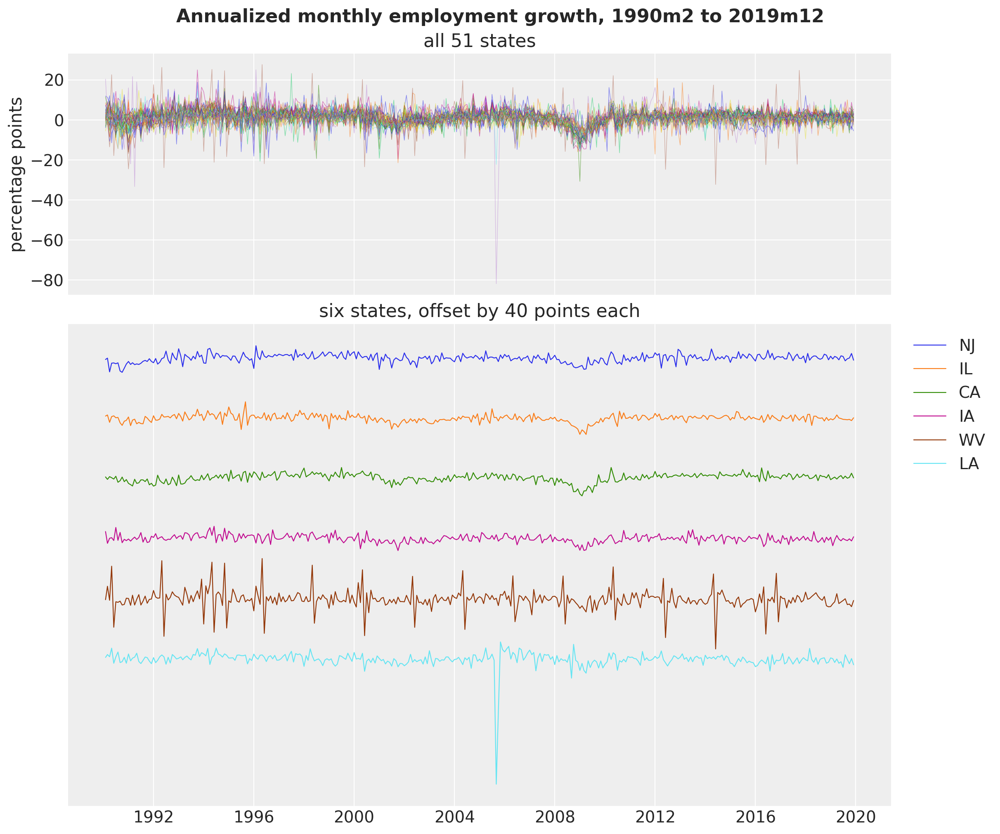

In [3]:
SELECTED = ("NJ", "IL", "CA", "IA", "WV", "LA")
selected_index = [states.index(state) for state in SELECTED]
STATE_COLORS = dict(zip(SELECTED, ("C0", "C1", "C2", "C3", "C4", "C5"), strict=True))

fig, axes = plt.subplots(
    nrows=2, figsize=(12, 10), sharex=True, layout="constrained", height_ratios=(1, 2)
)
axes[0].plot(dates_all, growth_all, lw=0.5, alpha=0.5)
axes[0].set(title="all 51 states", ylabel="percentage points")

for offset, state in enumerate(SELECTED):
    series = growth_all[:, states.index(state)]
    axes[1].plot(dates_all, series - 40.0 * offset, lw=0.8, color=STATE_COLORS[state], label=state)

axes[1].set(title="six states, offset by 40 points each", yticks=[])
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
locator = mdates.AutoDateLocator()
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
fig.suptitle(
    "Annualized monthly employment growth, 1990m2 to 2019m12", fontsize=16, fontweight="bold"
);

The top panel is the paper's Figure 1(a): 51 series of annualized monthly growth, most of the time between $-10$ and $+10$ percentage points, with three synchronized dips, the 1990 to 1991 recession, 2001, and the 2008 to 2009 recession, where every state goes negative at once. The single spike to $-82$ points in 2005m9 is Louisiana after Hurricane Katrina. The bottom panel separates six states:

- New Jersey, Illinois, California and Iowa are smooth series with the three recessions as their only large moves; California's 2009 dip is the deepest of the four.
- West Virginia has spikes of $\pm 20$ to $30$ points every year or two, often followed by a spike of the opposite sign the next month, a pattern the paper attributes to mining employment.
- Louisiana has the Katrina month, $-81.8$ points in 2005m9, followed by $-34.4$ in 2005m10 and a rebound to $+12.4$ in 2005m11.

Growth rates of this size are what the models below forecast one, three and six months ahead.

The paper lists five features of these data that its model is built to capture: comovement across states, similar persistence and variability across states, outliers, volatility that changes over time, and slowly moving levels. The next three figures measure the first four. The first figure measures the comovement: the correlation between every pair of states, for the monthly growth rates and for the 12-month growth rates (the mean of twelve consecutive monthly rates, which smooths the month-to-month noise).

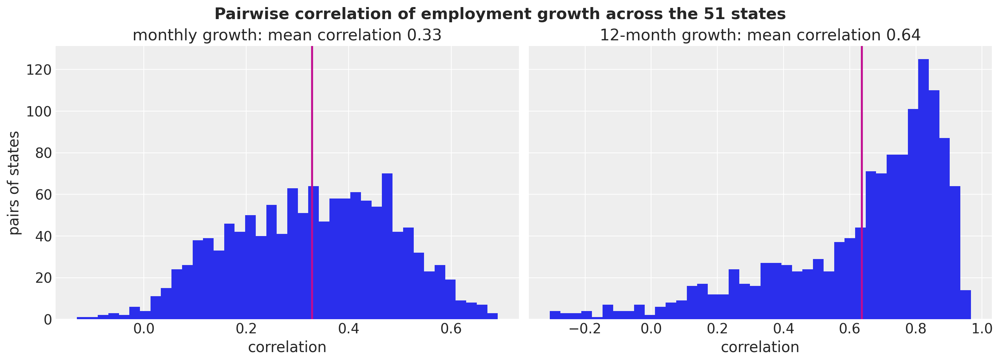

In [4]:
def pairwise_correlations(series: np.ndarray) -> np.ndarray:
    """Correlation of every pair of columns of ``series`` ``(time, states)``, each pair once."""
    correlation = np.corrcoef(series.T)  # (states, states)
    return correlation[np.triu_indices(series.shape[1], k=1)]  # (1275,)


# The 12-month growth rate is the mean of 12 consecutive monthly rates: (months - 11, states).
annual_growth = np.stack(
    [
        np.convolve(np.asarray(growth_all[:, s]), np.ones(12) / 12.0, mode="valid")
        for s in range(num_states)
    ],
    axis=1,
)
pairs = {
    "monthly growth": pairwise_correlations(np.asarray(growth_all)),
    "12-month growth": pairwise_correlations(annual_growth),
}

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5), sharey=True, layout="constrained")

for ax, (label, values) in zip(axes, pairs.items(), strict=True):
    ax.hist(values, bins=40, color="C0")
    ax.axvline(values.mean(), color="C3", lw=2)
    ax.set(title=f"{label}: mean correlation {values.mean():.2f}", xlabel="correlation")

axes[0].set(ylabel="pairs of states")
fig.suptitle(
    "Pairwise correlation of employment growth across the 51 states",
    fontsize=16,
    fontweight="bold",
);

The two panels give two numbers for the same comovement. On the monthly rates the mean pairwise correlation is $0.33$, because a single month of growth carries a lot of state-specific noise. On the 12-month rates, which average that noise out, the mean correlation is $0.64$ and most pairs sit between $0.6$ and $0.95$: over a year the states move together. The paper reports an average pairwise correlation of $0.33$ for year-over-year growth rates over the same sample, the value of the monthly rates here and half the value of the 12-month rates; the paper does not say more about that computation, so the difference stays open. Every rung of this notebook treats the 51 series as independent given its parameters, so this comovement stays unused; the paper's Model VII, with a common factor, is the rung that uses it.

The second figure measures how similar the dynamics are across states. We fit the AR(12) of the paper's equation (1) to each state by least squares,

$$
y_{j,t} = c_j + \sum_{l=1}^{12} \phi_{j,l} \, y_{j,t-l} + \varepsilon_{j,t},
$$

and look at two summaries across states: the sum of the AR coefficients $\sum_l \phi_{j,l}$, which measures persistence (a sum near one means a shock to growth fades slowly), and the standard deviation of the residuals, which measures the size of a typical monthly surprise. The paper's Table 1 reports the quantiles of both across the 51 states. `ols_ar` builds the lag matrix from the seed rows and the likelihood rows and solves the least squares problem of every state at once; it returns the intercepts, the coefficients in the `(lag, state)` layout of the models below, and the residual standard deviations.

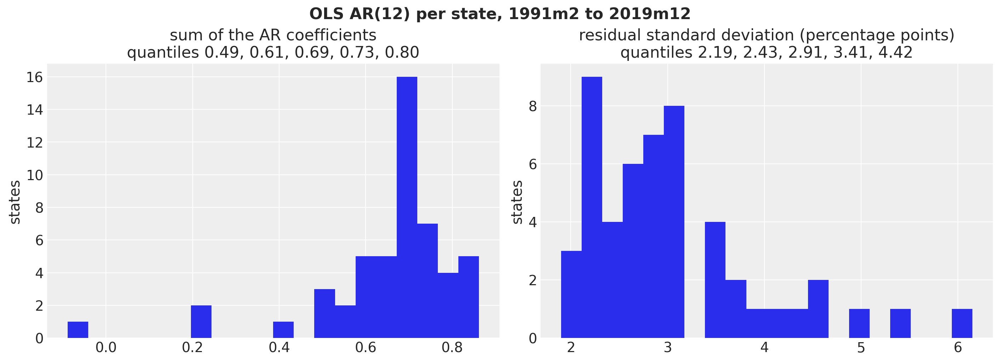

In [5]:
def lag_matrix(y_init: Array, y: Array) -> Array:
    """Lagged values ``(months, lags, states)`` of ``y``, lag 1 first, seeded by ``y_init``."""
    panel = jnp.concatenate([y_init, y], axis=0)  # (12 + months, states)
    rows = jnp.arange(y.shape[0])[:, None] + (LAGS - 1 - jnp.arange(LAGS))[None, :]  # (months, 12)
    return panel[rows]  # (months, 12, states): row t holds y_{t-1}, ..., y_{t-12}


def ols_ar(y_init: Array, y: Array) -> tuple[Array, Array, Array]:
    """Per-state OLS AR(12): intercepts ``(states,)``, coefficients ``(12, states)``, residual sd."""
    design = jnp.concatenate(
        [jnp.ones((y.shape[0], 1, y.shape[1])), lag_matrix(y_init, y)], axis=1
    )  # (months, 13, states): a constant and the 12 lags
    solve = jax.vmap(lambda x, target: jnp.linalg.lstsq(x, target)[0], in_axes=(2, 1), out_axes=1)
    coefficients = solve(design, y)  # (13, states)
    residuals = y - jnp.einsum("tks,ks->ts", design, coefficients)  # (months, states)
    return coefficients[0], coefficients[1:], residuals.std(axis=0, ddof=13)


ols_intercept, ols_phi, ols_sigma = ols_ar(y_init, growth)
ols_persistence = np.asarray(ols_phi.sum(axis=0))  # (states,): the sum of the AR coefficients
quantile_levels = (0.10, 0.25, 0.50, 0.75, 0.90)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5), layout="constrained")

for ax, values, name in zip(
    axes,
    (ols_persistence, np.asarray(ols_sigma)),
    ("sum of the AR coefficients", "residual standard deviation (percentage points)"),
    strict=True,
):
    quantiles = np.quantile(values, quantile_levels)
    ax.hist(values, bins=20, color="C0")
    ax.set(
        title=name + "\nquantiles " + ", ".join(f"{q:.2f}" for q in quantiles),
        ylabel="states",
    )

fig.suptitle("OLS AR(12) per state, 1991m2 to 2019m12", fontsize=16, fontweight="bold");

Both distributions are the paper's Table 1 to the second decimal: the sum of the AR coefficients has quantiles $0.49$, $0.61$, $0.69$, $0.73$ and $0.80$ across the states (the paper: $0.49$, $0.60$, $0.69$, $0.73$, $0.81$), and the residual standard deviation $2.19$, $2.43$, $2.91$, $3.41$ and $4.42$ points (the paper: $2.18$, $2.42$, $2.89$, $3.42$, $4.44$), so the data and the transformation are the paper's. Four states stand apart on persistence, with sums of coefficients at $-0.1$, $0.2$, $0.2$ and $0.4$ against $0.5$ to $0.85$ for the rest, and the residual standard deviations run from $2$ to $6$ points, West Virginia at the top. Similar, not identical, is the case the hierarchical prior is made for: it pulls every state toward a common value by an amount the data decide.

The third figure measures whether the volatility moves. For the six states we take the OLS residuals and compute their standard deviation over a rolling window of 24 months: a flat line says a single innovation scale fits the whole sample, a line that rises and falls says the scale moves.

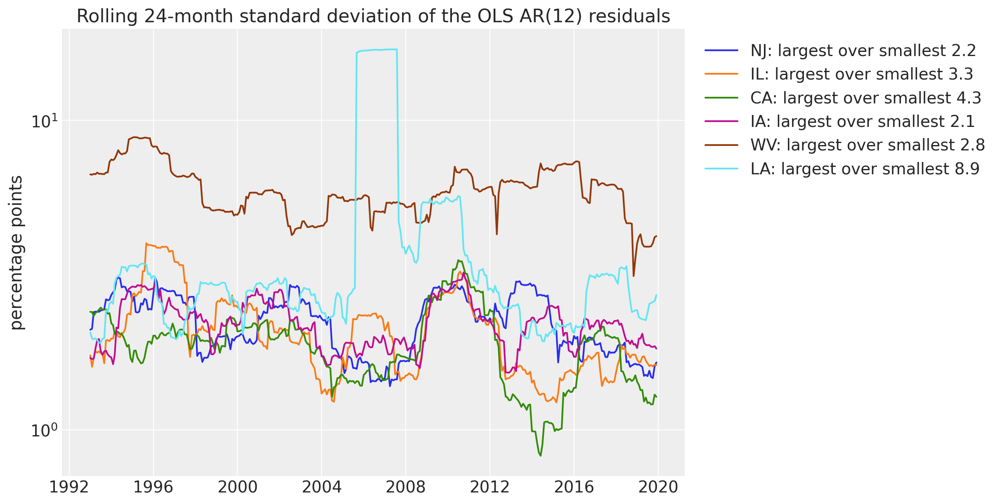

In [6]:
ols_residuals = (
    growth - ols_intercept - jnp.einsum("tls,ls->ts", lag_matrix(y_init, growth), ols_phi)
)
ROLLING = 24
rolling_sd = np.stack(
    [
        np.sqrt(
            np.convolve(
                np.asarray(ols_residuals[:, s]) ** 2, np.ones(ROLLING) / ROLLING, mode="valid"
            )
        )
        for s in selected_index
    ],
    axis=1,
)  # (months - 23, 6)

fig, ax = plt.subplots(figsize=(12, 6))

for column, state in enumerate(SELECTED):
    ratio = rolling_sd[:, column].max() / rolling_sd[:, column].min()
    ax.plot(
        dates[ROLLING - 1 :],
        rolling_sd[:, column],
        color=STATE_COLORS[state],
        label=f"{state}: largest over smallest {ratio:.1f}",
    )

locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(
    title="Rolling 24-month standard deviation of the OLS AR(12) residuals",
    ylabel="percentage points",
    yscale="log",
);

The innovation scale is not constant over the sample. For the four smooth states the rolling standard deviation falls from about $2$ to $3$ points in the 1990s to $1.5$ in the mid 2000s, doubles to $3$ or more in 2009 to 2010, and falls again to $1.5$ or less by 2015; the largest window over the smallest is $2.1$ for Iowa, $2.2$ for New Jersey, $3.3$ for Illinois and $4.3$ for California. West Virginia sits at $4$ to $9$ points throughout, kept high by the mining spikes. Louisiana's ratio of $8.9$ is Katrina alone: its line jumps to $20$ points for the two years that 2005m9 stays inside the window and returns to $3$ afterwards. The 2009 to 2010 bump that every smooth state shares is the comovement in volatility that the paper's Model V is built for; the Katrina block is a single month, which is what the outlier component of Model IV is for.

## The forecasting task

The quantity to forecast is the **$h$-month growth rate** from the forecast origin $T^*$,

$$
y^h_{j, T^* + h} = \frac{1200}{h} \, (\log E_{j, T^* + h} - \log E_{j, T^*}) = \frac{1}{h} \sum_{k=1}^{h} y_{j, T^* + k},
$$

the mean of the next $h$ monthly rates, at $h = 1, 3, 6$. A forecast of the monthly path over the next six months gives all three at once: the cumulative mean of the path at steps one, three and six. Every model below forecasts the path by simulation, so its forecast of $y^h$ is a set of draws, from which we read a point forecast (the mean), quantiles and an interval.

The paper scores the three with the losses that these summaries minimize in expectation:

- Squared error of the point forecast $\hat y$, reported as the root mean squared forecast error (RMSE) $\sqrt{\text{mean}(y - \hat y)^2}$, which the mean of the predictive distribution minimizes.
- Quantile loss of the forecast quantile $\hat y_\tau$, $\tau (y - \hat y_\tau)$ when $y \ge \hat y_\tau$ and $(1 - \tau)(\hat y_\tau - y)$ otherwise, which the $\tau$ quantile of the predictive distribution minimizes. The paper reports $\tau \in \{0.05, 0.10, 0.25, 0.75, 0.90, 0.95\}$; this is [`eval_pinball`](../../reference/metrics.eval_pinball.html).
- Interval loss of the equal-tailed 90-10 interval $[\hat y_{0.10}, \hat y_{0.90}]$: its width plus $2/\alpha$ times the distance by which the realized value misses it, with $\alpha = 0.2$ the total tail probability. With the constant $2/\alpha$ the $0.10$ and $0.90$ quantiles minimize the expected loss, which is the property the paper states; the paper's display prints $1/\alpha$, for which the minimizer would be the 80-20 interval, so we take $2/\alpha$ as the intended constant. This is [`eval_interval_score`](../../reference/metrics.eval_interval_score.html) with `alpha=0.8`, the level of the interval. The relative interval losses below are comparable with the paper's up to that constant.

We add the **continuous ranked probability score** (CRPS), which scores the whole distribution of the draws, as [`eval_crps`](../../reference/evaluate.eval_crps.html). The losses are averaged over every state and every forecast origin, as in the paper, and reported relative to Model 0, so that a value of $0.95$ means a loss $5\%$ below the benchmark.

The paper's experiment is recursive: the model is estimated on the data up to an origin $T^*$, forecasts are made for $T^* + 1$ to $T^* + 6$, and the origin moves forward one month at a time from 1999m12 to 2019m6, so the first forecast uses ten years of data and the evaluation covers 2000 to 2019. Model 0 is cheap enough to follow that design at every one of its 235 origins. The five Bayesian models re-estimate with NUTS at every twenty-fourth origin, 1999m12, 2001m12, and so on to 2017m12, which is 10 fits per model and keeps the notebook's run time under an hour; their relative losses use Model 0 at the same 10 origins as the denominator. The *Pseudo-out-of-sample forecasts* section has the code.

## Model I: Bayesian shrinkage

The first Bayesian model is the paper's Model I: the same AR(12) per state, now with priors. We write it in the paper's notation, with one departure, and with the paper's convention that the second argument of every $\text{Normal}$ in a display is a variance (the preliz figures label standard deviations). For state $j$ and month $t$,

$$
\begin{align*}
y_{j,t} &= \mu_j + u_{j,t}, \\
u_{j,t} &= \sum_{l=1}^{12} \phi_{j,l} \, u_{j,t-l} + \sigma_j \, \varepsilon_{j,t}, \qquad \varepsilon_{j,t} \sim \text{Normal}(0, 1),
\end{align*}
$$

where

- $\mu_j$ is the **mean growth rate** of state $j$, the level the series returns to,
- $u_{j,t}$ is the deviation from that level, an AR(12) with coefficients $\phi_{j,l}$,
- $\sigma_j$ is the **innovation scale** of state $j$, the standard deviation of a monthly surprise.

The paper writes $y_{j,t} = \mu_j + \omega \, u_{j,t}$ with a **common scale** $\omega$ and relative scales $\sigma_j$ around it. The likelihood depends on $\omega$ and $\sigma_j$ only through the product $\omega \sigma_j$, so we sample the absolute scale $\sigma_j$ and keep $\omega$ as the center of its prior, the site `log_omega2`. The paper's priors on $\omega$ and $\mu_j$ are flat; we use $\text{Normal}(0, 10^2)$ on $\ln \omega^2$ and on $\mu_j$, which is flat over any value these quantities can take (the state means are between $-1$ and $5$ percentage points, $\ln \omega^2$ near $2$) and lets us draw from the prior. The priors are

$$
\begin{align*}
\mu_j &\sim \text{Normal}(0, 10^2), \\
\ln \omega^2 &\sim \text{Normal}(0, 10^2), \\
\phi_{j,l} &\sim \text{Normal}\!\left(0, (0.2 / l)^2\right), \\
\ln \sigma_j^2 &\sim \text{Normal}(\ln \omega^2, 0.3^2).
\end{align*}
$$

The prior on $\phi_{j,l}$ is a **Minnesota prior** in the sense of [Doan, Litterman and Sims (1984)](https://doi.org/10.1080/07474938408800053): zero mean, so every coefficient is shrunk toward zero, and a standard deviation that falls with the lag, $0.2$ at lag one and $0.017$ at lag twelve, so the distant lags are shrunk harder. On the scale of the OLS estimates, where the first coefficient is about $0.3$ and the sum about $0.7$, a standard deviation of $0.2$ at lag one is a weak pull and the twelfth lag is pinned near zero. The prior on $\ln \sigma_j^2$ puts the variance of each state within a factor of $e^{0.3} \approx 1.35$ of the common variance with $68\%$ probability, the scale within $e^{0.15} \approx 1.16$, and it is the only link between the states in this model: the coefficients of one state say nothing about those of another. The next figure plots the Minnesota prior at four lags and the implied prior on $\sigma_j / \omega$.

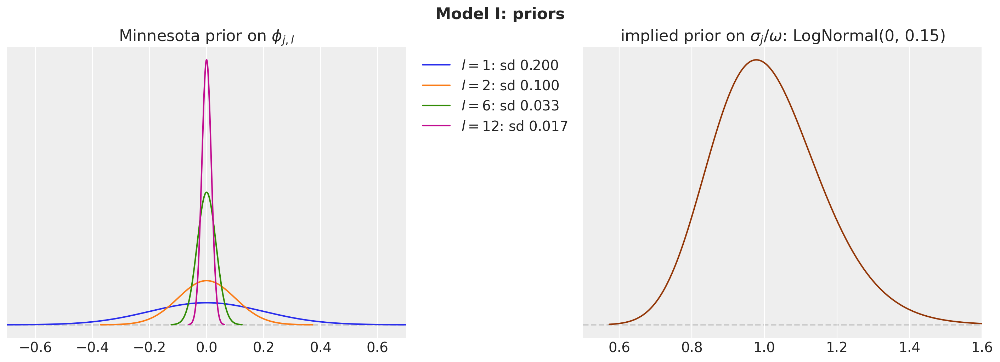

In [7]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5), layout="constrained")

lag_handles = []

for lag, color in zip((1, 2, 6, 12), ("C0", "C1", "C2", "C3"), strict=True):
    pz.Normal(0, 0.2 / lag).plot_pdf(ax=axes[0], color=color, legend=None)
    lag_handles.append(
        axes[0].plot([], [], color=color, label=rf"$l = {lag}$: sd {0.2 / lag:.3f}")[0]
    )

axes[0].legend(handles=lag_handles, loc="upper left", bbox_to_anchor=(1.01, 1.0))
axes[0].set(title=r"Minnesota prior on $\phi_{j, l}$", xlim=(-0.7, 0.7))
pz.LogNormal(0, 0.15).plot_pdf(ax=axes[1], color="C4", legend=None)
axes[1].set(title=r"implied prior on $\sigma_j / \omega$: LogNormal(0, 0.15)", xlim=(0.5, 1.6))
fig.suptitle("Model I: priors", fontsize=16, fontweight="bold");

The left panel shows how the Minnesota prior tightens with the lag: at lag one a coefficient of $\pm 0.4$ is two standard deviations away, at lag two $\pm 0.2$, at lag six $\pm 0.07$ and at lag twelve $\pm 0.03$. The OLS estimates of the first coefficient run from $-0.5$ to $0.35$ across states, so the prior at lag one barely moves them; at lag twelve the prior decides. The right panel is the implied prior on the ratio of a state's scale to the common scale: a LogNormal with median $1$ whose $94\%$ interval runs from about $0.75$ to $1.35$, where the OLS residual standard deviations of the states span a factor of three ($2$ to $6$ points). Model I's prior on the scales is tighter than the data; Model II learns that spread.

### Prior predictive check: the dynamics

With flat priors on the level and the scale, a prior predictive draw of the growth rates themselves says nothing (its level is anywhere within $\pm 20$ points). What the priors do say is how the series moves around its level, and that is what we check: the **persistence** of the AR polynomial, measured by the largest absolute eigenvalue of its companion matrix (below one the process is stationary, and the closer to one the slower a shock fades), and the **impulse response**, the path of $u_{j,t}$ after a unit shock. We draw $\phi$ from the Minnesota prior and compare with the OLS estimates of the 51 states. [`companion_matrix`](../../reference/var.companion_matrix.html) takes the `(lags, obs, obs)` layout of the package's VAR tools; a univariate AR is the case `obs = 1`.

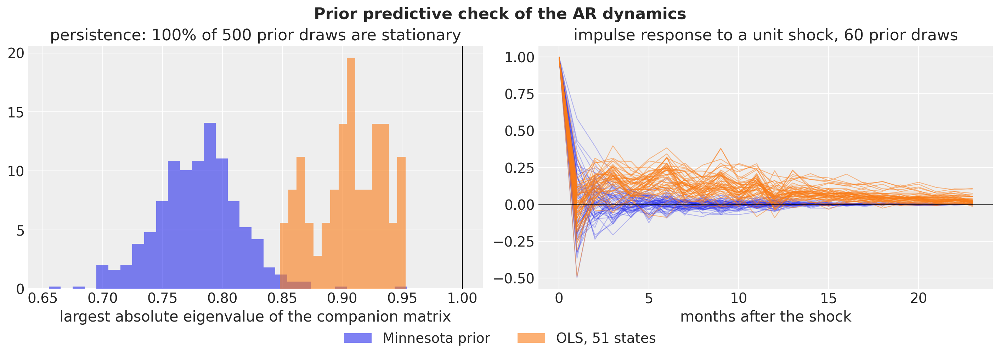

In [8]:
def spectral_radius(phi: Array) -> np.ndarray:
    """Largest absolute eigenvalue of the companion matrix of each AR(12) in ``phi``.

    ``phi`` has shape ``(..., 12, states)``; the result has shape ``(..., states)``.
    """
    matrices = companion_matrix(
        jnp.swapaxes(phi, -1, -2)[..., None, None]
    )  # (..., states, 12, 12): one univariate AR(12) per state
    return np.abs(np.linalg.eigvals(np.asarray(matrices))).max(axis=-1)


def impulse_response(phi: Array, steps: int = 24) -> Array:
    """Response of the AR(12) in ``phi`` ``(12, states)`` to a unit shock, ``(steps, states)``."""

    def step(window: Array, _: None) -> tuple[Array, Array]:
        value = jnp.einsum("ls,ls->s", phi, window[::-1])
        return jnp.concatenate([window[1:], value[None]]), value

    start = jnp.zeros((LAGS, phi.shape[1])).at[-1].set(1.0)  # the shock is the last row
    _, response = jax.lax.scan(step, start, None, length=steps - 1)
    return jnp.concatenate([jnp.ones((1, phi.shape[1])), response])


rng_key, key_prior = random.split(rng_key)
minnesota_scale = 0.2 / jnp.arange(1, LAGS + 1)  # (12,)
prior_phi = minnesota_scale[None, :, None] * random.normal(
    key_prior, (500, LAGS, 1)
)  # (500, 12, 1)
prior_radius = spectral_radius(prior_phi)[:, 0]  # (500,)
prior_response = jax.vmap(impulse_response)(prior_phi)[:, :, 0]  # (500, 24)
ols_response = np.asarray(impulse_response(ols_phi))  # (24, states)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5), layout="constrained")
axes[0].hist(prior_radius, bins=30, color="C0", alpha=0.6, density=True, label="Minnesota prior")
axes[0].hist(
    spectral_radius(ols_phi), bins=15, color="C1", alpha=0.6, density=True, label="OLS, 51 states"
)
axes[0].axvline(1.0, color="black", lw=1)
axes[0].set(
    title=f"persistence: {100 * (prior_radius < 1).mean():.0f}% of 500 prior draws are stationary",
    xlabel="largest absolute eigenvalue of the companion matrix",
)
steps = np.arange(24)
axes[1].plot(steps, np.asarray(prior_response[:60]).T, color="C0", alpha=0.3, lw=0.8)
axes[1].plot(steps, ols_response, color="C1", alpha=0.5, lw=0.8)
axes[1].axhline(0.0, color="black", lw=0.5)
axes[1].set(
    title="impulse response to a unit shock, 60 prior draws", xlabel="months after the shock"
)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=2)
fig.suptitle("Prior predictive check of the AR dynamics", fontsize=16, fontweight="bold");

Every one of the $500$ prior draws is stationary, and the prior is less persistent than the data: the largest root of the companion matrix is between $0.7$ and $0.85$ under the prior and between $0.85$ and $0.95$ in the OLS fits. The impulse responses say the same thing in the time domain. Under the prior a unit shock is gone within about twelve months and the response oscillates around zero; in the data it is still $0.1$ to $0.2$ after a year and, after a first month that can go either way (one state at $-0.5$), positive from the third month on, because the OLS coefficients are positive at lags two to six, where the prior is centered at zero. The prior allows the data's dynamics (every OLS fit is inside its support) but does not expect them. The hierarchical prior of Model II moves the center of each lag to where the states agree.

### The model function

One function builds every rung. Its four switches follow the ladder: `hierarchical` (Model II) pools the coefficients and the scales across states, `student_t` (Model III) replaces the Normal innovations with Student-t ones, `outliers` (Model IV) adds the additive outlier component, and `stochastic_volatility` (Model V) lets the innovation scale move over time. Each switch is explained in its own section; the code is here once so that the later sections only turn switches on.

The observed history enters through `covariates`: [`ssoe`](../../reference/models.ssoe.html) runs the AR recursion over the observed rows (its `mean` reads the lag window, its `update` shifts the window by one row) and, when the covariates extend past the data, draws the future innovations at the site `eps_future` and iterates the recursion over the horizon. The seed rows `y_init` are the initial lag window. The one-step means come back as `r.mu` and the simulated future path as `r.y_future`; the likelihood is written on `r.mu`, and `forecast` is the path. [`Horizon.from_data`](../../reference/models.Horizon.html) reads the horizon from the length difference between `covariates` and `data`, so a training call passes the growth panel as both and a forecast call passes a panel with six more rows.

The hierarchical sites come in two forms. The coefficients, the degrees of freedom, the outlier scales and the volatility components are written in **non-centered form**: the model samples a standardized value `<name>_z` from $\text{Normal}(0, 1)$ and builds the site as location plus scale times that value, which keeps the geometry of the posterior regular where the data say little about an individual state's value. The innovation scales $\ln \sigma_j^2$ stay **centered**, because $347$ observations pin every state's scale to within a few percent and the non-centered form then hurts: a trial fit of Model II with `log_sigma2` non-centered had $18$ divergent transitions and $95$ effective draws for `log_omega2`, against $0$ and $3{,}769$ centered. The hierarchical Model II and the switches of Models III to V are documented in their sections.

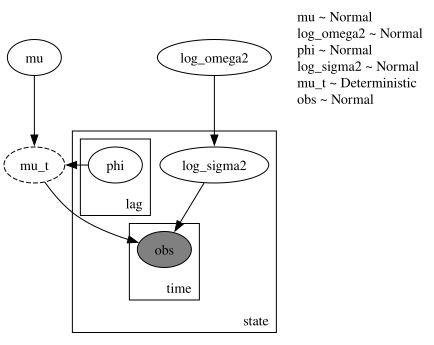

In [9]:
def low_frequency_basis(num_periods: int, num_terms: int) -> Array:
    r"""Leading eigenvectors of a demeaned random walk, scaled by the root eigenvalues.

    The columns are $\varphi_l = \lambda_l^{1/2} \psi_l$ for the ``num_terms`` largest
    eigenvalues $\lambda_l$ of the covariance matrix of a demeaned random walk of
    ``num_periods`` steps with unit innovation variance, the basis of the paper's
    equation (21); the first row of every column is positive.
    """
    cumsum = np.tril(np.ones((num_periods, num_periods)))
    demean = np.eye(num_periods) - np.ones((num_periods, num_periods)) / num_periods
    covariance = demean @ cumsum @ cumsum.T @ demean.T
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    order = np.argsort(eigenvalues)[::-1][:num_terms]
    basis = eigenvectors[:, order] * np.sqrt(eigenvalues[order])
    return jnp.asarray(basis * np.sign(basis[0])[None, :], dtype=jnp.float32)


MAX_LOG_NU = 8.0  # float32 limit of StudentT.log_prob, see the Model III section


def make_rts_model(
    y_init: Array,
    *,
    hierarchical: bool = True,
    student_t: bool = False,
    outliers: bool = False,
    stochastic_volatility: bool = False,
) -> ForecastModel:
    """Build one rung of the related time series ladder for the panel seeded by ``y_init``."""
    num_lags, num_states = y_init.shape
    lags = jnp.arange(1, num_lags + 1, dtype=jnp.float32)
    minnesota_scale = 0.2 / lags  # (12,): the prior sd of phi_{j,l} shrinks with the lag

    def rts_model(covariates: Array, data: Array | None = None) -> None:
        """Related time series model for ``data`` shaped ``(months, states)``."""
        h = Horizon.from_data(covariates, data)
        y = covariates[..., : h.t_obs, :]  # (t_obs, states): the observed history
        state_plate = numpyro.plate("state", num_states, dim=-1)
        lag_plate = numpyro.plate("lag", num_lags, dim=-2)

        mu = numpyro.sample("mu", dist.Normal(0.0, 10.0).expand([num_states]).to_event(1))
        log_omega2 = numpyro.sample("log_omega2", dist.Normal(0.0, 10.0))
        if hierarchical:
            # Model II: phi_{j,l} ~ Normal(m_l, v_l) with m_l and v_l learned per lag,
            # ln sigma_j^2 ~ Normal(ln omega^2, v_sigma) with v_sigma learned.
            phi_loc = numpyro.sample(
                "phi_loc", dist.Normal(0.0, 0.5 * minnesota_scale).to_event(1)
            )
            log_v_phi = numpyro.sample(
                "log_v_phi", dist.Normal(jnp.log(minnesota_scale**2), 0.5).to_event(1)
            )
            with lag_plate, state_plate:
                phi_z = numpyro.sample("phi_z", dist.Normal(0.0, 1.0))
            phi = numpyro.deterministic(
                "phi", phi_loc[:, None] + jnp.exp(0.5 * log_v_phi)[:, None] * phi_z
            )  # (12, states)
            log_v_sigma = numpyro.sample("log_v_sigma", dist.Normal(jnp.log(0.3**2), 0.5))
            with state_plate:
                log_sigma2 = numpyro.sample(
                    "log_sigma2", dist.Normal(log_omega2, jnp.exp(0.5 * log_v_sigma))
                )  # (states,): centered, the data pin every state's scale
        else:
            # Model I: the Minnesota prior and a fixed spread of the scales around omega.
            with lag_plate, state_plate:
                phi = numpyro.sample("phi", dist.Normal(0.0, minnesota_scale[:, None]))
            with state_plate:
                log_sigma2 = numpyro.sample("log_sigma2", dist.Normal(log_omega2, 0.3))

        if student_t:
            # Model III: ln(nu_j - 2) ~ Normal(m_nu, v_nu), both learned.
            nu_loc = numpyro.sample("nu_loc", dist.Normal(jnp.log(10.0), 0.5))
            log_v_nu = numpyro.sample("log_v_nu", dist.Normal(jnp.log(0.5**2), 0.5))
            with state_plate:
                log_nu_z = numpyro.sample("log_nu_minus_2_z", dist.Normal(0.0, 1.0))
            log_nu_minus_2 = jnp.minimum(nu_loc + jnp.exp(0.5 * log_v_nu) * log_nu_z, MAX_LOG_NU)
            nu = numpyro.deterministic("nu", 2.0 + jnp.exp(log_nu_minus_2))  # (states,)

        if outliers:
            # Model IV: o_{j,t} = kappa_j eta_{j,t}, eta ~ StudentT(4), ln kappa_j^2 pooled.
            # The paper centers the kappa hierarchy at ln(0.1^2) relative to omega; with
            # omega absorbed the location moves with log_omega2 and the paper's two 0.5^2
            # variances add up.
            kappa_loc = numpyro.sample(
                "kappa_loc", dist.Normal(log_omega2 + jnp.log(0.1**2), jnp.sqrt(0.5**2 + 0.5**2))
            )
            log_v_kappa = numpyro.sample("log_v_kappa", dist.Normal(jnp.log(0.3**2), 0.5))
            with state_plate:
                log_kappa2_z = numpyro.sample("log_kappa2_z", dist.Normal(0.0, 1.0))
            kappa = numpyro.deterministic(
                "kappa", jnp.exp(0.5 * (kappa_loc + jnp.exp(0.5 * log_v_kappa) * log_kappa2_z))
            )  # (states,)
            with numpyro.plate("time", h.t_obs, dim=-2), state_plate:
                eta = numpyro.sample("outlier_eta", dist.StudentT(4.0, 0.0, 1.0))
            outlier = numpyro.deterministic("outlier", kappa * eta)  # (t_obs, states)
        else:
            outlier = jnp.zeros_like(y)

        if stochastic_volatility:
            # Model V: ln sigma_{j,t}^2 = ln sigma_j^2 + basis @ xi_j on the low-frequency
            # basis, with xi_{j,l} ~ Normal(m_l, v_xi): m_l is the common volatility path.
            num_terms = max(1, (h.t_obs + num_lags) // 36)  # the paper counts T from 1990m2
            basis = low_frequency_basis(h.t_obs, num_terms)  # (t_obs, q)
            xi_loc = numpyro.sample(
                "xi_loc", dist.Normal(0.0, 0.01).expand([num_terms]).to_event(1)
            )
            log_v_xi = numpyro.sample("log_v_xi", dist.Normal(jnp.log(0.01**2), 0.5))
            with numpyro.plate("term", num_terms, dim=-2), state_plate:
                xi_z = numpyro.sample("xi_z", dist.Normal(0.0, 1.0))
            xi = xi_loc[:, None] + jnp.exp(0.5 * log_v_xi) * xi_z  # (q, states)
            log_var = numpyro.deterministic("log_var", log_sigma2 + basis @ xi)  # (t_obs, states)
            scale = jnp.exp(0.5 * log_var)
            if h.future > 0:
                # Over the horizon the log variance continues as a random walk with step
                # variance v_xi from its last in-sample value.
                with numpyro.plate("time_future", h.future, dim=-2), state_plate:
                    log_var_z = numpyro.sample("log_var_z_future", dist.Normal(0.0, 1.0))
                log_var_future = log_var[-1] + jnp.exp(0.5 * log_v_xi) * jnp.cumsum(
                    log_var_z, axis=0
                )
                scale_future = jnp.exp(0.5 * log_var_future)  # (future, states)
            else:
                scale_future = jnp.exp(0.5 * log_sigma2)
        else:
            scale = jnp.exp(0.5 * log_sigma2)  # (states,)
            scale_future = scale

        # AR(12) around the mean, y_t - mu = sum_l phi_l (y_{t-l} - mu) + error, written with
        # the intercept mu (1 - sum_l phi_l) on the lag window of y itself.
        intercept = mu * (1.0 - phi.sum(axis=0))  # (states,)

        def mean(window: Array, _: object) -> Array:
            """Conditional mean from the lag window ``(12, states)``, most recent row last."""
            return intercept + jnp.einsum("ls,ls->s", phi, window[::-1])

        def update(window: Array, y_t: Array, eps_t: Array, _: object) -> Array:
            """Shift the lag window by one row."""
            return jnp.concatenate([window[1:], y_t[None]], axis=0)

        noise = (
            dist.StudentT(nu, 0.0, scale_future) if student_t else dist.Normal(0.0, scale_future)
        )
        # The recursion runs on the series without its additive outliers, so an outlier
        # never enters the lag window.
        r = ssoe(h, "eps", y - outlier, y_init, mean, update, noise)
        mu_t = numpyro.deterministic("mu_t", r.mu)  # (t_obs, states): the one-step means
        obs_dist = (
            dist.StudentT(nu, mu_t + outlier, scale)
            if student_t
            else dist.Normal(mu_t + outlier, scale)
        )
        with numpyro.plate("time", h.t_obs, dim=-2), state_plate:
            numpyro.sample("obs", obs_dist, obs=h.data)
        if h.future > 0:
            y_future = r.y_future
            loc_future = r.mu_future  # (future, states): the one-step means over the horizon
            if outliers:
                with numpyro.plate("time_future", h.future, dim=-2), state_plate:
                    eta_future = numpyro.sample("outlier_eta_future", dist.StudentT(4.0, 0.0, 1.0))
                y_future = y_future + kappa * eta_future
                loc_future = loc_future + kappa * eta_future
            numpyro.deterministic("forecast", y_future)
            # The location and scale of the one-step predictive given the draw, for the
            # leave-future-out log score of the evaluation.
            numpyro.deterministic("forecast_loc", loc_future)
            numpyro.deterministic("forecast_scale", jnp.broadcast_to(scale_future, y_future.shape))

    return rts_model


HORIZON = 6
covariates_full = jnp.concatenate(
    [growth, jnp.zeros((HORIZON, num_states))]
)  # (months + 6, states)
model_1 = make_rts_model(y_init, hierarchical=False)
numpyro.render_model(model_1, model_args=(growth, growth), render_distributions=True)

The graph of Model I: `phi` sits in the `lag` and `state` plates, `log_sigma2` in the `state` plate and `obs` in the `time` and `state` plates; `mu` (a vector of length $51$) and the one-step mean `mu_t` (a deterministic site, dashed) are drawn outside the plates, and `log_omega2`, the common scale, is the only link between the states. A training call has no horizon, so no `_future` site appears.

### Model 0: the OLS AR(12) benchmark

Model 0 is this function with the plug-in posterior: the OLS fit of the data section, with Gaussian errors of the residual standard deviation, so its forecast distribution is the simulated path (draw $\varepsilon_{j, T^*+k}$ from $\text{Normal}(0, \hat\sigma_j^2)$, feed it through the fitted recursion, repeat) and the forecast mechanics are the same for every rung of the ladder. `ols_posterior` fills the sample sites of the non-hierarchical rung with the OLS values, repeated once per draw: `mu` (the mean growth rate $\mu_j$, which relates to the OLS intercept as $c_j = \mu_j (1 - \sum_l \phi_{j,l})$), `phi` (the coefficients), `log_sigma2` (the log innovation variance) and `log_omega2` (the common log scale, which the forecast does not read). We forecast six months from the last origin of the sample for Louisiana, as a first look at the forecast mechanics, and run the paper's experiment at all 235 monthly origins. `ols_forecast_fn` is the `forecast_fn` of [`backtest`](../../reference/evaluate.backtest.html): it fits by least squares on the training window and forecasts with the plug-in posterior, no sampling involved. The windows expand from the start of the sample, so the seed rows that the model closes over are the same twelve months in every window.

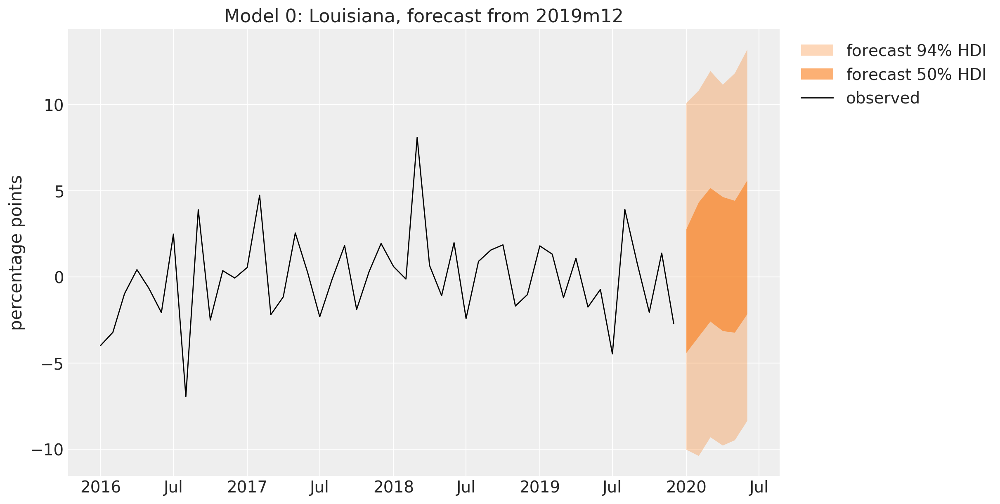

In [10]:
FIRST_ORIGIN = 107  # likelihood rows up to and including 1999m12
assert dates[FIRST_ORIGIN - 1] == np.datetime64("1999-12-01")

HDI_PROBS = (0.94, 0.5)
HDI_ALPHAS = (0.3, 0.6)


def hdi_label(prob: float) -> str:
    r"""Legend label of an HDI band, for example ``$94\%$ HDI``."""
    return rf"${prob:.0%}$ HDI".replace("%", r"\%")


def plot_bands(
    draws: np.ndarray,
    x: np.ndarray,
    series: list[str],
    *,
    color: str = "C0",
    label: str = "",
    col_wrap: int = 1,
    figsize: tuple[int, int] = (12, 6),
    plot_collection: PlotCollection | None = None,
) -> tuple[PlotCollection, list[PolyCollection]]:
    r"""Plot the $50\%$ and $94\%$ HDI bands of ``draws`` against ``x``, one panel per series.

    Returns the plot collection and the band handles, labeled ``f"{label}{hdi_label(prob)}"``.
    """
    pc = az.plot_lm(
        predictions_to_datatree(draws, x, series),
        y="obs",
        x="t",
        plot_dim="time",
        plot_collection=plot_collection,
        ci_kind="hdi",
        ci_prob=HDI_PROBS,
        smooth=False,
        col_wrap=col_wrap,
        visuals={
            "ci_band": {"color": color},
            "observed_scatter": False,
            "pe_line": False,
            "xlabel": False,
            "ylabel": False,
        },
        aes={"alpha": ["prob"]},
        alpha=HDI_ALPHAS,
        figure_kwargs={"figsize": figsize},
    )
    handles = []

    for prob in HDI_PROBS:
        band = pc.viz["ci_band"]["t"].sel(series=series[0], prob=prob).item()
        band.set_label(f"{label}{hdi_label(prob)}")
        handles.append(band)

    for ax in pc.viz["figure"].item().axes:
        locator = mdates.AutoDateLocator()
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

    return pc, handles


future_dates = (dates[-1].astype("datetime64[M]") + np.arange(1, HORIZON + 1)).astype(
    "datetime64[D]"
)
future_date_num = mdates.date2num(future_dates)
louisiana = states.index("LA")


def ols_posterior(y_init: Array, y: Array, num_draws: int) -> dict[str, Array]:
    """Repeat the OLS AR(12) estimates of ``y`` ``num_draws`` times, keyed by model site."""
    intercept, phi, sigma = ols_ar(y_init, y)
    log_sigma2 = jnp.log(sigma**2)
    num_states = y.shape[1]
    return {
        "mu": jnp.broadcast_to(intercept / (1.0 - phi.sum(axis=0)), (num_draws, num_states)),
        "phi": jnp.broadcast_to(phi, (num_draws, LAGS, num_states)),
        "log_sigma2": jnp.broadcast_to(log_sigma2, (num_draws, num_states)),
        "log_omega2": jnp.broadcast_to(log_sigma2.mean(), (num_draws,)),
    }


OLS_DRAWS = 4_000
rng_key, key_forecast = random.split(rng_key)
ols_draws = forecast(
    key_forecast, model_1, ols_posterior(y_init, growth, OLS_DRAWS), growth, covariates_full
)
plot_start = num_months - 48
pc, band_handles = plot_bands(
    np.asarray(ols_draws)[:, :, louisiana : louisiana + 1],
    future_date_num,
    ["LA"],
    color="C1",
    label="forecast ",
)
ax = pc.viz["figure"].item().axes[0]
(observed_line,) = ax.plot(
    date_num[plot_start:], growth[plot_start:, louisiana], color="black", lw=1, label="observed"
)
ax.legend(handles=[*band_handles, observed_line], loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(title="Model 0: Louisiana, forecast from 2019m12", ylabel="percentage points");

The forecast fan for Louisiana from the last origin: the $50\%$ band spans about $-4.5$ to $+3$ points and the $94\%$ band $-10$ to $+10$ points in the first month, and both move up and widen by a few points over the six months ($-3$ to $+5.5$ and $-9$ to $+13$ in the sixth) as the AR iterates its own simulated errors. The width matches the recent history, where the observed rates swing between $-7$ and $+8$ points; the center of the fan is the state's mean growth, near $0.5$ points, because the AR dynamics decay within a few months. The same mechanics, a plug-in posterior pushed through `forecast`, produce the Model 0 forecasts of the experiment.

In [11]:
def ols_forecast_fn(
    rng_key: Array,
    model: ForecastModel,
    train_data: Array,
    train_covariates: Array,
    full_covariates: Array,
    num_samples: int,
    *,
    batch_size: int | None = None,
) -> Array:
    """Fit Model 0 by least squares on the window and forecast with the plug-in posterior."""
    posterior = ols_posterior(y_init, train_data, num_samples)
    return forecast(rng_key, model, posterior, train_data, full_covariates, batch_size=batch_size)


def run_backtest(
    rng_key: Array,
    model_fn: ModelFactory,
    forecast_fn: ForecastFn,
    *,
    stride: int,
    num_samples: int,
) -> list[BacktestResult]:
    """Run the paper's recursive experiment: expanding windows from 1999m12, six months ahead."""
    return backtest(
        rng_key,
        model_fn,
        growth,
        growth,
        forecast_fn=forecast_fn,
        min_train_window=FIRST_ORIGIN,
        test_window=HORIZON,
        stride=stride,
        num_samples=num_samples,
        metrics={},
        keep_predictions=True,
    )


rng_key, key_backtest = random.split(rng_key)
start = perf_counter()
ols_results = run_backtest(
    key_backtest, lambda: model_1, ols_forecast_fn, stride=1, num_samples=OLS_DRAWS
)
ols_seconds = perf_counter() - start
ols_origins = np.array([dates[result.t1 - 1] for result in ols_results])  # the last observed month

assert len(ols_results) == 235
assert ols_origins[-1] == np.datetime64("2019-06-01")

`horizon_losses` turns the stored draws of a backtest into the pooled losses of the task section at the three horizons: it stacks the draws of every window, takes the cumulative mean of the paths and of the realized rates, and scores each horizon over all windows and states at once. The figure compares the RMSE at $h = 1, 3, 6$ of Model 0 at the 235 origins with the paper's Table 2, panel (a).

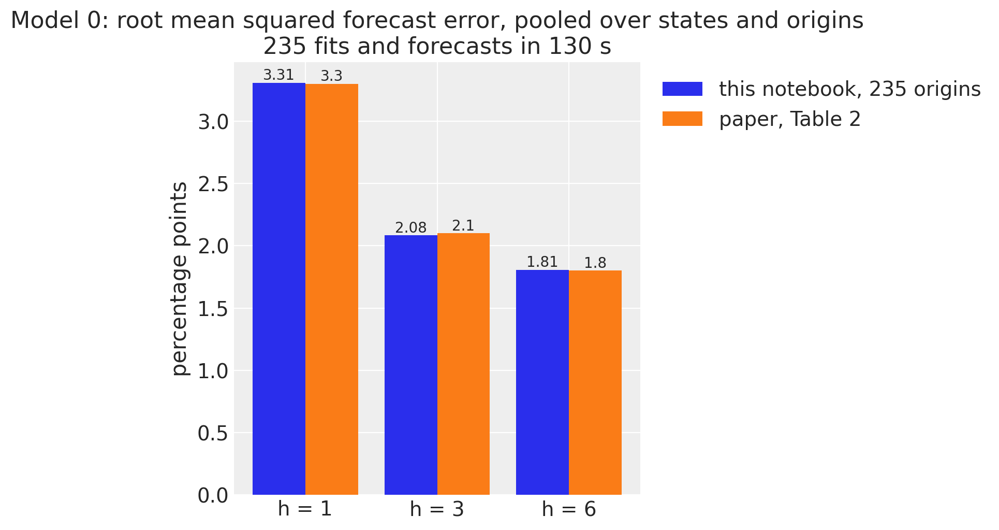

In [12]:
HORIZONS = (1, 3, 6)
QUANTILES = (0.05, 0.10, 0.25, 0.75, 0.90, 0.95)
LOSSES = ("rmse", *(f"q{q:.2f}" for q in QUANTILES), "interval", "crps")
LOSS_LABELS = {
    "rmse": "RMSE",
    **{f"q{q:.2f}": f"quantile {q:.2f}" for q in QUANTILES},
    "interval": "90-10 interval",
    "crps": "CRPS",
}
INTERVAL_LEVEL = 0.8  # the 90-10 interval


def horizon_growth(path: Array) -> Array:
    """Cumulative mean over the horizon axis ``-2``: the 1- to 6-month growth rates of a path."""
    steps = jnp.arange(1, path.shape[-2] + 1, dtype=path.dtype)[:, None]  # (horizon, 1)
    return jnp.cumsum(path, axis=-2) / steps


def stack_windows(results: list[BacktestResult]) -> tuple[Array, Array]:
    """Draws ``(windows, samples, 6, states)`` and truths ``(windows, 6, states)`` of a backtest."""
    draws = jnp.stack([jnp.asarray(result.prediction) for result in results])
    truth = jnp.stack([growth[result.t1 : result.t2] for result in results])
    return horizon_growth(draws), horizon_growth(truth)


def loss_at(name: str, pred: Array, truth: Array) -> float:
    """One pooled loss of ``pred`` ``(samples, *batch)`` against ``truth`` ``(*batch)``."""
    if name == "rmse":
        return float(eval_rmse(pred, truth))
    if name == "interval":
        return float(eval_interval_score(pred, truth, alpha=INTERVAL_LEVEL))
    if name == "crps":
        return float(eval_crps(pred, truth))
    return float(eval_pinball(pred, truth, quantile=float(name[1:])))


def horizon_losses(results: list[BacktestResult]) -> dict[str, dict[int, float]]:
    """Every loss of `LOSSES` at every horizon of `HORIZONS`, pooled over windows and states."""
    draws, truth = stack_windows(results)  # (w, s, 6, n), (w, 6, n)
    pred = jnp.moveaxis(draws, 1, 0)  # (s, w, 6, n): the sample axis first
    return {
        name: {h: loss_at(name, pred[:, :, h - 1], truth[:, h - 1]) for h in HORIZONS}
        for name in LOSSES
    }


ols_losses_235 = horizon_losses(ols_results)
PAPER_RMSE = {1: 3.3, 3: 2.1, 6: 1.8}  # Table 2, panel (a)

fig, ax = plt.subplots(figsize=(8, 5))
positions = np.arange(len(HORIZONS))
notebook_bars = ax.bar(
    positions - 0.2,
    [ols_losses_235["rmse"][h] for h in HORIZONS],
    width=0.4,
    color="C0",
    label="this notebook, 235 origins",
)
paper_bars = ax.bar(
    positions + 0.2,
    [PAPER_RMSE[h] for h in HORIZONS],
    width=0.4,
    color="C1",
    label="paper, Table 2",
)
ax.bar_label(notebook_bars, fmt="%.2f")
ax.bar_label(paper_bars, fmt="%.1f")
ax.set(
    title="Model 0: root mean squared forecast error, pooled over states and origins\n"
    + f"235 fits and forecasts in {ols_seconds:.0f} s",
    xticks=positions,
    xticklabels=[f"h = {h}" for h in HORIZONS],
    ylabel="percentage points",
)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0));

The root mean squared forecast errors of Model 0 at the 235 monthly origins are $3.31$, $2.08$ and $1.81$ percentage points at $h = 1, 3, 6$, against the paper's $3.3$, $2.1$ and $1.8$: the benchmark of the paper's Table 2 is reproduced on this vintage of the data, to the first decimal. The errors fall with the horizon because the target is an average of $h$ monthly rates, and averaging removes the month-to-month noise that dominates the one-month rate. Every relative loss below divides by this benchmark, at the origins the Bayesian rungs use.

The check that motivates Model I is how well the data pin the 13 parameters of each state. At the first origin a state has 107 months, and the standard error of an OLS coefficient is about $1/\sqrt{107} \approx 0.1$ at every lag; a Bayesian prior matters where its standard deviation is smaller than that. `ols_standard_errors` computes the standard errors from the lag matrix, and the figure compares their median across states, at the first origin and on the full sample, with the Minnesota standard deviation $0.2 / l$ of Model I lag by lag.

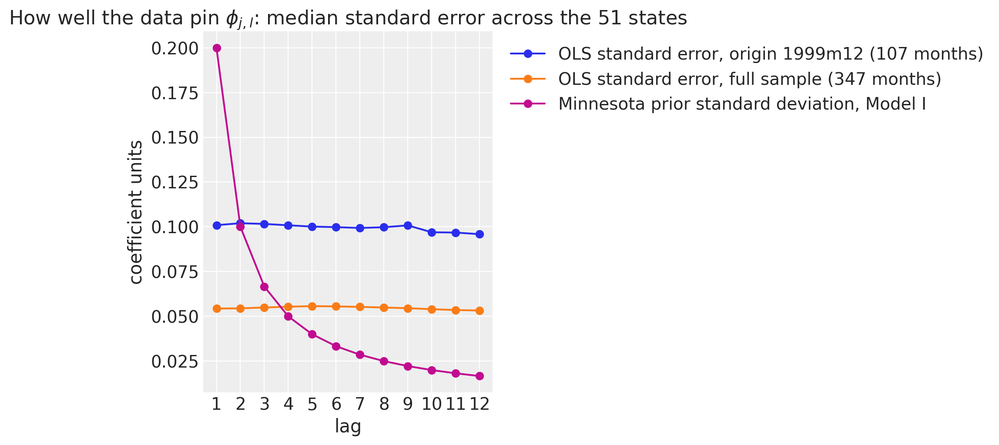

In [13]:
def ols_standard_errors(y_init: Array, y: Array) -> Array:
    """Compute the standard errors of the OLS AR(12) coefficients per state, ``(12, states)``."""
    design = jnp.concatenate(
        [jnp.ones((y.shape[0], 1, y.shape[1])), lag_matrix(y_init, y)], axis=1
    )  # (months, 13, states)
    sigma = ols_ar(y_init, y)[2]  # (states,)
    inverse = jax.vmap(lambda x: jnp.linalg.inv(x.T @ x), in_axes=2, out_axes=0)(design)
    return sigma * jnp.sqrt(jnp.diagonal(inverse, axis1=1, axis2=2)[:, 1:]).T  # (12, states)


se_first = np.median(np.asarray(ols_standard_errors(y_init, growth[:FIRST_ORIGIN])), axis=1)
se_full = np.median(np.asarray(ols_standard_errors(y_init, growth)), axis=1)
lag_axis = np.arange(1, LAGS + 1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    lag_axis,
    se_first,
    marker="o",
    color="C0",
    label="OLS standard error, origin 1999m12 (107 months)",
)
ax.plot(
    lag_axis, se_full, marker="o", color="C1", label="OLS standard error, full sample (347 months)"
)
ax.plot(
    lag_axis,
    np.asarray(minnesota_scale),
    marker="o",
    color="C3",
    label="Minnesota prior standard deviation, Model I",
)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(
    title=r"How well the data pin $\phi_{j, l}$: median standard error across the 51 states",
    xlabel="lag",
    xticks=lag_axis,
    ylabel="coefficient units",
);

The median standard error of an OLS coefficient is $0.10$ at every lag at the first origin and $0.055$ on the full sample: the standard error does not depend on the lag, only on the sample size, and $107$ months give $0.1$. The Minnesota standard deviation is $0.2$ at lag one, above the data's $0.1$, so the prior leaves the first coefficient to the data; it crosses the data at lag two ($0.1$) and falls to $0.017$ at lag twelve, five times tighter than what $107$ months say. From lag three on the prior, not the data, decides the coefficient at the first origin, and even on the full sample the prior wins from lag four on. That is what shrinkage means here: the distant lags, which the OLS fits estimate with noise of $\pm 0.1$, are pinned near zero. Model I is this prior; whether zero is the right place to pin them is the question of the next sections.

### Inference with NUTS

We sample every rung with four NUTS chains, $1{,}000$ warmup iterations and $500$ draws each, $2{,}000$ draws in all; the models with a latent per observation (IV and V) hold a `(months, states)` array per draw, and $2{,}000$ draws keep the posterior of every rung at a few hundred megabytes. Two settings depart from NumPyro's defaults, for reasons the diagnostics confirm:

- `target_accept_prob=0.9` instead of $0.8$, which shortens the leapfrog steps in the hierarchies, where a scale parameter can approach zero.
- `init_strategy=init_to_median(num_samples=20)`: NumPyro's default starts every unconstrained coordinate at a uniform draw in $(-2, 2)$, and the log-variance hyperparameter `log_v_xi` of Model V has a prior mean of $-9.2$ ($\ln 0.01^2$). From the default start the volatility steps begin a factor of about $e^{4}$ too large, and a trial run of Model V did not recover within the warmup ($\hat R = 2.4$ on the volatility hyperparameters, every tree at the maximum depth). The median of twenty prior draws starts every coordinate where the prior puts it.

`fit_nuts` returns the sampler and the wall time, and `fit_title` reads the diagnostics for the figure titles: the number of divergent transitions, the largest $\hat R$ and the smallest effective sample size over the **hyperparameters**, the sites shared by all states, which are the hardest to sample; the titles quote NumPyro's `n_eff` and the summary tables ArviZ's `ess_bulk`, two estimators that differ by a few draws for the same site. `export` turns a fit into an ArviZ `DataTree` with [`to_datatree`](../../reference/convert.to_datatree.html): the posterior with the lag and state coordinates, the in-sample posterior predictive, and the six-month forecast.

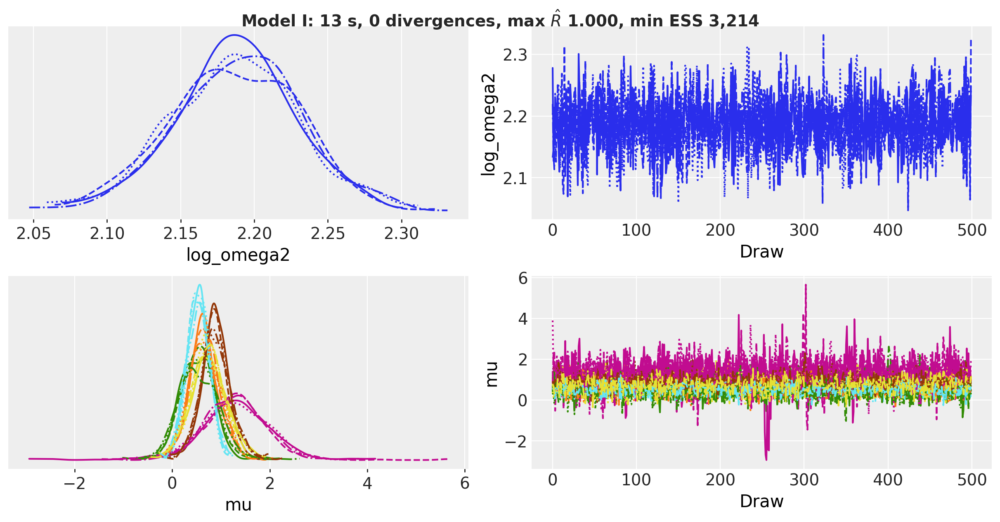

In [14]:
NUM_CHAINS = 4
FULL_WARMUP = 1_000
FULL_SAMPLES = 500
TARGET_ACCEPT = 0.9
INIT_STRATEGY = init_to_median(num_samples=20)


def fit_nuts(
    rng_key: Array,
    model: ForecastModel,
    data: Array,
    *,
    num_warmup: int,
    num_samples: int,
    init_strategy: object = INIT_STRATEGY,
) -> tuple[MCMC, float]:
    """Fit ``model`` with NUTS on ``data`` (the panel is its own covariates) and time it."""
    mcmc = MCMC(
        NUTS(model, target_accept_prob=TARGET_ACCEPT, init_strategy=init_strategy),
        num_warmup=num_warmup,
        num_samples=num_samples,
        num_chains=NUM_CHAINS,
        progress_bar=False,
    )
    start = perf_counter()
    mcmc.run(rng_key, data, data, extra_fields=("diverging", "potential_energy"))
    jax.block_until_ready(mcmc.get_samples())
    return mcmc, perf_counter() - start


HYPER_SITES = (
    "log_omega2",
    "phi_loc",
    "log_v_phi",
    "log_v_sigma",
    "nu_loc",
    "log_v_nu",
    "kappa_loc",
    "log_v_kappa",
    "xi_loc",
    "log_v_xi",
)


def num_divergences(mcmc: MCMC) -> int:
    """Total number of divergent transitions across chains."""
    return int(np.asarray(mcmc.get_extra_fields()["diverging"]).sum())


def divergence_label(count: int) -> str:
    """``"1 divergence"`` or ``"<count> divergences"``."""
    return f"{count} divergence" + ("" if count == 1 else "s")


def diagnostics(mcmc: MCMC, sites: tuple[str, ...] = HYPER_SITES) -> tuple[float, float]:
    """Largest split R-hat and smallest effective sample size over the ``sites`` of the fit."""
    samples = mcmc.get_samples(group_by_chain=True)
    summary = numpyro.diagnostics.summary(
        {site: samples[site] for site in sites if site in samples}, group_by_chain=True
    )
    r_hat = max(float(np.max(stats["r_hat"])) for stats in summary.values())
    ess = min(float(np.min(stats["n_eff"])) for stats in summary.values())
    return r_hat, ess


def fit_title(label: str, mcmc: MCMC, seconds: float) -> str:
    """Title line with the wall time, the divergences, the largest R-hat and the smallest ESS."""
    r_hat, ess = diagnostics(mcmc)
    return (
        f"{label}: {seconds:.0f} s, {divergence_label(num_divergences(mcmc))}, "
        rf"max $\hat{{R}}$ {r_hat:.3f}, min ESS {ess:,.0f}"
    )


time_coord = np.concatenate([dates, future_dates])
posterior_dims = {
    "mu": ["state"],
    "phi": ["lag", "state"],
    "log_sigma2": ["state"],
    "nu": ["state"],
    "kappa": ["state"],
    "mu_t": ["time", "state"],
    "outlier": ["time", "state"],
    "log_var": ["time", "state"],
    "phi_loc": ["lag"],
    "log_v_phi": ["lag"],
}


def export(rng_key: Array, model: ForecastModel, mcmc: MCMC) -> xr.DataTree:
    """Posterior, in-sample predictive and forecast draws as a labeled ArviZ tree."""
    return to_datatree(
        rng_key,
        model,
        mcmc.get_samples(),
        growth,
        covariates_full,
        num_chains=NUM_CHAINS,
        coords={"state": states, "lag": list(range(1, LAGS + 1))},
        time_coord=time_coord,
        posterior_dims=posterior_dims,
        obs_dims=["time", "state"],
    )


rng_key, key_fit, key_tree = random.split(rng_key, 3)
mcmc_1, seconds_1 = fit_nuts(
    key_fit, model_1, growth, num_warmup=FULL_WARMUP, num_samples=FULL_SAMPLES
)
tree_1 = export(key_tree, model_1, mcmc_1)

pc = az.plot_trace_dist(
    tree_1,
    var_names=["log_omega2", "mu"],
    coords={"state": list(SELECTED)},
    compact=True,
    figure_kwargs={"figsize": (12, 6)},
)
pc.viz["figure"].item().suptitle(
    fit_title("Model I", mcmc_1, seconds_1), fontsize=14, fontweight="bold", y=1.03
);

The four chains agree on every parameter: no divergent transition, a largest $\hat R$ of $1.000$ and a smallest effective sample size of $3{,}214$ of $2{,}000$ draws (above the number of draws, because the draws are negatively correlated), in $13$ seconds. The common log scale `log_omega2` sits at $2.19$, which is $\omega = e^{2.19 / 2} = 2.99$ points, the median innovation scale across states; the mean growth rates $\mu_j$ of the six states are between $0.3$ and $1.5$ points per year, with Louisiana the widest, because Katrina widens its posterior.

The trace plot shows the densities; the summary table carries the numbers the text quotes for the scalar hyperparameters of every rung: the posterior mean, the $94\%$ HDI, the $\hat R$ and the effective sample sizes. `hyper_summary` keeps the hyperparameters a rung has (the per-lag sites `phi_loc` and `log_v_phi` have their own figure in the Model II section).

In [15]:
SCALAR_HYPER_SITES = tuple(
    site for site in HYPER_SITES if site not in ("phi_loc", "log_v_phi", "xi_loc")
)


def hyper_summary(tree: xr.DataTree) -> pd.DataFrame:
    """Posterior summary of the scalar hyperparameters present in ``tree``."""
    present = [site for site in SCALAR_HYPER_SITES if site in tree["posterior"].dataset]
    return az.summary(tree, var_names=present, ci_kind="hdi", ci_prob=0.94).round(3)


hyper_summary(tree_1)

,mean,sd,hdi94_lb,hdi94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
log_omega2,2.187,0.043,2.1,2.3,3301,1282,1.00,0.00076,0.0011


Model I has one hyperparameter, the common log scale, at $2.19$ with a $94\%$ HDI of $2.1$ to $2.3$: the median state has an innovation scale of $e^{1.09} \approx 3.0$ points, the value of the OLS residual standard deviations. Everything else in the model is state specific.

### Posterior predictive check

The in-sample posterior predictive of an AR model is the **one-step-ahead** distribution: for every month, the model's distribution of $y_{j,t}$ given the twelve observed months before it and a posterior draw of the parameters. `export` drew it with [`predict_in_sample`](../../reference/predictive.predict_in_sample.html); we plot its bands against the data for Louisiana and West Virginia.

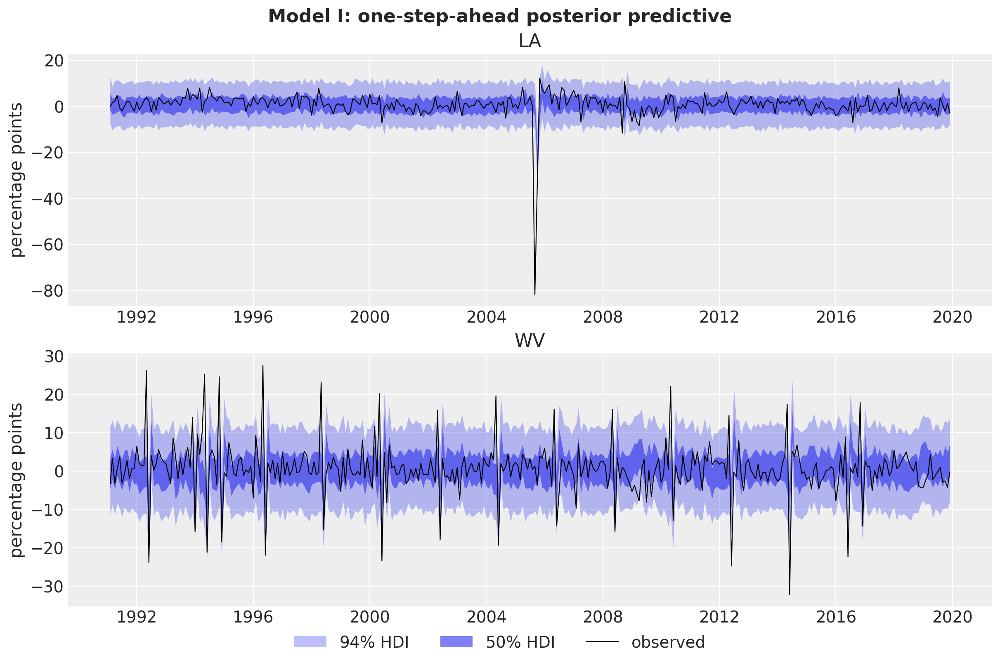

In [16]:
def stack_draws(variable: xr.DataArray) -> np.ndarray:
    """Posterior draws of a ``(chain, draw, time, ...)`` variable as ``(sample, time, ...)``."""
    return variable.stack(sample=("chain", "draw")).transpose("sample", "time", ...).to_numpy()


def plot_in_sample(
    tree: xr.DataTree, label: str, state_names: tuple[str, ...] = ("LA", "WV")
) -> None:
    """One-step-ahead posterior predictive bands of ``tree`` against the data, one panel per state."""
    draws = stack_draws(tree["posterior_predictive"]["obs"].sel(state=list(state_names)))
    pc, handles = plot_bands(draws, date_num, list(state_names), figsize=(12, 8))
    fig = pc.viz["figure"].item()

    for ax, state in zip(fig.axes, state_names, strict=True):
        (line,) = ax.plot(
            date_num, growth[:, states.index(state)], color="black", lw=0.8, label="observed"
        )
        ax.set(title=state, ylabel="percentage points")

    fig.legend(handles=[*handles, line], loc="outside lower center", ncols=3)
    fig.suptitle(f"{label}: one-step-ahead posterior predictive", fontsize=16, fontweight="bold")


plot_in_sample(tree_1, "Model I")

In Louisiana the $94\%$ band is about $\pm 9$ points wide around the one-step mean and the data stay inside it, with two exceptions: 2005m9, where the band reaches $-10$ and the observation is $-82$, and 2005m10, where the band reaches $-20$ and the observation is $-34$. The band also widens for the twelve months that Katrina sits in the lag window, because the AR coefficients carry the shock forward into the mean, which is the propagation an innovation outlier produces. In West Virginia the band is $\pm 12$ points and the observed series breaks out of it about twenty times in 347 months, every time at one of the mining spikes, in both directions. A Normal one-step predictive with one scale per state has the right width for the ordinary months and no room for the spikes; the tail check of the Model II section turns that into a number.

The check that motivates Model II is what the posterior of Model I says across states. The Minnesota prior centers every coefficient at zero; if the 51 posteriors agree on a nonzero value at some lag, the prior is centered in the wrong place, and a prior centered where the states agree would shrink each state toward a better value. The figure shows the posterior means of $\phi_{j,l}$ of the 51 states at each lag, with the prior standard deviation of Model I as a band.

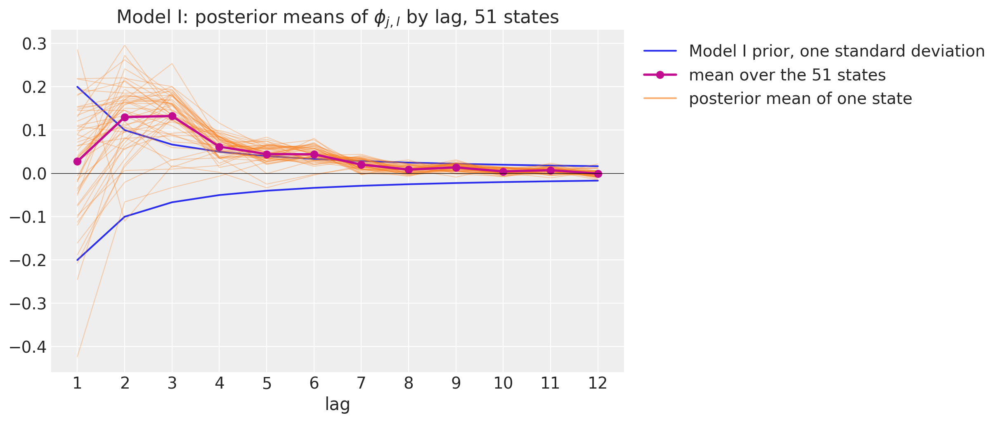

In [17]:
phi_means_1 = tree_1["posterior"]["phi"].mean(("chain", "draw")).to_numpy()  # (12, states)
lag_axis = np.arange(1, LAGS + 1)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    lag_axis,
    np.asarray(minnesota_scale),
    color="C0",
    lw=1.5,
    label="Model I prior, one standard deviation",
)
ax.plot(lag_axis, -np.asarray(minnesota_scale), color="C0", lw=1.5)
ax.plot(lag_axis, phi_means_1, color="C1", alpha=0.3, lw=0.8)
ax.plot(
    lag_axis,
    phi_means_1.mean(axis=1),
    color="C3",
    lw=2,
    marker="o",
    label="mean over the 51 states",
)
ax.plot([], [], color="C1", alpha=0.6, label="posterior mean of one state")
ax.axhline(0.0, color="black", lw=0.5)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(
    title=r"Model I: posterior means of $\phi_{j, l}$ by lag, 51 states",
    xlabel="lag",
    xticks=lag_axis,
);

The 51 posterior means agree on a shape the prior does not have. At lag one they spread from $-0.4$ to $+0.3$ with a mean of $0.03$, inside the prior's $\pm 0.2$; at lags two and three they cluster at $0.13$, one to two prior standard deviations above the prior's center of zero, and at lags four to six they sit at $0.04$ to $0.06$, above the band at every lag. The agreement across states is the signal: if 51 states, estimated separately, all put the second and third coefficients near $0.13$, a prior centered at zero shrinks every one of them in the wrong direction. Model II lets the data move the center.

## Model II: hierarchical priors

Model II keeps the likelihood of Model I and replaces the fixed priors on $\phi_{j,l}$ and $\ln \sigma_j^2$ with **hierarchical priors**: the center and the spread of the prior at each lag are parameters, estimated from the 51 states together. The paper writes a hierarchical Normal prior as $\text{HN}(m_m, v_m, m_{\ln v}, v_{\ln v})$, meaning

$$
\theta_j \mid m, v \sim \text{Normal}(m, v), \qquad m \sim \text{Normal}(m_m, v_m), \qquad \ln v \sim \text{Normal}(m_{\ln v}, v_{\ln v}),
$$

with $v$ a variance, and uses

$$
\begin{align*}
\{\phi_{j,l}\}_j &\sim \text{HN}\!\left(0, \; 0.5^2 (0.2/l)^2, \; \ln (0.2/l)^2, \; 0.5^2\right), \\
\{\ln \sigma_j^2\}_j &\sim \text{HN}\!\left(\ln \omega^2, \; \cdot, \; \ln 0.3^2, \; 0.5^2\right).
\end{align*}
$$

In words: the center $m_l$ of the coefficients at lag $l$ has a prior standard deviation of half the Minnesota scale ($0.1$ at lag one), so the data can move it away from zero, and the spread $v_l$ of the states around that center is centered at the Minnesota variance with a factor of $e^{\pm 0.5}$ of play. The location of the $\ln \sigma_j^2$ hierarchy is the common scale, which the paper gives a flat prior and a $\text{Normal}(0, 0.5^2)$ prior on the offset of the hierarchy center from it; the two enter the likelihood only through their sum, so `log_omega2` stands for the sum. The spread of the scales around the common one is now learned, centered at the $0.3^2$ of Model I.

The sampler sees the coefficient hierarchy in non-centered form, as the model function shows: `phi_z` is standard Normal and `phi` is deterministic; the scale hierarchy is centered. The posterior of `phi_loc` and `log_v_phi` is the estimated prior of the paper's Figure 3.

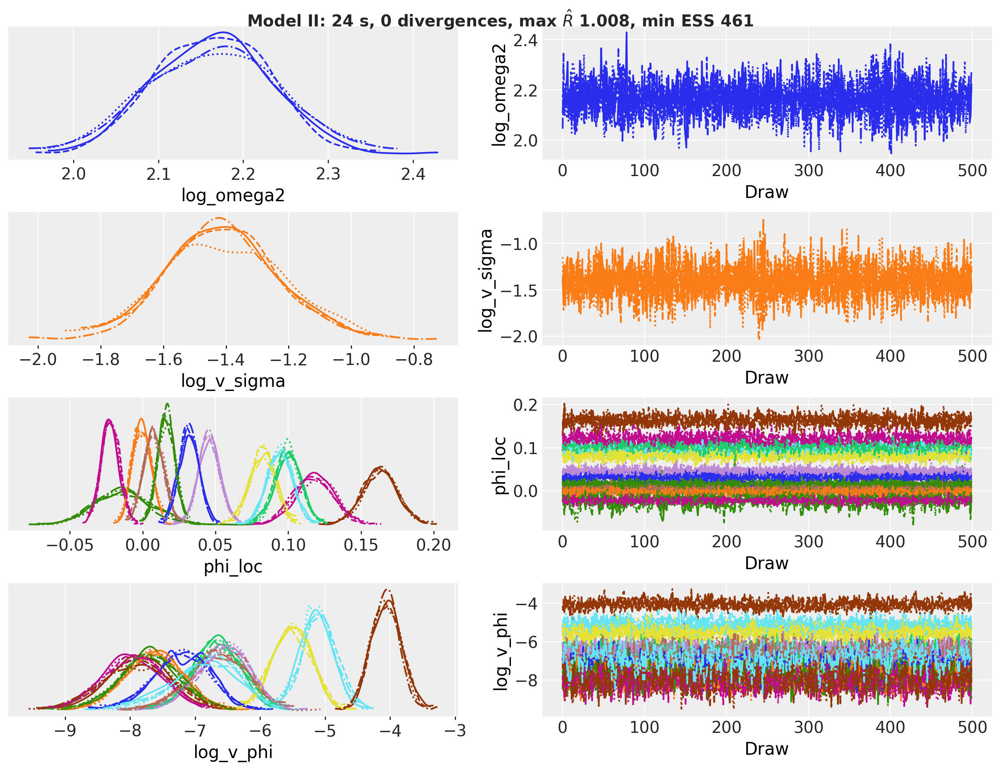

In [18]:
model_2 = make_rts_model(y_init)
rng_key, key_fit, key_tree = random.split(rng_key, 3)
mcmc_2, seconds_2 = fit_nuts(
    key_fit, model_2, growth, num_warmup=FULL_WARMUP, num_samples=FULL_SAMPLES
)
tree_2 = export(key_tree, model_2, mcmc_2)

pc = az.plot_trace_dist(
    tree_2,
    var_names=["log_omega2", "log_v_sigma", "phi_loc", "log_v_phi"],
    compact=True,
    figure_kwargs={"figsize": (12, 9)},
)
pc.viz["figure"].item().suptitle(
    fit_title("Model II", mcmc_2, seconds_2), fontsize=14, fontweight="bold", y=1.02
);

No divergent transition in $24$ seconds, a largest $\hat R$ of $1.008$ and a smallest effective sample size of $461$. The twelve `phi_loc` densities stack from $-0.02$ to $0.16$ and the four chains overlap on each; the `log_v_phi` densities, the log spreads around those centers, are near $-4$ for lag one and between $-5$ and $-8$ for the others, which means a spread of $0.14$ at lag one and $0.02$ to $0.08$ at the other lags. The common log scale and the spread of the state scales have the widest densities of the figure, and both are well mixed, which is what the centered form of the scale hierarchy buys.

In [19]:
hyper_summary(tree_2)

,mean,sd,hdi94_lb,hdi94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
log_omega2,2.164,0.071,2,2.3,3769,1310,1.01,0.0012,0.002
log_v_sigma,-1.409,0.18,-1.7,-1,4303,1749,1.00,0.0028,0.0051


The common log scale is $2.16$ ($94\%$ HDI $2.0$ to $2.3$), the same median scale of $3$ points as in Model I, and the log variance of the state scales around it is $-1.41$ ($-1.7$ to $-1.0$): a standard deviation of $e^{-0.7} \approx 0.5$ for $\ln \sigma_j^2$, so the states' variances spread over a factor of about $e^{\pm 0.5}$ around the common one (the scales over $e^{\pm 0.25}$), against the $e^{\pm 0.3}$ on the variance that Model I fixed. Both have effective sample sizes above $3{,}700$ and $\hat R$ at $1.00$ to $1.01$.

The paper's Figure 3 compares the prior of Model I with the estimated prior of Model II, $\text{Normal}(m_l, v_l)$ at the posterior mean of $m_l$ and $\ln v_l$. We draw both for every lag.

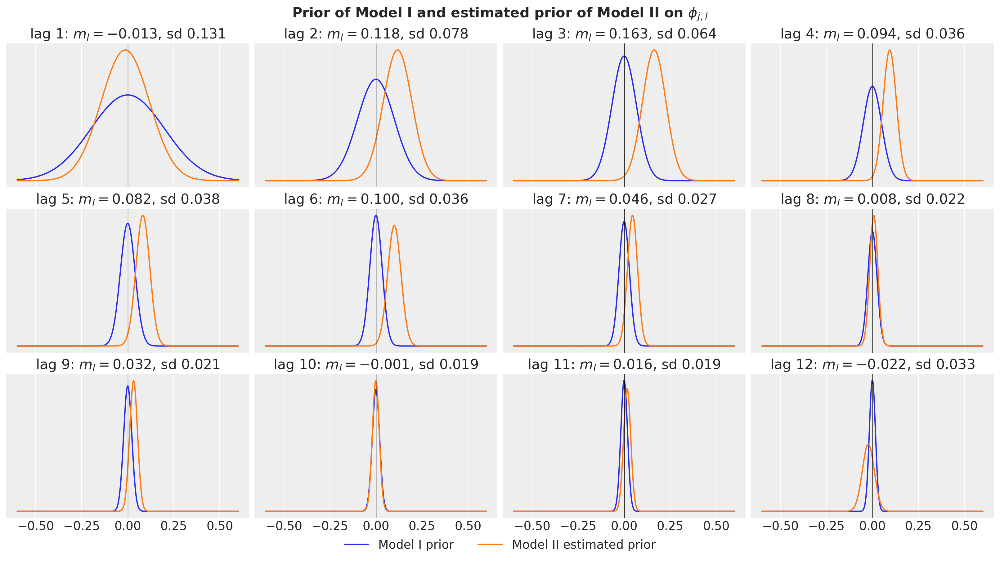

In [20]:
posterior_2 = tree_2["posterior"].dataset
phi_loc_mean = posterior_2["phi_loc"].mean(("chain", "draw")).to_numpy()  # (12,)
phi_sd_mean = np.exp(0.5 * posterior_2["log_v_phi"].mean(("chain", "draw")).to_numpy())  # (12,)
grid = np.linspace(-0.6, 0.6, 400)

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(16, 9), sharex=True, layout="constrained")

for ax, lag in zip(axes.flat, lag_axis, strict=True):
    prior_1 = pz.Normal(0.0, float(minnesota_scale[lag - 1])).pdf(grid)
    prior_2 = pz.Normal(float(phi_loc_mean[lag - 1]), float(phi_sd_mean[lag - 1])).pdf(grid)
    ax.plot(grid, prior_1, color="C0", label="Model I prior")
    ax.plot(grid, prior_2, color="C1", label="Model II estimated prior")
    ax.axvline(0.0, color="black", lw=0.5)
    ax.set(
        title=rf"lag {lag}: $m_l = {phi_loc_mean[lag - 1]:.3f}$, sd ${phi_sd_mean[lag - 1]:.3f}$",
        yticks=[],
    )

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=2)
fig.suptitle(
    r"Prior of Model I and estimated prior of Model II on $\phi_{j, l}$",
    fontsize=16,
    fontweight="bold",
);

The estimated prior of Model II is the paper's Figure 3 with the same shape: at lag one the center stays at zero ($m_1 = -0.013$) and the spread narrows from $0.20$ to $0.13$, while at lags two to six the center moves to $0.12$, $0.16$, $0.09$, $0.08$ and $0.10$ with spreads of $0.04$ to $0.08$, so the estimated prior sits to the right of the Minnesota prior there, at lags three and four with little overlap. The paper describes exactly this: shrinkage toward nonzero values at lags two through six. From lag seven on the center is within $0.05$ of zero and the two priors nearly coincide, except at lag twelve, where the estimated spread ($0.033$) is twice the Minnesota one.

Partial pooling moves each state's coefficients from its own OLS estimate toward the common center, by an amount that depends on how precisely the state's data pin them. The scatter of the posterior means of Model II against the OLS estimates at lags one and two shows the pull.

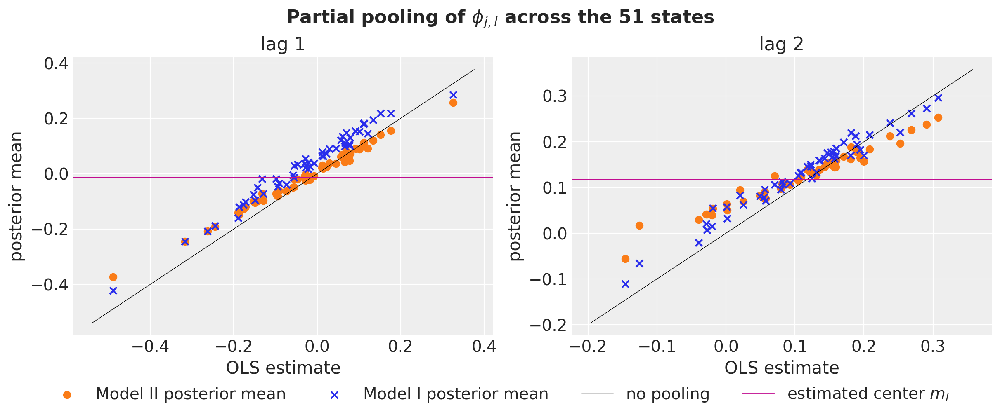

In [21]:
phi_means_2 = posterior_2["phi"].mean(("chain", "draw")).to_numpy()  # (12, states)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5), layout="constrained")

for ax, lag in zip(axes, (1, 2), strict=True):
    ols_values = np.asarray(ols_phi[lag - 1])
    ax.scatter(ols_values, phi_means_2[lag - 1], color="C1", label="Model II posterior mean")
    ax.scatter(
        ols_values, phi_means_1[lag - 1], color="C0", marker="x", label="Model I posterior mean"
    )
    limits = (
        min(ols_values.min(), phi_means_2[lag - 1].min()) - 0.05,
        max(ols_values.max(), phi_means_2[lag - 1].max()) + 0.05,
    )
    ax.plot(limits, limits, color="black", lw=0.5, label="no pooling")
    ax.axhline(phi_loc_mean[lag - 1], color="C3", lw=1, label=r"estimated center $m_l$")
    ax.set(title=f"lag {lag}", xlabel="OLS estimate", ylabel="posterior mean")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=4)
fig.suptitle(
    r"Partial pooling of $\phi_{j, l}$ across the 51 states", fontsize=16, fontweight="bold"
);

Each point is a state. At lag one the Model II posterior means (orange) lie on a line flatter than the diagonal: a state with an OLS estimate of $0.3$ ends at $0.25$ and one at $-0.5$ at $-0.37$, pulled toward the center $m_1 \approx 0$ by about a quarter of the distance, while the Model I means (blue crosses) stay closer to the diagonal. At lag two the center is $0.12$ and the pull is stronger: the OLS estimates run from $-0.15$ to $0.3$, the posterior means from $-0.06$ to $0.25$, and the two states at $-0.15$ move the most, by about $0.1$. The pull is largest where the OLS estimate is farthest from the center and smallest near it, which is partial pooling: the common center is a second source of information about each state, weighted against the state's own 347 months.

### The check that motivates Model III: the tails

The one-step predictive of Models I and II is Normal. The **standardized one-step error** of month $t$ in state $j$ under a posterior draw is $e_{j,t} = (y_{j,t} - \mu_{j,t}) / \sigma_j$ with $\mu_{j,t}$ the one-step mean of that draw; under the model it is a standard Normal, and the share of errors beyond four standard deviations is $6 \times 10^{-5}$. The posterior predictive check compares that share in the data with the share in replicated data from the model: for every posterior draw we compute the share on the observed panel and the share on a replicated panel drawn from the one-step predictive. `tail_share` is the statistic and `check_statistic` runs it on a tree; both are used again for the later rungs, so the check is defined once here. `standardized_errors` reads the draws of the one-step mean and scale from the posterior group, subtracting the additive outliers when the rung has them, so that the statistic measures the innovation tails in every rung.

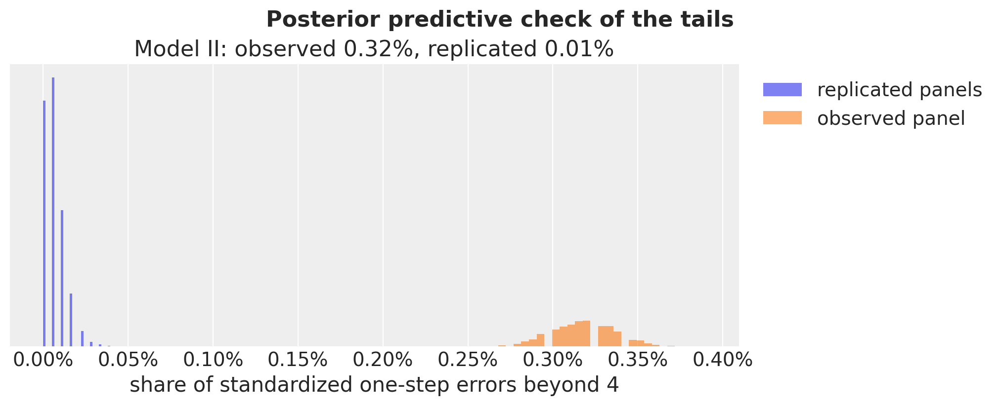

In [22]:
def standardized_errors(tree: xr.DataTree, y: np.ndarray) -> np.ndarray:
    """Standardized one-step errors ``(sample, time, state)`` of ``y`` under every draw of ``tree``."""
    posterior = tree["posterior"].dataset
    mean = stack_draws(posterior["mu_t"])  # (sample, time, state)
    if "outlier" in posterior:
        mean = mean + stack_draws(posterior["outlier"])
    if "log_var" in posterior:
        scale = np.exp(0.5 * stack_draws(posterior["log_var"]))  # (sample, time, state)
    else:
        scale = np.exp(
            0.5
            * posterior["log_sigma2"]
            .stack(sample=("chain", "draw"))
            .transpose("sample", "state")
            .to_numpy()
        )[:, None, :]
    return (y - mean) / scale


def tail_share(errors: np.ndarray, threshold: float = 4.0) -> np.ndarray:
    """Share of standardized errors beyond ``threshold`` in absolute value, per sample."""
    return (np.abs(errors) > threshold).mean(axis=(1, 2))


def check_statistic(
    tree: xr.DataTree, statistic: Callable[..., np.ndarray], **kwargs: object
) -> tuple[np.ndarray, np.ndarray]:
    """``statistic`` of the observed panel and of the replicated panels, per posterior draw."""
    observed = statistic(standardized_errors(tree, np.asarray(growth)), **kwargs)
    replicated = statistic(
        standardized_errors(tree, stack_draws(tree["posterior_predictive"]["obs"])), **kwargs
    )
    return observed, replicated


def plot_check(
    ax: plt.Axes, observed: np.ndarray, replicated: np.ndarray, label: str, *, xlabel: str
) -> None:
    """Histogram of the replicated statistic with the observed one as a line, per draw."""
    ax.hist(replicated, bins=30, color="C0", alpha=0.6, density=True, label="replicated panels")
    ax.hist(observed, bins=30, color="C1", alpha=0.6, density=True, label="observed panel")
    ax.set(
        title=f"{label}: observed {np.median(observed):.2%}, replicated {np.median(replicated):.2%}",
        xlabel=xlabel,
        yticks=[],
    )


tail_observed_2, tail_replicated_2 = check_statistic(tree_2, tail_share)

fig, ax = plt.subplots(figsize=(10, 4))
plot_check(
    ax,
    tail_observed_2,
    tail_replicated_2,
    "Model II",
    xlabel="share of standardized one-step errors beyond 4",
)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=2))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.suptitle("Posterior predictive check of the tails", fontsize=16, fontweight="bold");

The check fails by a factor of thirty. In the observed panel $0.32\%$ of the standardized one-step errors are beyond four, about $57$ of the $17{,}697$ months; in the replicated panels the share is $0.01\%$, one or two months, as the Normal predicts. The two histograms do not touch. The errors beyond four are the mining spikes of West Virginia, Katrina, and a handful of months in other states, and a Normal with one scale per state cannot produce them. The next rung gives the innovations heavier tails.

## Model III: Student-t innovations

The tails of the data are heavier than the Normal one-step predictive allows. Model III replaces the innovation distribution with a Student-t with state-specific degrees of freedom $\nu_j$,

$$
\varepsilon_{j,t} \sim \text{StudentT}(\nu_j), \qquad \{\ln(\nu_j - 2)\}_j \sim \text{HN}\!\left(\ln 10, \; 0.5^2, \; \ln 0.5^2, \; 0.5^2\right).
$$

The transformation $\ln(\nu_j - 2)$ keeps $\nu_j$ above $2$, where the variance of a Student-t exists; the center $\ln 10$ puts the prior median of $\nu_j$ at $12$, close to Normal, and the two spreads let the data pull it down. A Student-t with $\nu = 5$ puts $1.0\%$ of its mass beyond four scale units against the Normal's $0.006\%$, and with $\nu = 3$ the share is $2.8\%$. An innovation outlier of this kind **propagates**: a large $\varepsilon_{j,t}$ enters $u_{j,t}$ and, through the AR coefficients, the next twelve months. One numerical guard sits in the model function: `make_rts_model` caps $\ln(\nu_j - 2)$ at `MAX_LOG_NU = 8.0`, that is $\nu_j \le 2 + e^8 \approx 3{,}000$. Above that a Student-t is a Normal to float32 precision, and NumPyro's `StudentT.log_prob` in float32 is wrong there (at $\nu = e^{11}$ its log density of the panel is off by several hundred nats, with a gradient of the wrong sign), which trapped one chain of a backtest fit in a spurious mode during warmup. The cap is more than ten prior standard deviations above the prior center, so it changes no posterior. The prior on $\nu_j$ is on a transformed scale, so we draw it to see what it says about $\nu_j$ itself.

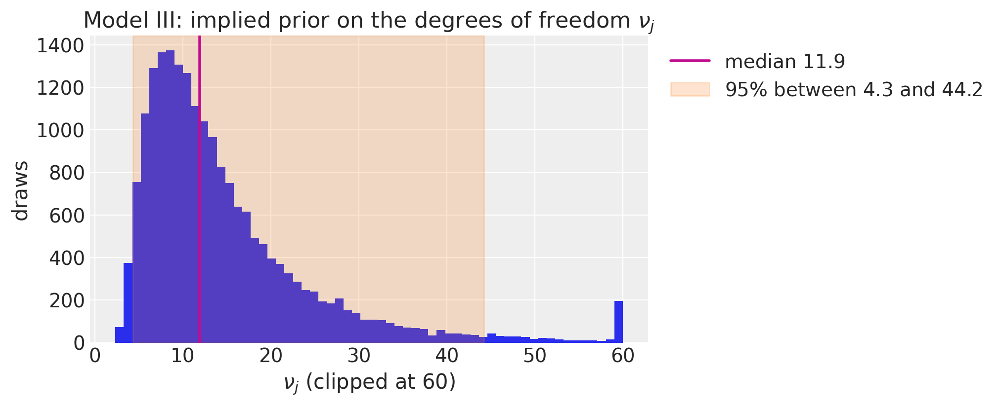

In [23]:
rng_key, key_prior = random.split(rng_key)
key_m, key_v, key_z = random.split(key_prior, 3)
prior_nu_loc = jnp.log(10.0) + 0.5 * random.normal(key_m, (20_000,))
prior_nu_sd = jnp.exp(0.5 * (jnp.log(0.25) + 0.5 * random.normal(key_v, (20_000,))))
prior_nu = 2.0 + jnp.exp(prior_nu_loc + prior_nu_sd * random.normal(key_z, (20_000,)))
nu_quantiles = np.quantile(np.asarray(prior_nu), (0.025, 0.5, 0.975))

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(np.clip(np.asarray(prior_nu), 2.0, 60.0), bins=60, color="C0")
ax.axvline(nu_quantiles[1], color="C3", lw=2, label=f"median {nu_quantiles[1]:.1f}")
ax.axvspan(
    nu_quantiles[0],
    nu_quantiles[2],
    color="C1",
    alpha=0.2,
    label=rf"$95\%$ between {nu_quantiles[0]:.1f} and {nu_quantiles[2]:.1f}",
)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(
    title=r"Model III: implied prior on the degrees of freedom $\nu_j$",
    xlabel=r"$\nu_j$ (clipped at 60)",
    ylabel="draws",
);

The implied prior on $\nu_j$ has a median of $12$ and puts $95\%$ of its mass between $4.3$ and $44$; the paper quotes $4$ to $30$ for the same prior, and the difference is in the upper tail, where the two spreads of the hierarchy compound. Above $30$ a Student-t is close to Normal, so the prior allows near-Normal innovations and heavy tails alike, with its center on the Normal side; a posterior that lands at $\nu_j = 4$ or $5$ has moved against the prior, and the data have to earn that.

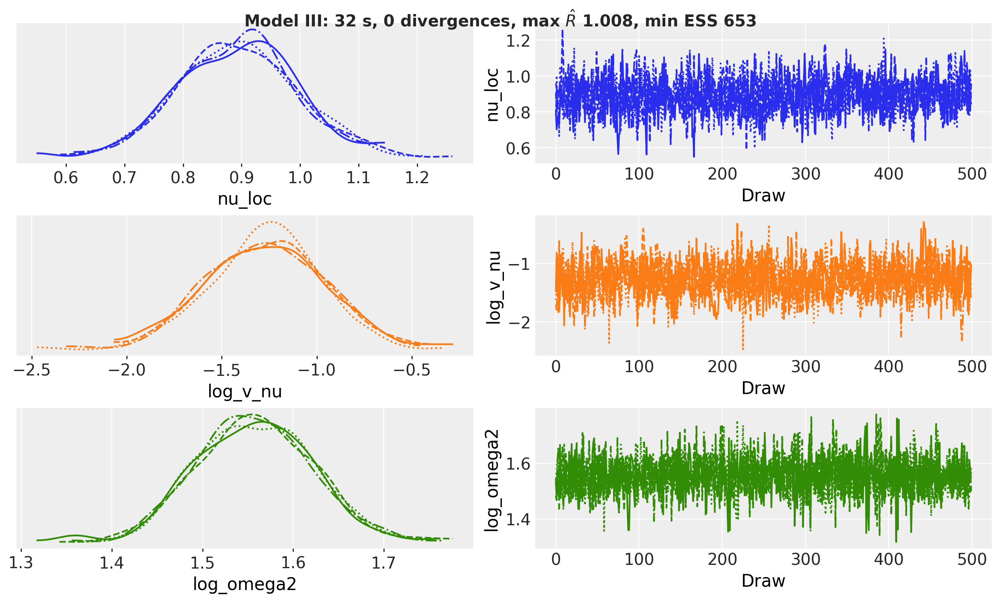

In [24]:
model_3 = make_rts_model(y_init, student_t=True)
rng_key, key_fit, key_tree = random.split(rng_key, 3)
mcmc_3, seconds_3 = fit_nuts(
    key_fit, model_3, growth, num_warmup=FULL_WARMUP, num_samples=FULL_SAMPLES
)
tree_3 = export(key_tree, model_3, mcmc_3)

pc = az.plot_trace_dist(
    tree_3,
    var_names=["nu_loc", "log_v_nu", "log_omega2"],
    compact=True,
    figure_kwargs={"figsize": (12, 7)},
)
pc.viz["figure"].item().suptitle(
    fit_title("Model III", mcmc_3, seconds_3), fontsize=14, fontweight="bold", y=1.02
);

No divergent transition in $2{,}000$ draws, a largest $\hat R$ of $1.008$ and a smallest effective sample size of $653$, in $32$ seconds. `nu_loc`, the center of the $\ln(\nu_j - 2)$ hierarchy, sits at $0.9$, which is a common degrees of freedom of $2 + e^{0.9} = 4.5$ against the prior median of $12$; the common log scale moves from $2.16$ to $1.56$, because the Student-t scale is not the standard deviation (a Student-t with $4.5$ degrees of freedom has a standard deviation $1.3$ times its scale), so the two are not comparable.

In [25]:
hyper_summary(tree_3)

,mean,sd,hdi94_lb,hdi94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
log_omega2,1.557,0.066,1.4,1.7,3463,1694,1.00,0.0011,0.0018
log_v_sigma,-1.696,0.189,-2,-1.3,3341,1655,1.00,0.0033,0.0043
nu_loc,0.893,0.099,0.71,1.1,1562,1529,1.00,0.0025,0.002
log_v_nu,-1.27,0.3,-1.8,-0.71,1050,1455,1.00,0.0094,0.0059


The hyperparameters of the degrees of freedom are `nu_loc` at $0.89$ ($94\%$ HDI $0.71$ to $1.1$), a common $\nu$ of $4.4$ with the interval $4.0$ to $5.0$, and `log_v_nu` at $-1.27$, a spread of $e^{-0.64} \approx 0.53$ in $\ln(\nu_j - 2)$ across states, close to the prior median of $0.5$. The effective sample sizes are above $1{,}000$ for every row.

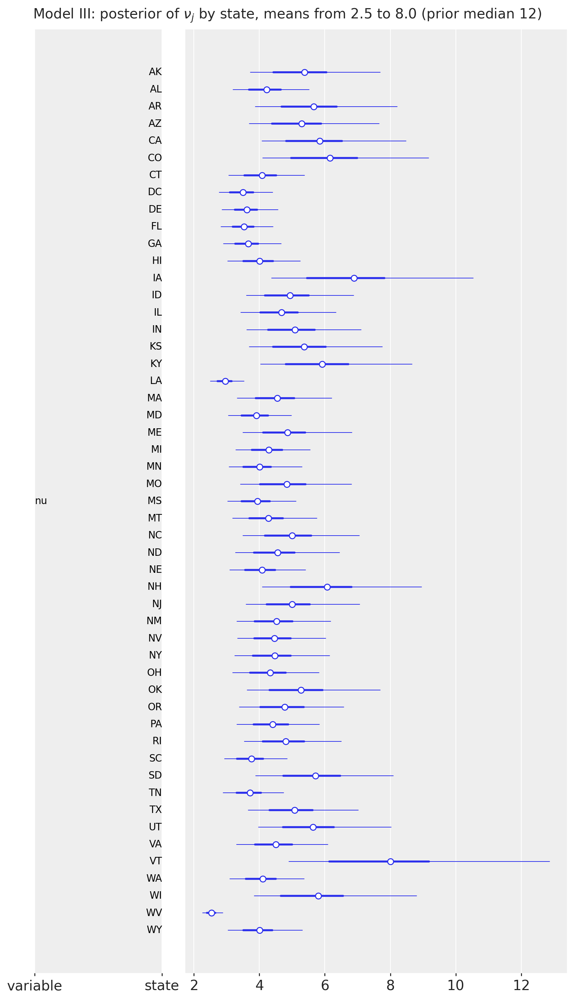

In [26]:
pc = az.plot_forest(tree_3, var_names=["nu"], combined=True, figure_kwargs={"figsize": (8, 14)})
nu_means = tree_3["posterior"]["nu"].mean(("chain", "draw")).to_numpy()
pc.viz["figure"].item().suptitle(
    rf"Model III: posterior of $\nu_j$ by state, means from {nu_means.min():.1f} "
    + rf"to {nu_means.max():.1f} (prior median {nu_quantiles[1]:.0f})",
    fontsize=14,
);

The posterior means of $\nu_j$ (the dots; the lines are the $50\%$ and $94\%$ intervals) run from $2.5$ in West Virginia to $8.0$ in Vermont, every one of them below the prior median of $12$; the paper's Figure 4 has them between $3$ and $7$, and here West Virginia ($2.5$) and Louisiana ($2.9$) sit below that range and Vermont above it; the $94\%$ intervals reach $10$ to $13$ only for the few states with the lightest tails (Iowa, Vermont, New Hampshire). Louisiana ($2.9$) and West Virginia ($2.5$) are at the bottom and have the narrowest intervals, because their spikes pin the tail. For most states the interval runs from about $3$ to $7$: the innovations of state employment growth are far from Normal, and $347$ months decide that for every state on its own, with the hierarchy pulling the uncertain ones toward the common value near $4.4$.

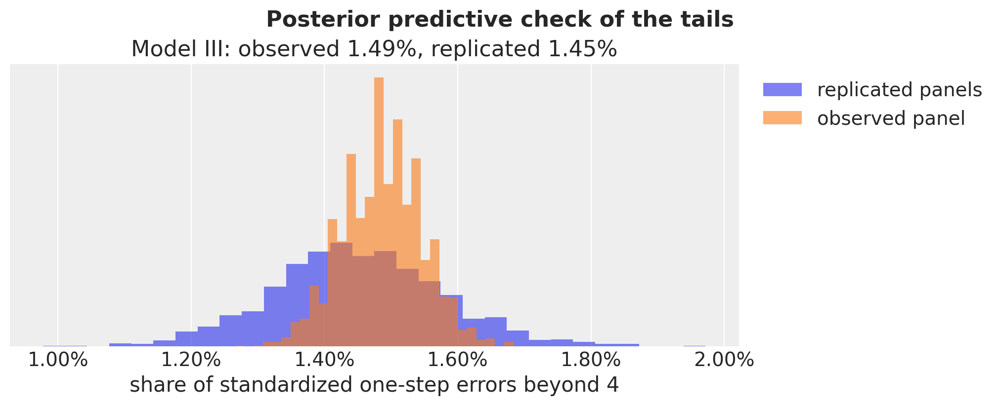

In [27]:
tail_observed_3, tail_replicated_3 = check_statistic(tree_3, tail_share)

fig, ax = plt.subplots(figsize=(10, 4))
plot_check(
    ax,
    tail_observed_3,
    tail_replicated_3,
    "Model III",
    xlabel="share of standardized one-step errors beyond 4",
)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=2))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.suptitle("Posterior predictive check of the tails", fontsize=16, fontweight="bold");

With Student-t innovations the check passes: $1.49\%$ of the standardized errors are beyond four in the observed panel and $1.45\%$ in the replicated ones, and the two histograms overlap. The share is larger than under Model II ($0.32\%$) because the errors are now standardized by the Student-t scale, which is smaller than the Normal standard deviation of the same data; the check asks whether the model reproduces the share, and it does.

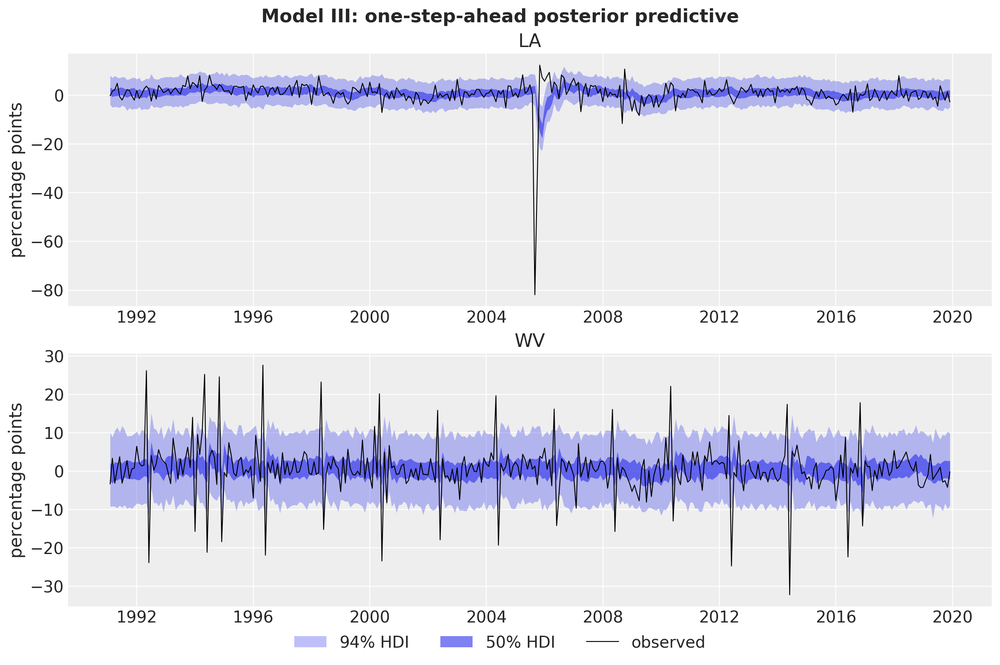

In [28]:
plot_in_sample(tree_3, "Model III")

The Student-t bands are narrower in the body and the data break out of them more often, which is the right behavior: a Student-t with $\nu \approx 3$ puts its mass near the center and the rare spikes in tails that a $94\%$ band does not try to cover. In Louisiana the band still widens for the months after Katrina, to about $-22$ to $+8$ in 2005m10, through the posterior of $\phi_{j,1} \times 82$ rather than through the scale; the shock propagates through the lag window, as the next check shows. In West Virginia the $94\%$ band is $\pm 10$ points and the spikes of $\pm 20$ stand outside it, as they should under a heavy-tailed model.

### The check that motivates Model IV: what follows a large shock

A Student-t innovation at month $t$ propagates: the model expects month $t+1$ to carry $\phi_{j,1}$ times the shock, and the standardized error of month $t+1$ is centered at zero only if it does. An **additive outlier**, a one-month spike that does not carry over, breaks that expectation: after a spike of size $A$ the next month returns to its level, so the one-step error of month $t+1$ is about $-\phi_{j,1} A$, a reversal. The statistic is the mean of $e_{j,t+1} \, \text{sign}(e_{j,t})$ over the twenty largest absolute standardized errors of the panel: near zero if large shocks propagate as the model says, negative if they reverse.

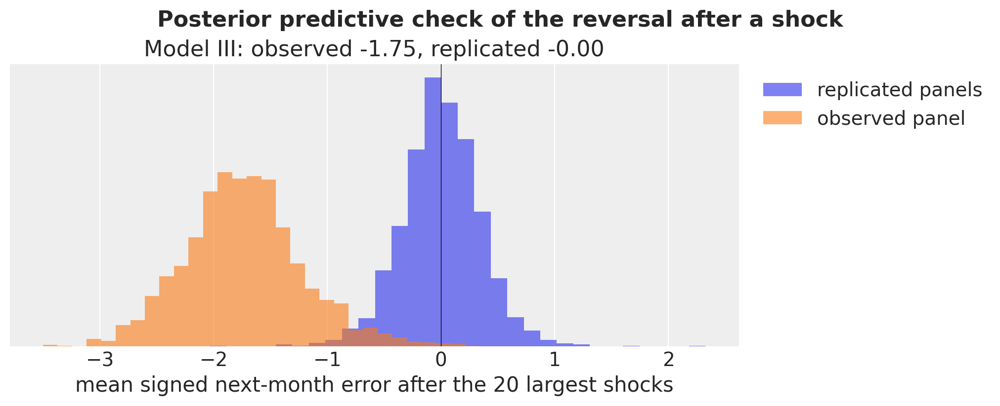

In [29]:
def reversal(errors: np.ndarray, num_shocks: int = 20) -> np.ndarray:
    """Mean of the signed next-month error after the ``num_shocks`` largest shocks, per sample."""
    num_samples = errors.shape[0]
    current = errors[:, :-1, :].reshape(num_samples, -1)  # (sample, (time - 1) * state)
    following = errors[:, 1:, :].reshape(num_samples, -1)
    largest = np.argpartition(-np.abs(current), num_shocks, axis=1)[:, :num_shocks]
    signed = np.take_along_axis(following, largest, axis=1) * np.sign(
        np.take_along_axis(current, largest, axis=1)
    )
    return signed.mean(axis=1)


def plot_reversal(ax: plt.Axes, tree: xr.DataTree, label: str) -> None:
    """Plot the reversal statistic of ``tree``: replicated histogram and observed values."""
    observed, replicated = check_statistic(tree, reversal)
    ax.hist(replicated, bins=30, color="C0", alpha=0.6, density=True, label="replicated panels")
    ax.hist(observed, bins=30, color="C1", alpha=0.6, density=True, label="observed panel")
    ax.axvline(0.0, color="black", lw=0.5)
    ax.set(
        title=f"{label}: observed {np.median(observed):.2f}, replicated {np.median(replicated):.2f}",
        xlabel="mean signed next-month error after the 20 largest shocks",
        yticks=[],
    )


fig, ax = plt.subplots(figsize=(10, 4))
plot_reversal(ax, tree_3, "Model III")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.suptitle(
    "Posterior predictive check of the reversal after a shock", fontsize=16, fontweight="bold"
);

The check fails. After the twenty largest shocks the observed next-month error, signed by the shock, is $-1.75$ standard units on average; in the replicated panels it is $-0.00$, and the two histograms do not overlap. Large shocks in these data are followed by a move in the opposite direction, which an innovation that propagates through the AR coefficients never produces: after a spike of $+25$ points the model expects month $t + 1$ near $\phi_{j,1} \times 25$, and the data come back to the level. That pattern is what an additive outlier produces, and Model IV adds a component for it.

## Model IV: additive outliers

Model IV adds a second kind of outlier, one that does not propagate. The observation becomes

$$
y_{j,t} = \mu_j + u_{j,t} + o_{j,t}, \qquad o_{j,t} = \kappa_j \, \eta_{j,t}, \qquad \eta_{j,t} \sim \text{StudentT}(\nu^o_j),
$$

where $o_{j,t}$ is the **additive outlier** of month $t$: it moves $y_{j,t}$ and nothing else, because the AR recursion runs on $u_{j,t} = y_{j,t} - \mu_j - o_{j,t}$ and the outlier never enters the lag window (the model function subtracts `outlier` from the series it hands to `ssoe`). $\kappa_j$ is the **outlier scale** of state $j$ and $\nu^o_j$ the degrees of freedom of the outlier distribution. The paper's priors are

$$
\begin{align*}
\{\ln \kappa_j^2\}_j &\sim \text{HN}\!\left(\ln 0.1^2, \; 0.5^2, \; \ln 0.3^2, \; 0.5^2\right) \quad \text{relative to } \omega, \\
\{\ln(\nu^o_j - 2)\}_j &\sim \text{HN}\!\left(\ln 2, \; 0.5^2, \; \ln 0.5^2, \; 0.5^2\right).
\end{align*}
$$

The prior median of $\kappa_j$ is a tenth of the common scale, about $0.3$ percentage points: most months the outlier component is a small noise, and the Student-t tails of $\eta_{j,t}$ produce the occasional large one. With the common scale absorbed into `log_omega2`, the center of the $\kappa$ hierarchy is `log_omega2` $+ \ln 0.1^2$ and its variance is the sum of the paper's two $0.5^2$ (the $\ln \kappa^2$ center and the $\ln \sigma^2$ center are both relative to $\omega$, and only their difference is identified), as the model function notes.

Two departures from the paper are in this rung, both forced by the sampler:

- $\nu^o_j$ is fixed at $4$, the paper's prior median. The latent $\eta_{j,t}$ has one value per month and state, $17{,}697$ in all, and the hyperparameters of $\nu^o_j$ are tied to the tails of every one of them: to move $\nu^o_j$, NUTS has to move the tails of $347$ latents at once. In trial runs the hyperparameters of $\nu^o$ reached $\hat R$ of $1.65$ to $2.1$ and an effective sample size of $3$ to $4$, with both the paper's scale-mixture representation of the Student-t (a Normal with a Gamma-distributed precision) and the Student-t density itself. With $\nu^o$ fixed the remaining sites mix.
- The sampler starts the outlier latents at the large residuals, the next cell explains why.

Before the fit, the prior on the outlier size: we draw $\kappa_j$ from its prior at the common scale of Model II and $\eta_{j,t}$ from the Student-t with $4$ degrees of freedom, and read the probability that a month carries an outlier of more than $1$, $5$ and $10$ percentage points.

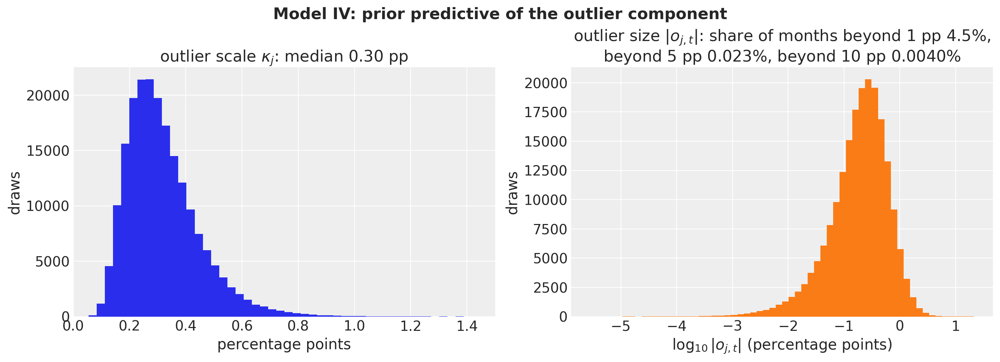

In [30]:
NUM_PRIOR_DRAWS = 200_000
rng_key, key_prior = random.split(rng_key)
key_m, key_v, key_z, key_eta = random.split(key_prior, 4)
log_omega2_mean = float(posterior_2["log_omega2"].mean())
prior_kappa_loc = (
    log_omega2_mean + jnp.log(0.01) + jnp.sqrt(0.5) * random.normal(key_m, (NUM_PRIOR_DRAWS,))
)
prior_kappa_sd = jnp.exp(0.5 * (jnp.log(0.09) + 0.5 * random.normal(key_v, (NUM_PRIOR_DRAWS,))))
prior_kappa = jnp.exp(
    0.5 * (prior_kappa_loc + prior_kappa_sd * random.normal(key_z, (NUM_PRIOR_DRAWS,)))
)
prior_outlier = prior_kappa * random.t(key_eta, 4.0, (NUM_PRIOR_DRAWS,))
exceed = {size: float((jnp.abs(prior_outlier) > size).mean()) for size in (1.0, 5.0, 10.0)}

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5), layout="constrained")
axes[0].hist(np.asarray(prior_kappa), bins=60, color="C0")
axes[0].set(
    title=rf"outlier scale $\kappa_j$: median {float(jnp.median(prior_kappa)):.2f} pp",
    xlabel="percentage points",
    ylabel="draws",
    xlim=(0, 1.5),
)
axes[1].hist(np.log10(np.abs(np.asarray(prior_outlier)) + 1e-6), bins=60, color="C1")
axes[1].set(
    title="outlier size $|o_{j,t}|$: share of months beyond 1 pp "
    + rf"${100 * exceed[1.0]:.1f}\%$,"
    + "\n"
    + rf"beyond 5 pp ${100 * exceed[5.0]:.3f}\%$, beyond 10 pp ${100 * exceed[10.0]:.4f}\%$",
    xlabel=r"$\log_{10} |o_{j,t}|$ (percentage points)",
    ylabel="draws",
)
fig.suptitle(
    "Model IV: prior predictive of the outlier component", fontsize=16, fontweight="bold"
);

At the common scale of Model II the prior median of $\kappa_j$ is $0.30$ percentage points, a tenth of the innovation scale. The right panel is what that implies for a month: an outlier beyond $1$ point in $4.5\%$ of the months, beyond $5$ points in $0.07\%$ and beyond $10$ points in $0.01\%$, about two months in the $17{,}697$ of the panel. The prior says that the outlier component is a small noise almost always and a large shock almost never; a $-82$ point outlier is an event the prior puts far out in its tail, and the posterior has to decide whether that or an innovation of $-82$ with its propagation is the cheaper explanation.

### Two explanations of a large shock, and where NUTS starts

A month like Louisiana in 2005m9 ($-81.8$ percentage points) has two explanations under Model IV: an innovation that propagates ($\varepsilon_{j,t}$ large, $o_{j,t} \approx 0$) or an additive outlier that does not ($o_{j,t} \approx -82$, $\varepsilon_{j,t}$ ordinary). The posterior has a mode for each, and between them lies a region where the shock is split in two expensive halves. NUTS does not cross that region: a chain stays in the mode it starts from. `init_to_median` starts every latent $\eta_{j,t}$ at zero, the median of its prior, which is the innovation mode for every shock in the sample.

`informed_start` builds the alternative start: for the months whose growth rate is more than $20$ points away from the state's median, the robust deviation divided by $0.3$ (the prior median of $\kappa_j$) is the starting value of $\eta_{j,t}$, and zero elsewhere; `start_outliers_at` turns it into an initialization strategy that uses the prior median for every other site. We run the fit from both starts and compare them on the **potential energy** of the draws, the negative log posterior density up to a constant: the mode with the lower potential energy holds more posterior mass, and the chains should agree within a start.

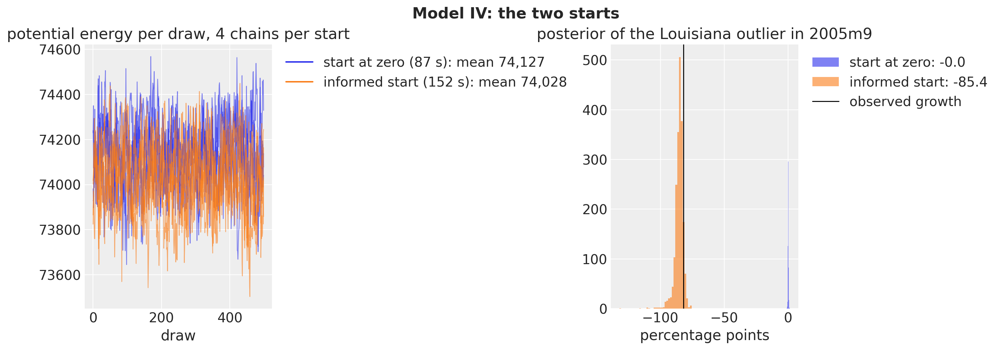

In [31]:
def informed_start(y: Array, threshold: float = 20.0, scale: float = 0.3) -> Array:
    """Build the start of ``outlier_eta``: the robust deviation over ``scale`` beyond ``threshold``."""
    deviation = y - jnp.median(y, axis=0)  # (months, states)
    return jnp.where(jnp.abs(deviation) > threshold, deviation / scale, 0.0)


def start_outliers_at(eta: Array) -> Callable[..., object]:
    """Build an init strategy: ``eta`` for the site ``outlier_eta``, the prior median elsewhere."""

    def strategy(site: dict | None = None, **kwargs: object) -> object:
        if site is None:
            return partial(strategy, **kwargs)
        if site["name"] == "outlier_eta":
            return eta
        return INIT_STRATEGY(site)

    return strategy


model_4 = make_rts_model(y_init, student_t=True, outliers=True)
eta_start = informed_start(growth)
rng_key, key_zero, key_fit, key_tree = random.split(rng_key, 4)
mcmc_4_zero, seconds_4_zero = fit_nuts(
    key_zero, model_4, growth, num_warmup=FULL_WARMUP, num_samples=FULL_SAMPLES
)
mcmc_4, seconds_4 = fit_nuts(
    key_fit,
    model_4,
    growth,
    num_warmup=FULL_WARMUP,
    num_samples=FULL_SAMPLES,
    init_strategy=start_outliers_at(eta_start),
)
tree_4 = export(key_tree, model_4, mcmc_4)

assert int((eta_start != 0.0).sum()) == 30

katrina = int(np.flatnonzero(dates == np.datetime64("2005-09-01"))[0])
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5), layout="constrained")

for mcmc, seconds, label, color in (
    (mcmc_4_zero, seconds_4_zero, "start at zero", "C0"),
    (mcmc_4, seconds_4, "informed start", "C1"),
):
    energy = np.asarray(
        mcmc.get_extra_fields(group_by_chain=True)["potential_energy"]
    )  # (chain, draw)
    axes[0].plot(energy.T, color=color, alpha=0.6, lw=0.8)
    axes[0].plot(
        [], [], color=color, label=f"{label} ({seconds:.0f} s): mean {energy.mean():,.0f}"
    )
    outlier_katrina = np.asarray(mcmc.get_samples()["outlier"])[:, katrina, louisiana]
    axes[1].hist(
        outlier_katrina,
        bins=40,
        color=color,
        alpha=0.6,
        label=f"{label}: {outlier_katrina.mean():.1f}",
    )

axes[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
axes[0].set(title="potential energy per draw, 4 chains per start", xlabel="draw")
axes[1].axvline(float(growth[katrina, louisiana]), color="black", lw=1, label="observed growth")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
axes[1].set(title="posterior of the Louisiana outlier in 2005m9", xlabel="percentage points")
fig.suptitle("Model IV: the two starts", fontsize=16, fontweight="bold");

The two starts land in two different places. From zero, the posterior of the Louisiana outlier in 2005m9 is $0.0 \pm 0.3$ points: the chains explain Katrina as an innovation and never leave. From the informed start it is $-85$ points with a $94\%$ interval of about $-91$ to $-80$, the observed $-81.8$ inside it: the chains explain Katrina as an additive outlier. The potential energy decides between them: the informed start averages $74{,}028$ against $74{,}127$ from zero, $99$ nats lower, with the four chains of each start agreeing among themselves. The posterior density is higher at the additive mode by a factor of $e^{99}$, and the zero start is a local mode that NUTS cannot leave in $1{,}500$ iterations. Every Model IV and Model V fit below, the backtest fits included, uses the informed start.

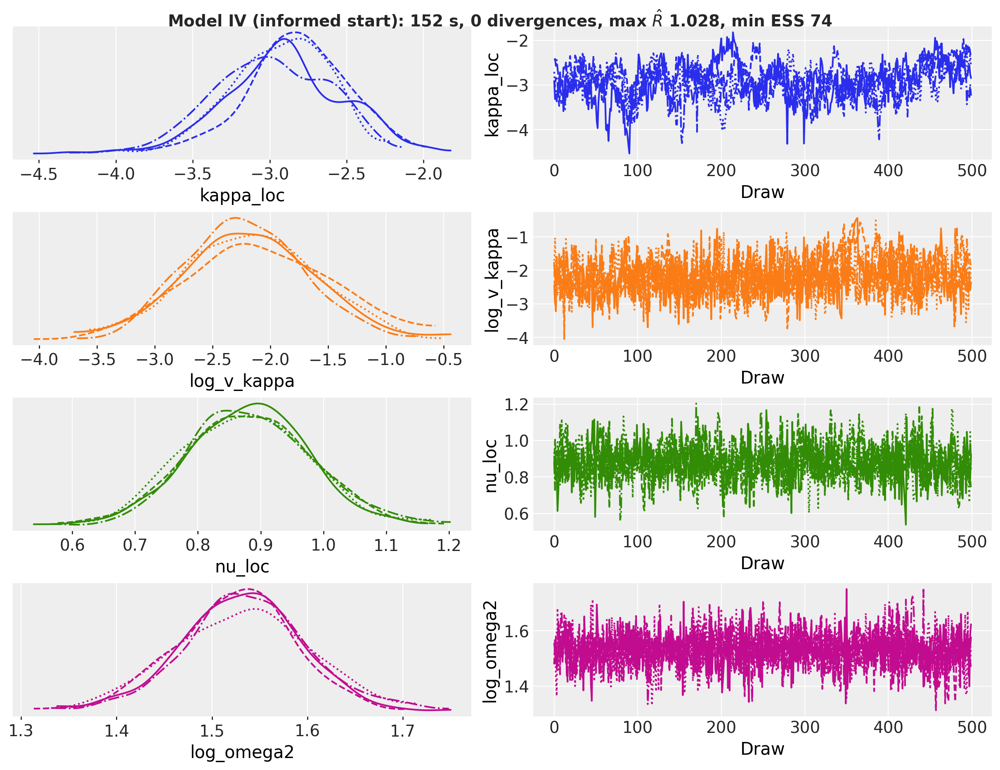

In [32]:
pc = az.plot_trace_dist(
    tree_4,
    var_names=["kappa_loc", "log_v_kappa", "nu_loc", "log_omega2"],
    compact=True,
    figure_kwargs={"figsize": (12, 9)},
)
pc.viz["figure"].item().suptitle(
    fit_title("Model IV (informed start)", mcmc_4, seconds_4),
    fontsize=14,
    fontweight="bold",
    y=1.02,
);

No divergent transition in $152$ seconds, but one hyperparameter mixes slowly: `kappa_loc`, the center of the outlier scale hierarchy, has an effective sample size of $74$ and the largest $\hat R$ of the fit, $1.028$; its trace wanders over $-4$ to $-2$ and the four densities differ in shape. Every other hyperparameter is as well mixed as in Model III. The reason is the one that fixed $\nu^o$: `kappa_loc` is tied to the $17{,}697$ outlier latents, and NUTS moves it one small step at a time. The next two tables say what that costs.

In [33]:
hyper_summary(tree_4)

,mean,sd,hdi94_lb,hdi94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
log_omega2,1.531,0.065,1.4,1.7,1425,1399,1.00,0.0017,0.0016
log_v_sigma,-1.657,0.197,-2,-1.3,1868,1414,1.00,0.0046,0.0042
nu_loc,0.88,0.099,0.7,1.1,994,1328,1.00,0.0032,0.002
log_v_nu,-1.43,0.32,-2,-0.81,1196,1411,1.00,0.0093,0.0059
kappa_loc,-2.92,0.37,-3.6,-2.2,72,110,1.03,0.043,0.019
log_v_kappa,-2.16,0.57,-3.2,-1.1,258,335,1.02,0.038,0.019


The rows shared with Model III move a little (`log_omega2` from $1.56$ to $1.53$, `log_v_nu` from $-1.27$ to $-1.43$; the $\nu$ center stays at $4.4$) and keep effective sample sizes near $1{,}000$ or above, so the outlier component changes little about the innovations. The two new rows are the slow ones: `kappa_loc` at $-2.92$ ($94\%$ HDI $-3.6$ to $-2.2$) with an effective sample size of $72$ and $\hat R$ $1.03$, and `log_v_kappa` at $-2.16$ with $258$ and $1.02$. A posterior mean of $-2.9$ for $\ln \kappa^2$ is a common outlier scale of $e^{-1.46} \approx 0.23$ points, below the prior median of $0.30$.

The quantities the outlier component is for are the state scales $\kappa_j$ and the outliers themselves; their mixing is the question, so the next table summarizes $\kappa_j$ for the six states and the Louisiana outlier in the two months of Katrina.

In [34]:
katrina_months = dates[katrina : katrina + 2]
pd.concat(
    [
        az.summary(
            tree_4,
            var_names=["kappa"],
            coords={"state": list(SELECTED)},
            ci_kind="hdi",
            ci_prob=0.94,
        ),
        az.summary(
            tree_4["posterior"].to_dataset()[["outlier"]].sel(state="LA", time=katrina_months),
            ci_kind="hdi",
            ci_prob=0.94,
        ),
    ]
).round(3)

,mean,sd,hdi94_lb,hdi94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
kappa[NJ],0.237,0.060,0.129,0.346,132.197,278.883,1.021,0.005,0.002
kappa[IL],0.238,0.060,0.134,0.357,150.447,374.841,1.015,0.005,0.002
kappa[CA],0.233,0.058,0.123,0.334,115.332,216.613,1.015,0.005,0.002
kappa[IA],0.241,0.062,0.137,0.363,161.181,332.448,1.016,0.005,0.003
kappa[WV],0.237,0.060,0.130,0.346,161.513,394.599,1.014,0.005,0.002
kappa[LA],0.326,0.110,0.160,0.533,48.560,92.755,1.062,0.016,0.011
outlier[2005-09-01T00:00:00],-85.384,3.450,-90.681,-79.555,1610.986,979.516,1.005,0.099,0.254
outlier[2005-10-01T00:00:00],-37.234,2.624,-41.832,-31.869,2122.470,1438.766,1.004,0.058,0.087


The quantities that matter mix: the six state scales $\kappa_j$ have effective sample sizes of $115$ to $161$ for the five states without an identified outlier and $48$ for Louisiana, with $\hat R$ at $1.01$ to $1.02$ ($1.06$ for Louisiana), and the Louisiana outliers of the two Katrina months, $-85.4 \pm 3.5$ and $-37.2 \pm 2.6$ points, have effective sample sizes above $1{,}600$ and $\hat R$ $1.00$. The slow `kappa_loc` moves the whole set of $\kappa_j$ up and down together within its $0.13$ to $0.36$ interval, and the outliers themselves do not depend on where it sits.

The posterior of the outlier component $o_{j,t}$ for Louisiana around Hurricane Katrina and for West Virginia over the last decade of the sample, with the observed growth on top.

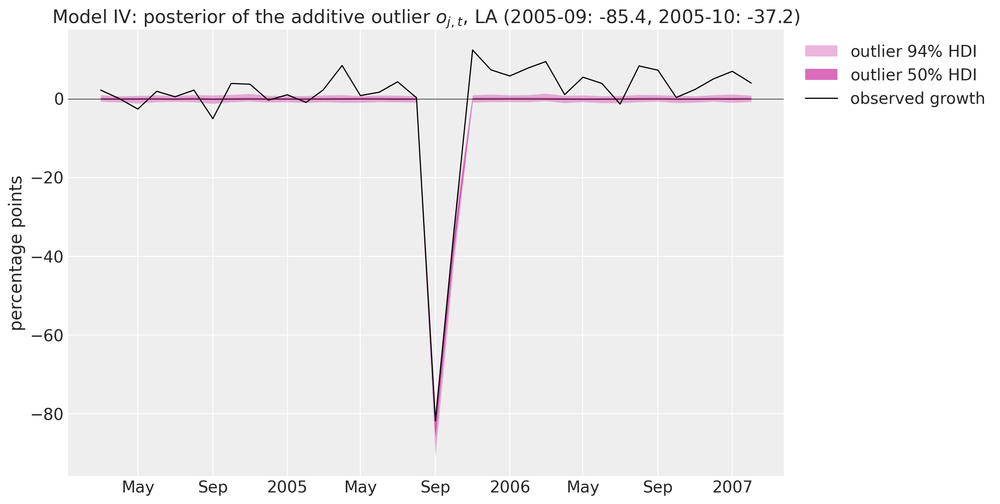

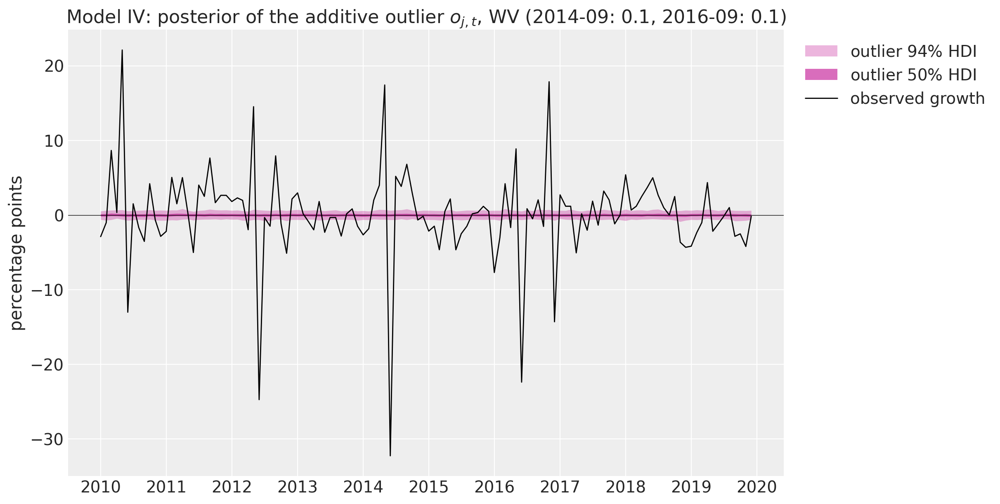

In [35]:
posterior_4 = tree_4["posterior"].dataset
windows = {"LA": slice(katrina - 18, katrina + 18), "WV": slice(num_months - 120, num_months)}

for state, window in windows.items():
    column = states.index(state)
    outlier_draws = stack_draws(posterior_4["outlier"].sel(state=state))[:, window, None]
    pc, band_handles = plot_bands(
        outlier_draws, date_num[window], [state], color="C3", label="outlier "
    )
    ax = pc.viz["figure"].item().axes[0]
    (observed_line,) = ax.plot(
        date_num[window], growth[window, column], color="black", lw=1, label="observed growth"
    )
    ax.axhline(0.0, color="black", lw=0.5)
    ax.legend(handles=[*band_handles, observed_line], loc="upper left", bbox_to_anchor=(1.01, 1.0))
    largest = np.argsort(np.abs(outlier_draws.mean(axis=0)[:, 0]))[-2:]
    months = ", ".join(
        f"{np.datetime_as_string(dates[window][i], unit='M')}: {outlier_draws.mean(axis=0)[i, 0]:.1f}"
        for i in sorted(largest)
    )
    ax.set(
        title=rf"Model IV: posterior of the additive outlier $o_{{j, t}}$, {state} ({months})",
        ylabel="percentage points",
    )

In Louisiana the outlier component takes the two Katrina months and nothing else: $-85$ points in 2005m9 and $-37$ in 2005m10 (posterior means, the observed rates $-81.8$ and $-34.4$), with $94\%$ intervals about ten points wide, and a band of $\pm 1$ point in every other month, where the component is the small noise its prior describes. The outlier exceeds the observed rate in 2005m9 because the AR recursion, run on the series without the outlier, expects a positive rate that month and the outlier has to cover the gap. In West Virginia over 2010 to 2019 the band stays within $\pm 1$ point at every one of the $\pm 20$ spikes: with $\kappa_{WV}$ at $0.24$ points and $\nu^o = 4$, a $25$ point outlier is $100$ scale units of the outlier distribution, and the Student-t innovations of the state, with $\nu_{WV} = 2.5$, explain a $25$ point month more cheaply. The additive outlier model finds the largest shocks of the sample and leaves the mining spikes to the innovations.

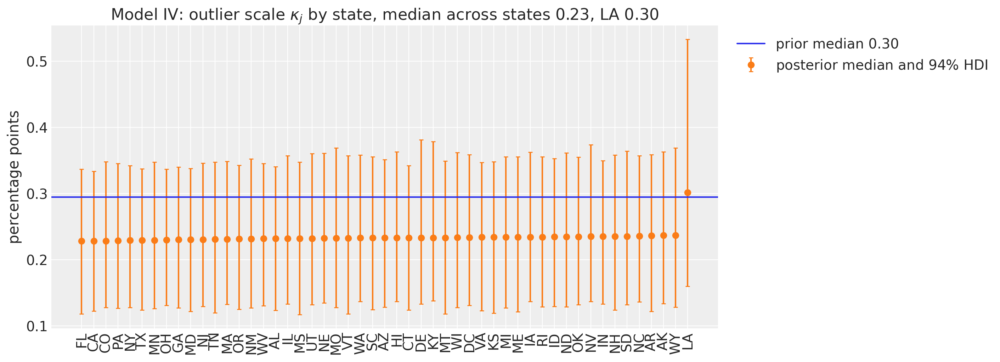

In [36]:
kappa_median = posterior_4["kappa"].median(("chain", "draw")).to_numpy()
order = np.argsort(kappa_median)
kappa_hdi = az.hdi(posterior_4["kappa"], prob=0.94).to_numpy()  # (states, 2): lower, upper

fig, ax = plt.subplots(figsize=(14, 5))
ax.errorbar(
    np.arange(num_states),
    kappa_median[order],
    yerr=np.abs(kappa_hdi[order].T - kappa_median[order]),
    fmt="o",
    color="C1",
    capsize=2,
    label=r"posterior median and $94\%$ HDI",
)
ax.axhline(
    float(jnp.median(prior_kappa)),
    color="C0",
    lw=1.5,
    label=f"prior median {float(jnp.median(prior_kappa)):.2f}",
)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(
    title=rf"Model IV: outlier scale $\kappa_j$ by state, median across states {np.median(kappa_median):.2f}, "
    + f"LA {kappa_median[louisiana]:.2f}",
    xticks=np.arange(num_states),
    xticklabels=[states[i] for i in order],
    ylabel="percentage points",
)
ax.tick_params(axis="x", rotation=90)

The outlier scales are pooled almost completely: $50$ of the $51$ states have a posterior median of $0.23$ to $0.24$ points with the same $94\%$ interval of about $0.12$ to $0.36$, below the prior median of $0.30$, because for a state without an identified outlier the component only adds noise and the likelihood shrinks it. Louisiana is the exception at $0.30$ with an interval up to $0.53$: its two identified outliers of $37$ and $85$ points are what the data say about $\kappa_{LA}$. The hierarchy does its job in both directions, a common value for the states with no information and room for the one state with some.

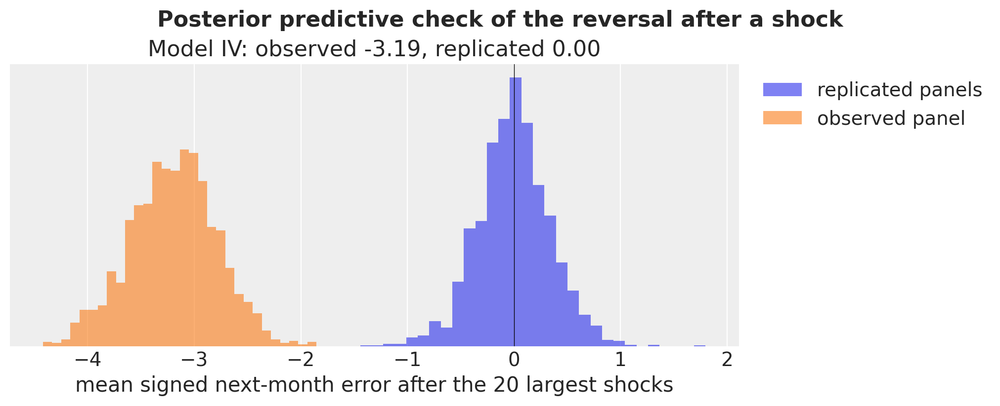

In [37]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_reversal(ax, tree_4, "Model IV")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.suptitle(
    "Posterior predictive check of the reversal after a shock", fontsize=16, fontweight="bold"
);

The reversal check still fails, and the observed statistic is now $-3.2$ against $-1.75$ under Model III. With Katrina moved into the outlier component, the twenty largest standardized errors are the mining spikes of West Virginia and the similar pairs in other states, and after each of those the next month reverses by three standard units. Model IV captures the shocks that are too large for the Student-t innovations, and not the $\pm 25$ point spikes that a Student-t with $\nu \approx 2.5$ absorbs at the cost of its tails. The paper reports the same from the other side: Models III and IV score the same in its Tables 2 and 3.

### The check that motivates Model V: coverage over time

Models I to IV have one innovation scale per state for the whole sample, and the rolling residual standard deviations of the data section moved by a factor of two or more. The check is the **coverage of the one-step 90-10 interval over time**: for every month, the share of the 51 states whose observed growth falls inside the $0.10$ to $0.90$ quantiles of the one-step predictive, smoothed over 24 months. A model with the right scale at every date covers $80\%$ everywhere; a model with a single scale covers too much in the calm years and too little in the turbulent ones. The replicated band comes from replicated panels scored against the same quantiles.

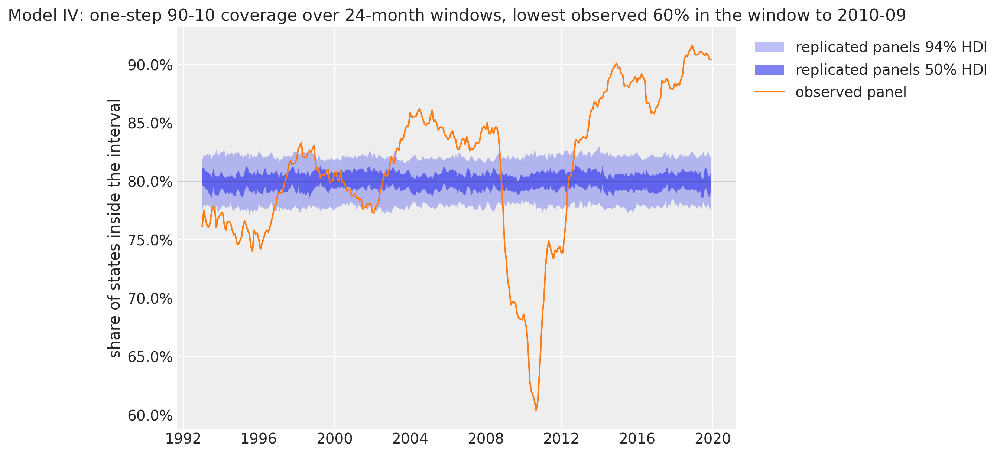

In [38]:
def rolling_coverage(
    tree: xr.DataTree, y: np.ndarray, window: int = ROLLING, level: float = INTERVAL_LEVEL
) -> np.ndarray:
    """Compute the rolling share of ``y`` ``(..., time, state)`` inside the one-step interval of ``tree``."""
    draws = stack_draws(tree["posterior_predictive"]["obs"])  # (sample, time, state)
    tail = (1.0 - level) / 2.0
    lower, upper = np.quantile(draws, (tail, 1.0 - tail), axis=0)  # (time, state) each
    inside = ((y >= lower) & (y <= upper)).mean(axis=-1)  # (..., time)
    kernel = np.ones(window) / window
    return np.apply_along_axis(lambda row: np.convolve(row, kernel, mode="valid"), -1, inside)


def plot_coverage(tree: xr.DataTree, label: str, num_replicates: int = 200) -> None:
    """Observed rolling coverage against the HDI bands of the replicated panels."""
    observed = rolling_coverage(tree, np.asarray(growth))  # (time - 23,)
    replicated = rolling_coverage(
        tree,
        stack_draws(tree["posterior_predictive"]["obs"])[
            :: max(1, NUM_CHAINS * FULL_SAMPLES // num_replicates)
        ],
    )  # (replicates, time - 23)
    pc, band_handles = plot_bands(
        replicated[:, :, None], date_num[ROLLING - 1 :], ["coverage"], label="replicated panels "
    )
    ax = pc.viz["figure"].item().axes[0]
    (observed_line,) = ax.plot(
        date_num[ROLLING - 1 :], observed, color="C1", lw=1.5, label="observed panel"
    )
    ax.axhline(INTERVAL_LEVEL, color="black", lw=0.5)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0))
    ax.legend(handles=[*band_handles, observed_line], loc="upper left", bbox_to_anchor=(1.01, 1.0))
    lowest = np.datetime_as_string(dates[ROLLING - 1 + observed.argmin()], unit="M")
    ax.set(
        title=f"{label}: one-step 90-10 coverage over 24-month windows, "
        + rf"lowest observed ${observed.min():.0%}$ in the window to {lowest}".replace("%", r"\%"),
        ylabel="share of states inside the interval",
    )


plot_coverage(tree_4, "Model IV")

The one-step 90-10 interval of Model IV has the right width on average and the wrong width at every date. The observed coverage runs at $74\%$ to $77\%$ in the mid 1990s, at $80\%$ to $86\%$ in the 2000s, falls to $60\%$ in the 24 months to 2010m9 (the windows that contain 2009), and climbs to $85\%$ to $91\%$ from 2013 on, while the replicated band stays within $77\%$ to $83\%$. A single scale per state is too small for 2009 and too large for the 2010s, which is the volatility clustering of the rolling standard deviations of the data section. The next rung lets the scale move.

## Model V: stochastic volatility

Model V lets the innovation scale of every state move over time, $\varepsilon_{j,t}$ scaled by $\sigma_{j,t}$ instead of $\sigma_j$, with a log variance that follows a random walk. The paper does not sample the random walk month by month. It uses a **low-frequency representation**: the covariance matrix $\bar\Sigma_{RW}$ of a demeaned random walk of $T$ steps with unit innovation variance has eigenvectors $\psi_l$ close to cosines of $l$ half-periods over the sample and eigenvalues $\lambda_l$ that fall like $1/l^2$, so a random walk is well approximated by its first few eigen-components, $\sum_{l \le q} \varphi_l \xi_l$ with $\varphi_l = \lambda_l^{1/2} \psi_l$ and $\xi_l$ independent with the variance of the innovations. The model is

$$
\ln \sigma^2_{j,t} = \ln \sigma_j^2 + \sum_{l=1}^{q} \varphi_{l,t} \, \xi_{j,l}, \qquad q = \lfloor T / 36 \rfloor,
$$

with priors

$$
\xi_{j,l} \mid m_{\xi_l}, v_\xi \sim \text{Normal}(m_{\xi_l}, v_\xi), \qquad m_{\xi_l} \sim \text{Normal}(0, 0.01^2), \qquad \ln v_\xi \sim \text{Normal}(\ln 0.01^2, 0.5^2).
$$

Three things to read in this specification:

- $q = \lfloor T/36 \rfloor$ keeps the components with periods longer than $72$ months, six years: the volatility moves at the frequency of business cycles, not month to month. The paper counts $T$ from 1990m2, the seed rows included, so $q = \lfloor 359/36 \rfloor = 9$ on the full sample and $3$ at the first forecast origin.
- $m_{\xi_l}$ is the **common volatility path**, shared by all states, and $v_\xi$ the variance of the state-specific departures from it. The common path is the comovement in volatility of the paper's Figure 5.
- $\sqrt{v_\xi}$ has a prior median of $0.01$: the standard deviation of a one-month step of the underlying random walk in the log variance. Over the sample the components accumulate, and the next figure shows what the prior allows for $\sigma_{j,t} / \sigma_j$ at every date.

Over the forecast horizon the paper continues the log volatility as a random walk with step variance $v_\xi$ from its last in-sample value; the model function does the same for $\ln \sigma^2_{j,t}$ (the paper's sentence names $\ln \sigma_{j,t}$, we read it as the quantity of its equation (21)). The figure shows the nine basis columns of the full sample and the prior $94\%$ band of the volatility ratio.

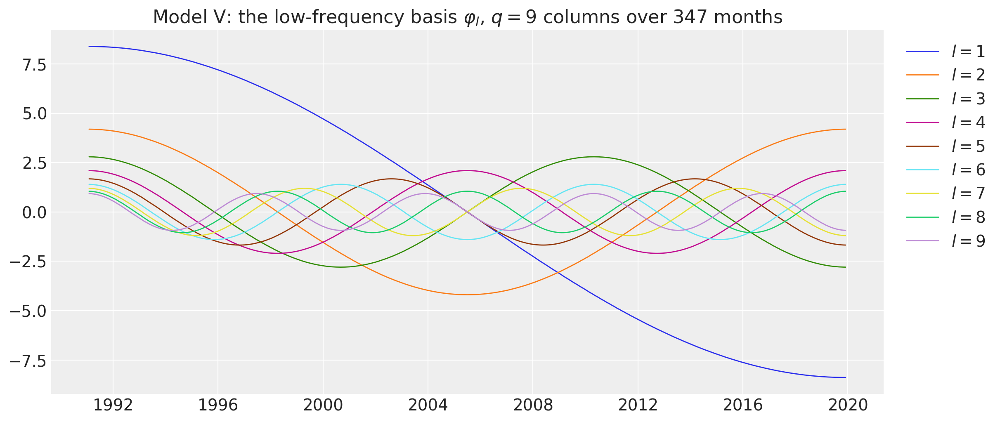

In [39]:
num_terms_full = (num_months + LAGS) // 36
basis_full = np.asarray(low_frequency_basis(num_months, num_terms_full))  # (months, 9)

fig, ax = plt.subplots(figsize=(12, 5))

for column in range(num_terms_full):
    ax.plot(dates, basis_full[:, column], lw=1, label=rf"$l = {column + 1}$")

ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.set(
    title=rf"Model V: the low-frequency basis $\varphi_l$, $q = {num_terms_full}$ columns over {num_months} months"
);

The nine columns are cosines with $1$ to $9$ half periods over the $347$ months, and their amplitudes fall with the frequency: the first column swings between about $\pm 8$ and the ninth between $\pm 1$, in the ratio $1/l$ of the square-root eigenvalues. The first column is a slow drift from one end of the sample to the other, the second a single hump, and so on up to the ninth with a period of $77$ months. Anything faster than that is not in the volatility path of Model V. The next figure draws the prior on the volatility ratio of one state: $m_{\xi_l}$ and $v_\xi$ from their priors, $\xi_{j,l}$ from its conditional, and the ratio $\exp(\tfrac{1}{2} \sum_l \varphi_{l,t} \xi_{j,l})$ at every date.

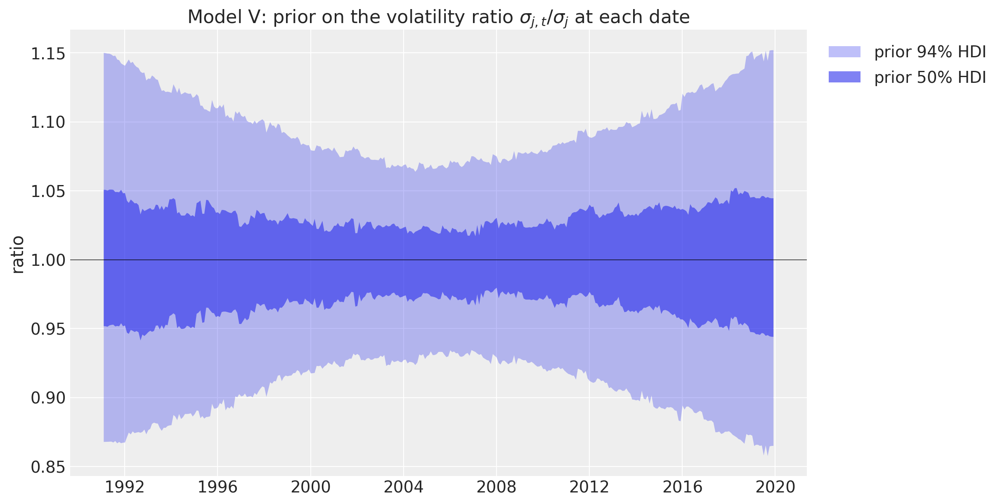

In [40]:
rng_key, key_prior = random.split(rng_key)
key_m, key_v, key_z = random.split(key_prior, 3)
prior_m_xi = 0.01 * random.normal(key_m, (5_000, num_terms_full))  # (draws, 9): the common part
prior_v_xi = jnp.exp(jnp.log(1e-4) + 0.5 * random.normal(key_v, (5_000, 1)))  # (draws, 1)
prior_xi = prior_m_xi + jnp.sqrt(prior_v_xi) * random.normal(
    key_z, (5_000, num_terms_full)
)  # (draws, 9): xi_{j, l} for one state
prior_ratio = np.exp(0.5 * np.asarray(prior_xi @ basis_full.T))  # (draws, months)

pc, band_handles = plot_bands(prior_ratio[:, :, None], date_num, ["ratio"], label="prior ")
ax = pc.viz["figure"].item().axes[0]
ax.axhline(1.0, color="black", lw=0.5)
ax.legend(handles=band_handles, loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(
    title=r"Model V: prior on the volatility ratio $\sigma_{j,t} / \sigma_j$ at each date",
    ylabel="ratio",
);

The components accumulate to a $94\%$ band of about $0.87$ to $1.15$ for the volatility ratio at the ends of the sample and $0.93$ to $1.07$ in the middle, where the demeaned basis functions are small: the prior lets the scale of a state drift by $7\%$ to $15\%$ over the sample and says nothing about when. Half of that variance is the common part $m_{\xi_l}$, which the $51$ states estimate together, and half the state's own departure. The data section measured swings by a factor of two in the rolling standard deviations, so this prior is tight relative to the data; $\ln v_\xi$ has a prior standard deviation of $0.5$, which scales the state's departure by a factor of $e^{0.25} \approx 1.28$ per standard deviation.

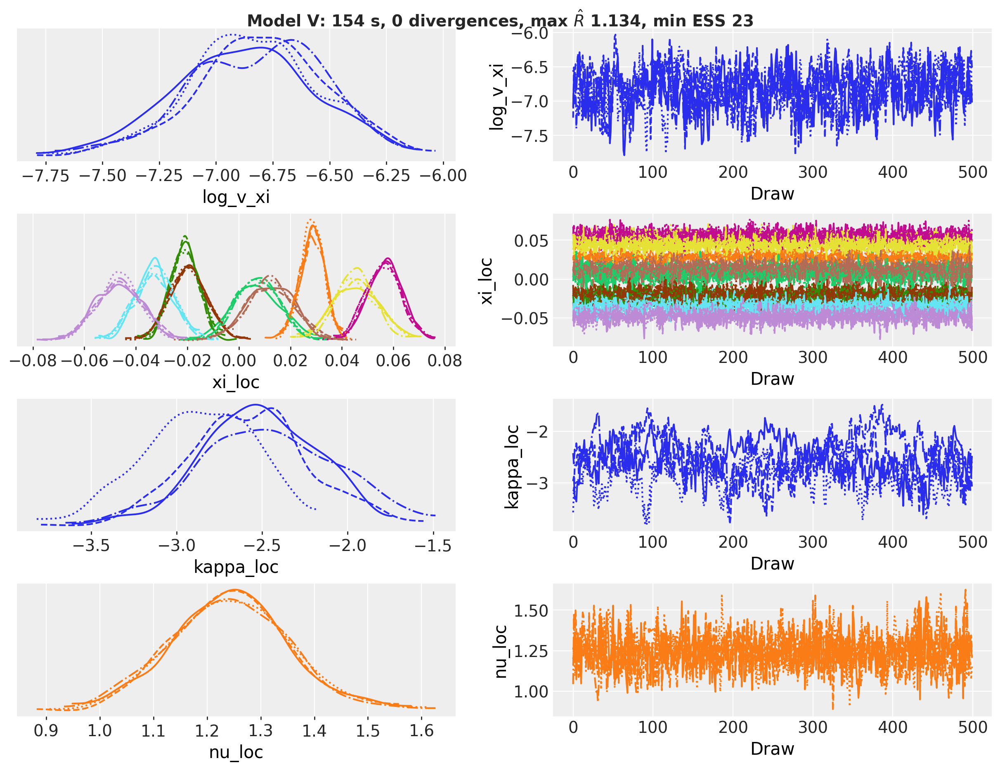

In [41]:
model_5 = make_rts_model(y_init, student_t=True, outliers=True, stochastic_volatility=True)
rng_key, key_fit, key_tree = random.split(rng_key, 3)
mcmc_5, seconds_5 = fit_nuts(
    key_fit,
    model_5,
    growth,
    num_warmup=FULL_WARMUP,
    num_samples=FULL_SAMPLES,
    init_strategy=start_outliers_at(eta_start),
)
tree_5 = export(key_tree, model_5, mcmc_5)

pc = az.plot_trace_dist(
    tree_5,
    var_names=["log_v_xi", "xi_loc", "kappa_loc", "nu_loc"],
    compact=True,
    figure_kwargs={"figsize": (12, 9)},
)
pc.viz["figure"].item().suptitle(
    fit_title("Model V", mcmc_5, seconds_5), fontsize=14, fontweight="bold", y=1.02
);

No divergent transition in $154$ seconds. The nine `xi_loc` densities, the common volatility components, are well separated and the chains agree on each; `log_v_xi` sits at $-6.8$, which is $\ln v_\xi = \ln 0.01^2 - 2.4 = -9.2$ in the prior against $-6.8$ here: the data want state-specific departures from the common path with a step standard deviation of $e^{-3.4} \approx 0.033$, three times the prior median. `kappa_loc` is again the slow site (effective sample size $23$, $\hat R$ $1.13$, the four densities with different shapes), for the reason given in the Model IV section, and the degrees of freedom center moves up to $1.24$, a common $\nu$ of $5.5$: once the volatility path explains the 2009 months, the innovations need lighter tails.

In [42]:
hyper_summary(tree_5)

,mean,sd,hdi94_lb,hdi94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
log_omega2,1.565,0.066,1.4,1.7,977,715,1.01,0.0021,0.0021
log_v_sigma,-1.636,0.186,-2,-1.3,1968,1401,1.00,0.0042,0.0048
nu_loc,1.244,0.109,1,1.4,901,1200,1.00,0.0036,0.0024
log_v_nu,-1.35,0.31,-1.9,-0.77,1088,1605,1.00,0.0093,0.0057
kappa_loc,-2.6,0.39,-3.3,-1.8,26,78,1.13,0.077,0.021
log_v_kappa,-2,0.62,-3.2,-0.81,160,113,1.02,0.052,0.034
log_v_xi,-6.84,0.3,-7.4,-6.3,385,629,1.01,0.015,0.0064


Compared with Model IV, `nu_loc` rises from $0.88$ to $1.24$ (a common $\nu$ from $4.4$ to $5.5$) and `log_v_xi` enters at $-6.84$ ($94\%$ HDI $-7.4$ to $-6.3$), $2.4$ above its prior center with the prior's $94\%$ range ending at $-8.2$: the posterior of the volatility step variance sits outside the prior's central range, which says the paper's prior on $v_\xi$ is tight for these data. `kappa_loc` keeps its slow mixing ($26$ effective draws, $\hat R$ $1.13$); `log_v_kappa` has $160$ and the other rows are above $380$.

The common volatility path is $\sum_l \varphi_{l,t} \, m_{\xi_l}$, the part of the log variance that every state shares; the paper's Figure 5 plots it at the posterior mean of $m_{\xi_l}$. We plot it as the volatility ratio $\exp(\tfrac{1}{2} \sum_l \varphi_{l,t} m_{\xi_l})$ with its posterior bands, and the state-specific ratios $\sigma_{j,t} / \sigma_j$ for the six states.

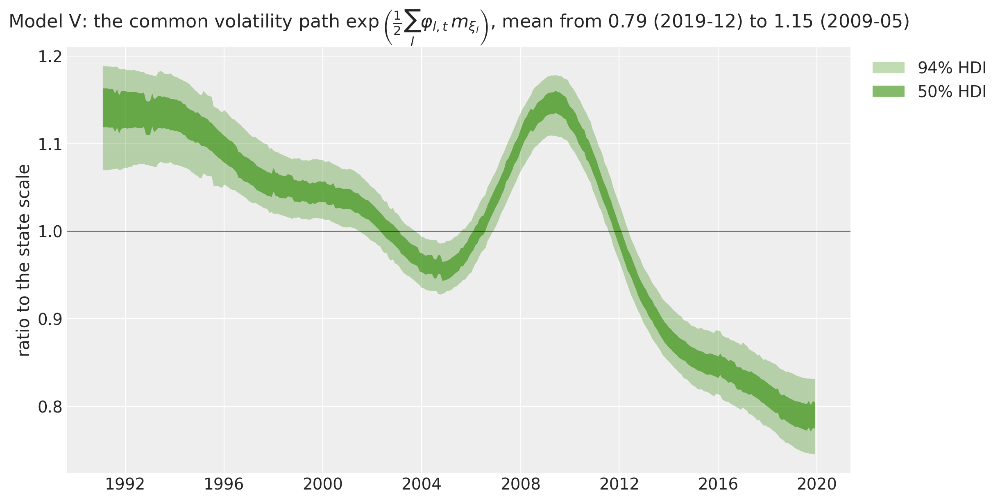

In [43]:
posterior_5 = tree_5["posterior"].dataset
xi_loc_draws = (
    posterior_5["xi_loc"].stack(sample=("chain", "draw")).transpose("sample", ...).to_numpy()
)  # (sample, 9)
common_ratio = np.exp(0.5 * xi_loc_draws @ basis_full.T)  # (sample, months)
common_mean = common_ratio.mean(axis=0)  # (months,)

pc, band_handles = plot_bands(common_ratio[:, :, None], date_num, ["common"], color="C2")
ax = pc.viz["figure"].item().axes[0]
ax.axhline(1.0, color="black", lw=0.5)
ax.legend(handles=band_handles, loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(
    title=r"Model V: the common volatility path $\exp\left(\frac{1}{2} \sum_l \varphi_{l,t} \, m_{\xi_l}\right)$, "
    + f"mean from {common_mean.min():.2f} ({np.datetime_as_string(dates[common_mean.argmin()], unit='M')}) "
    + f"to {common_mean.max():.2f} ({np.datetime_as_string(dates[common_mean.argmax()], unit='M')})",
    ylabel="ratio to the state scale",
);

The posterior mean of the common volatility ratio starts at $1.15$ in 1991, falls through the 1990s to a trough of $0.96$ around 2004, rises to a peak of $1.15$ in 2009m5, and falls to $0.79$ in 2019m12, the lowest point of the sample; the $94\%$ band is about $\pm 0.03$ wide around the mean. The peak sits where the recession is and the trough in the calm years before it; the decline after 2012 is the long expansion. The paper's Figure 5 shares the 2009 peak and little else: its path has its trough in the late 1990s and rises again after 2015, where this one falls to its minimum. The rolling residual standard deviations of the data section fall through the 2010s in every smooth state, so the path here follows the data as revised; what drives the paper's rise we cannot say. The common path moves the innovation scale of every state by about $\pm 15\%$ around its own level.

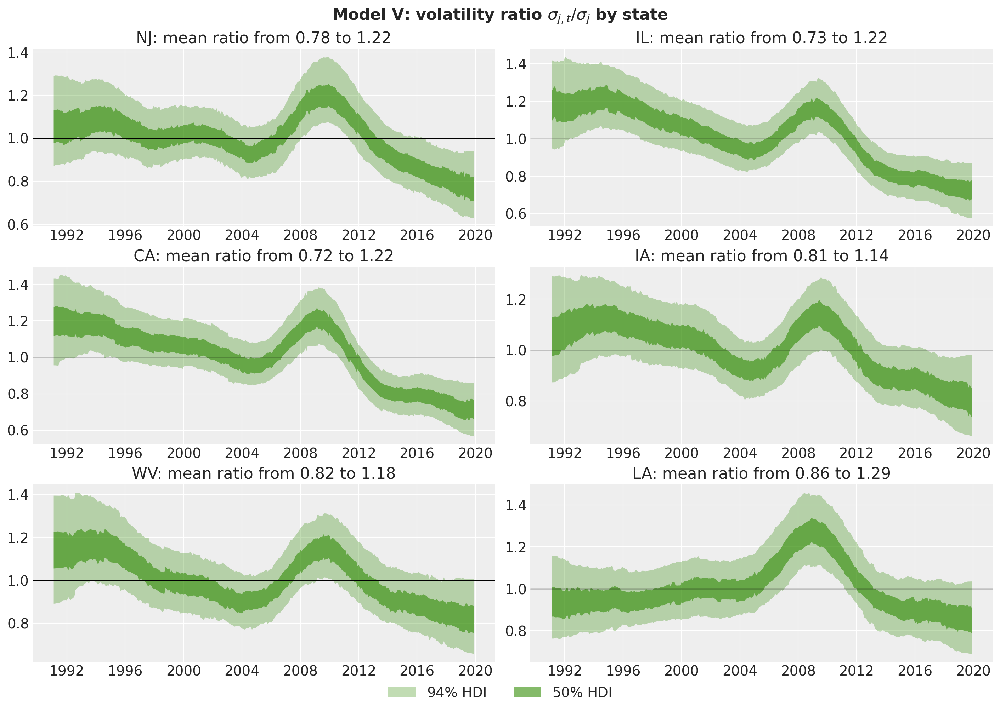

In [44]:
log_var_draws = stack_draws(
    posterior_5["log_var"].sel(state=list(SELECTED))
)  # (sample, months, 6)
log_sigma2_draws = (
    posterior_5["log_sigma2"]
    .sel(state=list(SELECTED))
    .stack(sample=("chain", "draw"))
    .transpose("sample", "state")
    .to_numpy()
)
state_ratio = np.exp(0.5 * (log_var_draws - log_sigma2_draws[:, None, :]))

pc, band_handles = plot_bands(
    state_ratio, date_num, list(SELECTED), color="C2", col_wrap=2, figsize=(14, 10)
)
fig = pc.viz["figure"].item()

for ax, state in zip(fig.axes, SELECTED, strict=True):
    ax.axhline(1.0, color="black", lw=0.5)
    mean_ratio = state_ratio[:, :, SELECTED.index(state)].mean(axis=0)
    ax.set(title=f"{state}: mean ratio from {mean_ratio.min():.2f} to {mean_ratio.max():.2f}")

fig.legend(handles=band_handles, loc="outside lower center", ncols=2)
fig.suptitle(
    r"Model V: volatility ratio $\sigma_{j,t} / \sigma_j$ by state", fontsize=16, fontweight="bold"
);

The six state paths share the common shape and differ in amplitude: the posterior mean ratio runs from $0.78$ to $1.22$ in New Jersey, $0.73$ to $1.22$ in Illinois, $0.72$ to $1.22$ in California, $0.81$ to $1.14$ in Iowa, $0.82$ to $1.18$ in West Virginia and $0.86$ to $1.29$ in Louisiana, with the 2009 peak in every one of them and the lowest values at the end of the sample. The $94\%$ bands are about $\pm 0.1$ wide, wider than the common path's, because a state's path adds its own nine components to the common ones. Louisiana's peak is the highest of the six, and Katrina leaves no mark on its path: the outlier component took that month, so the volatility does not have to.

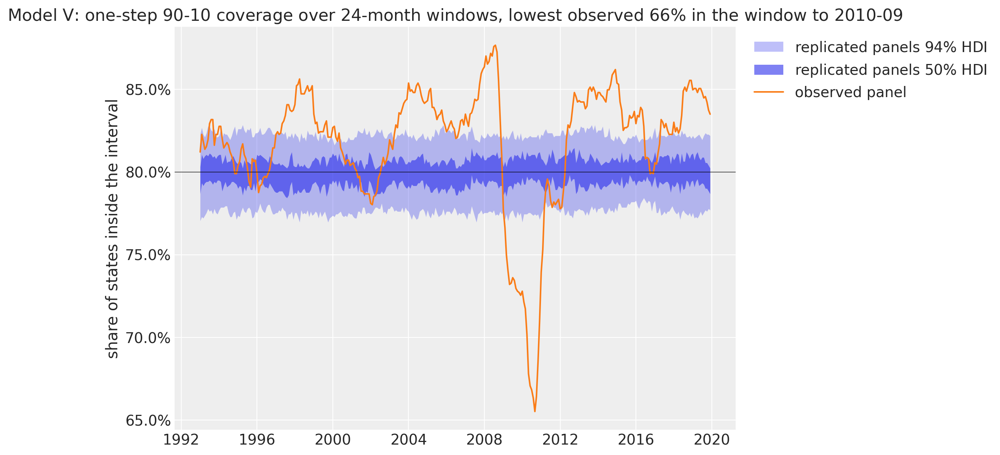

In [45]:
plot_coverage(tree_5, "Model V")

The dip is smaller and the rest of the sample moves the other way. In the 24 months to 2010m9 the observed coverage is $66\%$ instead of the $60\%$ of Model IV, closer to the replicated band and still below it, because the fastest component of the path has a period of $77$ months and the first months of 2009 are too fast for it. In the calm years the path lowers the scale, and the observed coverage, which was $85\%$ to $91\%$ under Model IV from 2013 on, is now $80\%$ to $87\%$; between 1996 and 2008 it runs at $80\%$ to $86\%$, above the band in 1998, 2004 and 2007. The 90-10 interval of Model V is a little wide in the calm years and too narrow in 2009; the Student-t tails take what the path leaves.

### The checks across the ladder

The three statistics of the workflow on every rung, observed against replicated: the share of standardized errors beyond four (the tails), the signed next-month error after the twenty largest shocks (the reversal), and the lowest 24-month coverage of the one-step 90-10 interval (the volatility). A rung passes a check when the observed statistic sits inside the replicated interval.

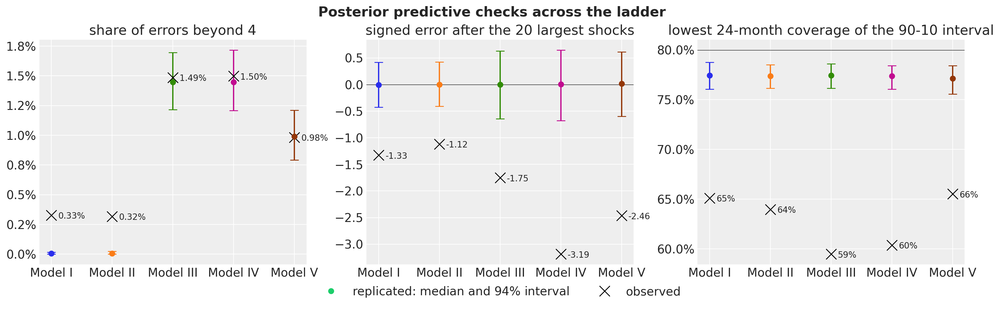

In [46]:
TREES = {"I": tree_1, "II": tree_2, "III": tree_3, "IV": tree_4, "V": tree_5}
FITS = {
    "I": (mcmc_1, seconds_1),
    "II": (mcmc_2, seconds_2),
    "III": (mcmc_3, seconds_3),
    "IV": (mcmc_4, seconds_4),
    "V": (mcmc_5, seconds_5),
}
RUNG_COLORS = {"0": "C5", "I": "C0", "II": "C1", "III": "C2", "IV": "C3", "V": "C4"}


def lowest_coverage(tree: xr.DataTree, num_replicates: int = 200) -> tuple[np.ndarray, np.ndarray]:
    """Lowest rolling coverage of the observed panel and of replicated panels."""
    observed = rolling_coverage(tree, np.asarray(growth)).min()
    replicated = rolling_coverage(
        tree,
        stack_draws(tree["posterior_predictive"]["obs"])[
            :: max(1, NUM_CHAINS * FULL_SAMPLES // num_replicates)
        ],
    ).min(axis=-1)
    return np.asarray([observed]), replicated


CHECKS = {
    "share of errors beyond 4": lambda tree: check_statistic(tree, tail_share),
    "signed error after the 20 largest shocks": lambda tree: check_statistic(tree, reversal),
    "lowest 24-month coverage of the 90-10 interval": lowest_coverage,
}
CHECK_FORMATS = {
    "share of errors beyond 4": lambda value: f"{value:.2%}",
    "signed error after the 20 largest shocks": lambda value: f"{value:.2f}",
    "lowest 24-month coverage of the 90-10 interval": lambda value: f"{value:.0%}",
}
check_values = {
    name: {rung: check(tree) for rung, tree in TREES.items()} for name, check in CHECKS.items()
}

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 5), layout="constrained")

for ax, (name, values) in zip(axes, check_values.items(), strict=True):
    for position, (rung, (observed, replicated)) in enumerate(values.items()):
        low, high = np.quantile(replicated, (0.03, 0.97))
        ax.errorbar(
            position,
            np.median(replicated),
            yerr=[[np.median(replicated) - low], [high - np.median(replicated)]],
            fmt="o",
            color=RUNG_COLORS[rung],
            capsize=5,
        )
        ax.plot(
            position,
            np.median(observed),
            marker="x",
            markersize=12,
            color="black",
            linestyle="none",
        )
        ax.annotate(
            CHECK_FORMATS[name](float(np.median(observed))),
            (position, float(np.median(observed))),
            xytext=(8, -4),
            textcoords="offset points",
        )

    ax.plot(
        [],
        [],
        marker="o",
        color="C7",
        linestyle="none",
        label=r"replicated: median and $94\%$ interval",
    )
    ax.plot([], [], marker="x", markersize=12, color="black", linestyle="none", label="observed")
    ax.set(title=name, xticks=range(len(TREES)), xticklabels=[f"Model {rung}" for rung in TREES])

axes[0].yaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=1))
axes[2].yaxis.set_major_formatter(PercentFormatter(xmax=1.0))
axes[1].axhline(0.0, color="black", lw=0.5)
axes[2].axhline(INTERVAL_LEVEL, color="black", lw=0.5)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=2)
fig.suptitle("Posterior predictive checks across the ladder", fontsize=16, fontweight="bold");

The figure is the workflow in one view, with the rungs on the horizontal axis and the three checks as panels:

- Tails. Models I and II fail (observed $0.33\%$ and $0.32\%$ against $0.01\%$ replicated); Models III, IV and V pass, with the observed share inside the replicated interval at every one of the three rungs.
- Reversal. Every rung fails: the observed statistic is $-1.3$ (I), $-1.1$ (II), $-1.8$ (III), $-3.2$ (IV) and $-2.5$ (V) against replicated intervals of about $\pm 0.5$ around zero. The additive outlier component captures the largest shocks, not the spike-and-reversal pairs of the mining states, and no rung of this notebook models those.
- Volatility. The lowest 24-month coverage of the one-step 90-10 interval is $59\%$ to $66\%$ observed against $77\%$ replicated at every rung, and Models I ($65\%$) and V ($66\%$) are the closest; the stochastic volatility narrows the gap and does not close it, because the 2009 drop is faster than its fastest component.

Two of the three checks move in the direction the ladder intends, and the one that does not points at a feature none of the rungs has. The reversal values show that Model IV moves the observed statistic away from zero rather than toward it, because moving Katrina out of the innovations leaves the mining spikes as the largest standardized errors.

## Pseudo-out-of-sample forecasts

The five Bayesian rungs now run the paper's experiment at 10 origins, 1999m12 and every twenty-fourth month after it to 2017m12. `make_forecast_fn` builds the `forecast_fn` of [`backtest`](../../reference/evaluate.backtest.html) for one rung: it fits the rung with four NUTS chains of $500$ warmup iterations and $250$ draws on the training window (the informed start recomputed on that window for the rungs with outliers), records the divergences and the largest $\hat R$ over the hyperparameters of the fit, draws the six-month forecast with `Predictive` and keeps, for the leave-future-out score of a later section, the location and scale of the one-step predictive of every draw. The forecast draws are the `forecast` site that [`forecast`](../../reference/predictive.forecast.html) reads; the extra sites are the reason for the direct `Predictive` call.

In [47]:
BACKTEST_WARMUP = 500
BACKTEST_SAMPLES = 1_000
LADDER_STRIDE = 24
backtest_fits: list[
    tuple[str, np.datetime64, int, float, float]
] = []  # rung, origin, divergences, R-hat, seconds
one_step: dict[tuple[str, np.datetime64], tuple[np.ndarray, np.ndarray, np.ndarray | None]] = {}


def make_forecast_fn(label: str, *, informed: bool) -> ForecastFn:
    """Build the ``forecast_fn`` of one rung: a NUTS fit on the window, then the forecast draws."""

    def forecast_fn(
        rng_key: Array,
        model: ForecastModel,
        train_data: Array,
        train_covariates: Array,
        full_covariates: Array,
        num_samples: int,
        *,
        batch_size: int | None = None,
    ) -> Array:
        key_fit, key_forecast = random.split(rng_key)
        init_strategy = (
            start_outliers_at(informed_start(train_data)) if informed else INIT_STRATEGY
        )
        mcmc, seconds = fit_nuts(
            key_fit,
            model,
            train_data,
            num_warmup=BACKTEST_WARMUP,
            num_samples=num_samples // NUM_CHAINS,
            init_strategy=init_strategy,
        )
        origin = dates[train_data.shape[0] - 1]
        backtest_fits.append((label, origin, num_divergences(mcmc), diagnostics(mcmc)[0], seconds))
        posterior = mcmc.get_samples()
        draws = Predictive(
            model,
            posterior,
            return_sites=["forecast", "forecast_loc", "forecast_scale"],
            parallel=True,
        )(key_forecast, full_covariates, train_data)
        nu = np.asarray(posterior["nu"]) if "nu" in posterior else None
        one_step[label, origin] = (
            np.asarray(draws["forecast_loc"][:, 0]),
            np.asarray(draws["forecast_scale"][:, 0]),
            nu,
        )
        return draws["forecast"]

    return forecast_fn


LADDER: dict[str, tuple[ModelFactory, bool]] = {
    "I": (partial(make_rts_model, y_init, hierarchical=False), False),
    "II": (partial(make_rts_model, y_init), False),
    "III": (partial(make_rts_model, y_init, student_t=True), False),
    "IV": (partial(make_rts_model, y_init, student_t=True, outliers=True), True),
    "V": (
        partial(make_rts_model, y_init, student_t=True, outliers=True, stochastic_volatility=True),
        True,
    ),
}
backtest_results: dict[str, list[BacktestResult]] = {
    "0": [result for result in ols_results if (result.t1 - FIRST_ORIGIN) % LADDER_STRIDE == 0]
}

for label, (model_fn, informed) in LADDER.items():
    rng_key, key_backtest = random.split(rng_key)
    backtest_results[label] = run_backtest(
        key_backtest,
        model_fn,
        make_forecast_fn(label, informed=informed),
        stride=LADDER_STRIDE,
        num_samples=BACKTEST_SAMPLES,
    )

origins = np.array([dates[result.t1 - 1] for result in backtest_results["0"]])

assert len(origins) == 10
assert all(
    [result.t1 for result in results] == [result.t1 for result in backtest_results["0"]]
    for results in backtest_results.values()
)

The first result is the paper's Tables 2 and 3: every loss at every horizon, pooled over the 10 origins and the 51 states, relative to Model 0 at the same origins. A relative loss is a ratio of two averages over the same origins, and the origins carry very different amounts of error (the 2007m12 origin, whose horizon runs into the recession, dominates the squared errors), so each ratio gets a **block bootstrap** band: resample the 10 origins with replacement, recompute the two pooled losses on the resample, take the ratio, and repeat $1{,}000$ times. `origin_losses` scores each origin on its own (the squared error is kept as a mean squared error, so that the bootstrap averages it before the square root), and `relative_losses` does the resampling. The paper's values are hollow markers.

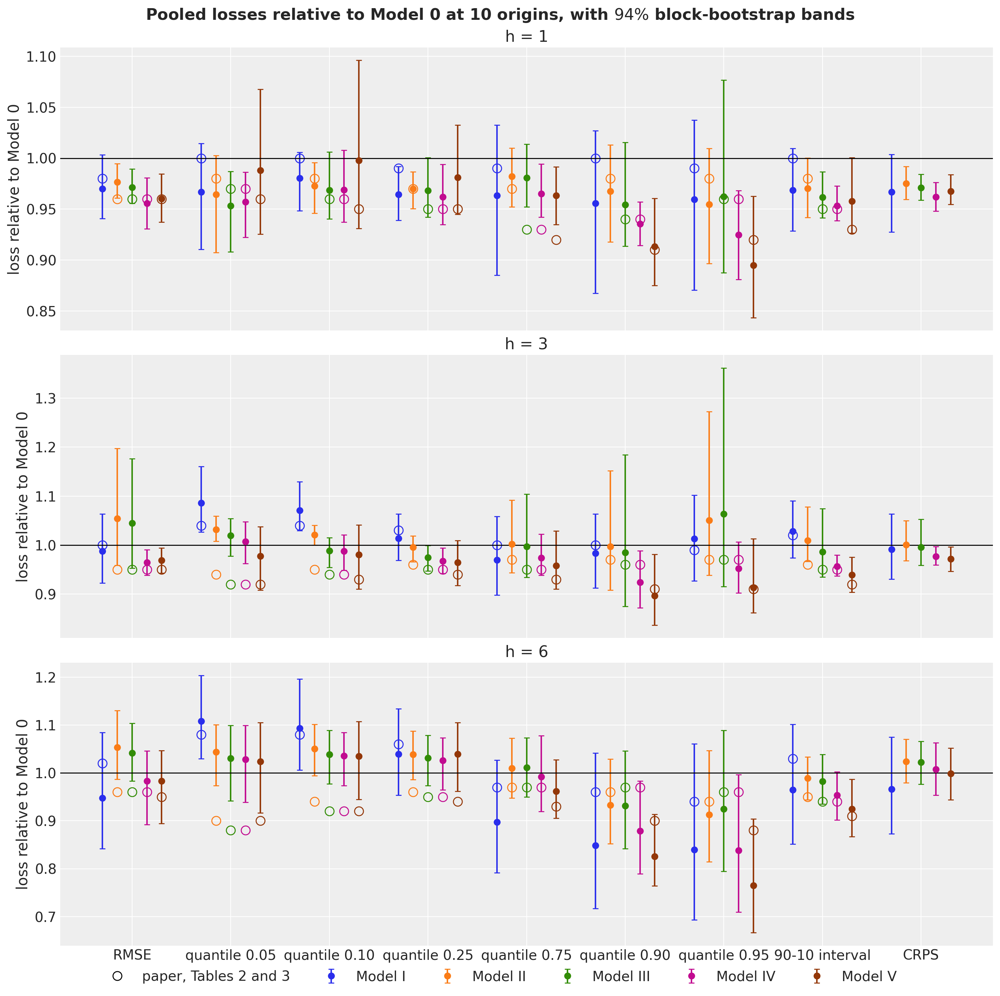

In [48]:
NUM_BOOTSTRAP = 1_000


def origin_losses(results: list[BacktestResult]) -> dict[str, dict[int, np.ndarray]]:
    """Every loss at every horizon, per origin ``(origins,)``, pooled over the states."""
    draws, truth = stack_windows(results)  # (w, s, 6, n), (w, 6, n)
    values: dict[str, dict[int, np.ndarray]] = {name: {} for name in LOSSES}

    for name in LOSSES:
        for h in HORIZONS:
            per_origin = np.array(
                [loss_at(name, draws[w, :, h - 1], truth[w, h - 1]) for w in range(len(results))]
            )
            values[name][h] = per_origin**2 if name == "rmse" else per_origin

    return values


def pooled(name: str, per_origin: np.ndarray, resample: np.ndarray) -> np.ndarray:
    """Pooled loss over the origins of every row of ``resample`` ``(draws, origins)``."""
    mean = per_origin[resample].mean(axis=1)
    return np.sqrt(mean) if name == "rmse" else mean


def relative_losses(
    model: dict[str, dict[int, np.ndarray]],
    benchmark: dict[str, dict[int, np.ndarray]],
    resample: np.ndarray,
) -> dict[str, dict[int, tuple[float, float, float]]]:
    """Relative loss (point, 3rd and 97th bootstrap percentiles) of ``model`` to ``benchmark``."""
    identity = np.arange(resample.shape[1])[None, :]
    relative: dict[str, dict[int, tuple[float, float, float]]] = {name: {} for name in LOSSES}

    for name in LOSSES:
        for h in HORIZONS:
            point = (
                pooled(name, model[name][h], identity)[0]
                / pooled(name, benchmark[name][h], identity)[0]
            )
            ratios = pooled(name, model[name][h], resample) / pooled(
                name, benchmark[name][h], resample
            )
            low, high = np.quantile(ratios, (0.03, 0.97))
            relative[name][h] = (float(point), float(low), float(high))

    return relative


rng_key, key_bootstrap = random.split(rng_key)
resample = np.asarray(
    random.randint(key_bootstrap, (NUM_BOOTSTRAP, len(origins)), 0, len(origins))
)
per_origin_losses = {label: origin_losses(results) for label, results in backtest_results.items()}
relative = {
    label: relative_losses(per_origin_losses[label], per_origin_losses["0"], resample)
    for label in LADDER
}

PAPER_RELATIVE = {  # Tables 2 and 3: rmse, the six quantile losses, the 90-10 interval loss
    1: {
        "I": (0.98, 1.00, 1.00, 0.99, 0.99, 1.00, 0.99, 1.00),
        "II": (0.96, 0.98, 0.98, 0.97, 0.97, 0.98, 0.98, 0.98),
        "III": (0.96, 0.97, 0.96, 0.95, 0.93, 0.94, 0.96, 0.95),
        "IV": (0.96, 0.97, 0.96, 0.95, 0.93, 0.94, 0.96, 0.95),
        "V": (0.96, 0.96, 0.95, 0.95, 0.92, 0.91, 0.92, 0.93),
    },
    3: {
        "I": (1.00, 1.04, 1.04, 1.03, 1.00, 1.00, 0.99, 1.02),
        "II": (0.95, 0.94, 0.95, 0.96, 0.97, 0.97, 0.97, 0.96),
        "III": (0.95, 0.92, 0.94, 0.95, 0.95, 0.96, 0.97, 0.95),
        "IV": (0.95, 0.92, 0.94, 0.95, 0.95, 0.96, 0.97, 0.95),
        "V": (0.95, 0.92, 0.93, 0.94, 0.93, 0.91, 0.91, 0.92),
    },
    6: {
        "I": (1.02, 1.08, 1.08, 1.06, 0.97, 0.96, 0.94, 1.03),
        "II": (0.96, 0.90, 0.94, 0.96, 0.97, 0.96, 0.94, 0.95),
        "III": (0.96, 0.88, 0.92, 0.95, 0.97, 0.97, 0.96, 0.94),
        "IV": (0.96, 0.88, 0.92, 0.95, 0.97, 0.97, 0.96, 0.94),
        "V": (0.95, 0.90, 0.92, 0.94, 0.93, 0.90, 0.88, 0.91),
    },
}
paper_losses = LOSSES[:-1]  # the paper has no CRPS

fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(14, 14), sharex=True, layout="constrained")
positions = np.arange(len(LOSSES))
width = 0.15

for ax, h in zip(axes, HORIZONS, strict=True):
    for offset, label in enumerate(LADDER):
        values = [relative[label][name][h] for name in LOSSES]
        x = positions + (offset - 2) * width
        ax.errorbar(
            x,
            [value[0] for value in values],
            yerr=[
                [value[0] - value[1] for value in values],
                [value[2] - value[0] for value in values],
            ],
            fmt="o",
            color=RUNG_COLORS[label],
            capsize=3,
            label=f"Model {label}",
        )
        ax.plot(
            x[: len(paper_losses)],
            PAPER_RELATIVE[h][label],
            marker="o",
            markerfacecolor="none",
            markeredgecolor=RUNG_COLORS[label],
            linestyle="none",
            markersize=9,
        )

    ax.axhline(1.0, color="black", lw=1)
    ax.set(
        title=f"h = {h}",
        ylabel="loss relative to Model 0",
        xticks=positions,
        xticklabels=[LOSS_LABELS[name] for name in LOSSES],
    )

axes[0].plot(
    [],
    [],
    marker="o",
    markerfacecolor="none",
    markeredgecolor="black",
    linestyle="none",
    markersize=9,
    label="paper, Tables 2 and 3",
)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=6)
fig.suptitle(
    r"Pooled losses relative to Model 0 at 10 origins, with $94\%$ block-bootstrap bands",
    fontsize=16,
    fontweight="bold",
);

Three readings, all with the bootstrap bands in view:

- The ladder gains at every horizon in the point values, and the bands say how sure that is. At $h = 1$ every rung has a relative RMSE between $0.956$ (Model IV) and $0.977$ (Model II), with bands of about $\pm 0.03$, and every band but Model I's stays below $1$; at $h = 3$ and $h = 6$ Models IV and V keep an RMSE of $0.965$ to $0.983$ while Models II and III rise to $1.04$ to $1.05$, with bands that include $1$. Ten origins make a band of $\pm 0.03$ to $\pm 0.1$, the size of the paper's gains.
- The gains sit in the upper quantiles. The losses of the $0.90$ and $0.95$ quantiles are where Models IV and V gain most: at the $0.95$ quantile Model V is at $0.895$ ($h = 1$), $0.913$ ($h = 3$) and $0.765$ ($h = 6$), below Models II and III at every horizon (Model I matches it at $h = 6$ with $0.839$); the lower quantiles do not: at $h = 6$ the $0.05$ to $0.25$ quantile losses of every rung are $1.02$ to $1.11$, where the paper has $0.88$ to $0.96$ for Models II to V, and the bands run from about $0.95$ to $1.2$.
- The paper's circles are inside most bands. The paper's Model I has an RMSE of $0.98$, $1.00$ and $1.02$ at the three horizons where this notebook's has $0.970$, $0.988$ and $0.947$, and its Models II and III at $h = 3$ are at $0.95$ where this notebook's are at $1.05$ and $1.04$; the two sets agree on Models IV and V and on the pattern across quantiles. With 235 origins the paper's values are the precise ones, and the bands here say which differences ten origins can see: the upper-quantile gains of Models IV and V, and not the $0.02$ steps between neighboring rungs.

The 90-10 interval loss, the paper's summary of the quantile losses, falls down the ladder at $h = 3$ and $h = 6$ (from $1.03$ and $0.97$ for Model I to $0.94$ and $0.92$ for Model V) and stays at $0.95$ to $0.97$ at $h = 1$; the CRPS, which the paper does not report, moves with the RMSE.

The figure carries the uncertainty; the table carries the point values, in the layout of the paper's Tables 2 and 3 (rows: horizon and loss; columns: rung).

In [49]:
relative_table = pd.DataFrame(
    {
        f"Model {label}": [relative[label][name][h][0] for h in HORIZONS for name in LOSSES]
        for label in LADDER
    },
    index=pd.MultiIndex.from_tuples(
        [(f"h = {h}", LOSS_LABELS[name]) for h in HORIZONS for name in LOSSES],
        names=["horizon", "loss"],
    ),
).round(3)
relative_table

Model I  Model II  Model III  Model IV  Model V
horizon loss                                                           
h = 1   RMSE              0.970     0.977      0.971     0.956    0.960
        quantile 0.05     0.967     0.964      0.953     0.957    0.988
        quantile 0.10     0.980     0.973      0.969     0.969    0.998
        quantile 0.25     0.965     0.970      0.968     0.962    0.981
        quantile 0.75     0.963     0.982      0.981     0.965    0.963
        quantile 0.90     0.956     0.968      0.954     0.936    0.913
        quantile 0.95     0.960     0.955      0.962     0.925    0.895
        90-10 interval    0.969     0.970      0.962     0.953    0.958
        CRPS              0.967     0.975      0.971     0.962    0.968
h = 3   RMSE              0.988     1.054      1.044     0.965    0.969
        quantile 0.05     1.086     1.032      1.019     1.008    0.977
        quantile 0.10     1.071     1.021      0.988     0.987    0.980
        quantile 0.25     1.014     0.995      0.974     0.968    0.965
        quantile 0.75     0.970     1.002      0.997     0.974    0.958
        quantile 0.90     0.984     0.997      0.985     0.924    0.897
        quantile 0.95     1.013     1.050      1.064     0.952    0.913
        90-10 interval    1.028     1.009      0.986     0.956    0.940
        CRPS              0.991     1.001      0.996     0.977    0.972
h = 6   RMSE              0.947     1.053      1.041     0.983    0.983
        quantile 0.05     1.108     1.044      1.030     1.028    1.024
        quantile 0.10     1.093     1.050      1.038     1.036    1.034
        quantile 0.25     1.039     1.038      1.031     1.026    1.039
        quantile 0.75     0.898     1.009      1.011     0.992    0.961
        quantile 0.90     0.849     0.933      0.932     0.879    0.826
        quantile 0.95     0.839     0.913      0.925     0.838    0.765
        90-10 interval    0.965     0.989      0.982     0.953    0.925
        CRPS              0.966     1.024      1.022     1.008    0.999

The table matches the figure; three cells to read against the paper's Tables 2 and 3: the $h = 6$ RMSE of Model I ($0.947$ here, $1.02$ in the paper), the $h = 3$ RMSE of Model II ($1.054$ against $0.95$) and the $h = 6$ $0.95$ quantile of Model V ($0.765$ against $0.88$). Each sits at the end of a bootstrap band that reaches the paper's value. Models IV and V are within $0.04$ of the paper's values in every RMSE cell.

The paper's Figure 2 shows how the gain spreads across states: the RMSE of each state over the origins, relative to Model 0 for that state. We draw it at $h = 3$, the horizon where the paper's gains are largest.

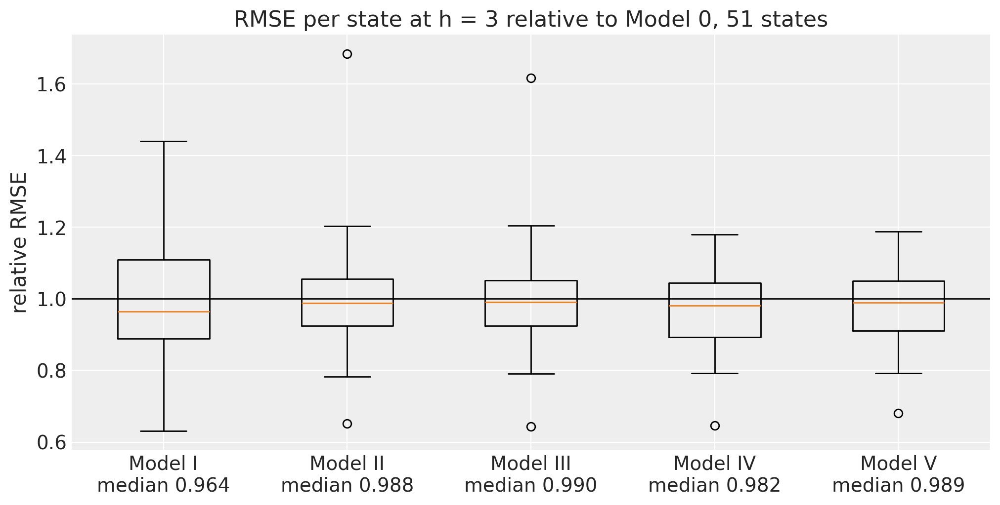

In [50]:
def state_relative_rmse(
    results: list[BacktestResult], benchmark: list[BacktestResult], h: int
) -> np.ndarray:
    """RMSE per state over the origins at horizon ``h``, relative to the benchmark, ``(states,)``."""
    draws, truth = stack_windows(results)
    benchmark_draws, _ = stack_windows(benchmark)
    error = draws[:, :, h - 1].mean(axis=1) - truth[:, h - 1]  # (origins, states)
    benchmark_error = benchmark_draws[:, :, h - 1].mean(axis=1) - truth[:, h - 1]
    return np.asarray(
        jnp.sqrt((error**2).mean(axis=0)) / jnp.sqrt((benchmark_error**2).mean(axis=0))
    )


state_rmse = {
    label: state_relative_rmse(backtest_results[label], backtest_results["0"], 3)
    for label in LADDER
}

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(
    [state_rmse[label] for label in LADDER],
    tick_labels=[f"Model {label}\nmedian {np.median(state_rmse[label]):.3f}" for label in LADDER],
)
ax.axhline(1.0, color="black", lw=1)
ax.set(title="RMSE per state at h = 3 relative to Model 0, 51 states", ylabel="relative RMSE");

The medians across states are $0.964$ (Model I), $0.988$ (II), $0.990$ (III), $0.982$ (IV) and $0.989$ (V), with interquartile ranges of about $0.9$ to $1.05$ for every rung: the pooled gain of the ladder at $h = 3$ comes from a few states with a large gain while most states sit near $1$. The paper's Figure 2 has the boxes of Models II to V entirely below $1$, a widespread gain that ten origins do not reproduce. Model I has the widest box, from $0.89$ to $1.11$ with whiskers from $0.63$ to $1.44$ (the Minnesota prior with no pooling helps some states and hurts others), and the hierarchical rungs pull the boxes in to about $0.92$ to $1.05$, with one state at $1.6$ to $1.7$ under Models II and III. No rung is worse than Model 0 for more than about half the states, and none is better for every state.

### Calibration

The interval loss rewards narrow intervals and penalizes misses, so a model can score well with intervals that are a little too narrow. The coverage separates the two: the share of the $10 \times 51$ realized growth rates inside the 90-10 interval and inside the 75-25 interval of each rung, at each horizon. A calibrated forecast covers $80\%$ and $50\%$; with $510$ cases the binomial standard deviation is below two percentage points, but the cases of one origin are correlated across states, so the bands around the nominal levels are the block bootstrap over origins again.

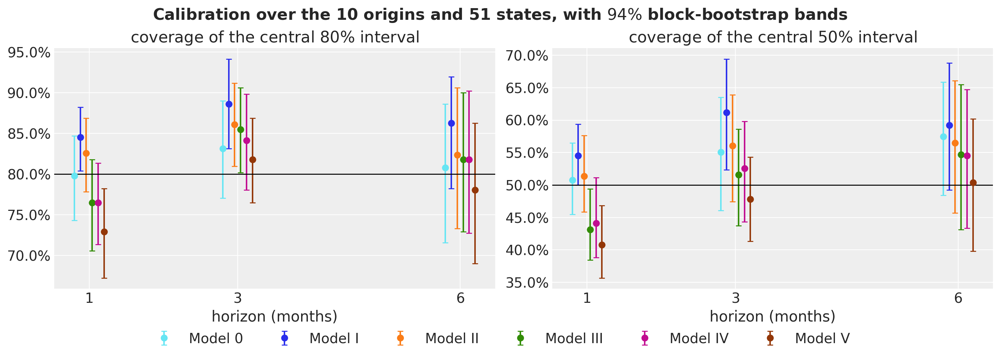

In [51]:
def coverage(results: list[BacktestResult], level: float) -> dict[int, np.ndarray]:
    """Share of the states inside the central ``level`` interval, per origin, at each horizon."""
    draws, truth = stack_windows(results)
    tail = (1.0 - level) / 2.0
    lower, upper = jnp.quantile(draws, jnp.array([tail, 1.0 - tail]), axis=1)  # (w, 6, n) each
    inside = (truth >= lower) & (truth <= upper)
    return {h: np.asarray(inside[:, h - 1].mean(axis=1)) for h in HORIZONS}


fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5), layout="constrained")

for ax, level in zip(axes, (0.8, 0.5), strict=True):
    for label, results in backtest_results.items():
        per_origin = coverage(results, level)
        means = [per_origin[h].mean() for h in HORIZONS]
        bands = np.array(
            [np.quantile(per_origin[h][resample].mean(axis=1), (0.03, 0.97)) for h in HORIZONS]
        )
        ax.errorbar(
            np.array(HORIZONS) + 0.08 * (list(backtest_results).index(label) - 2.5),
            means,
            yerr=[np.array(means) - bands[:, 0], bands[:, 1] - np.array(means)],
            fmt="o",
            color=RUNG_COLORS[label],
            capsize=3,
            label=f"Model {label}",
        )

    ax.axhline(level, color="black", lw=1)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0))
    ax.set(
        title=rf"coverage of the central ${level:.0%}$ interval".replace("%", r"\%"),
        xlabel="horizon (months)",
        xticks=HORIZONS,
    )

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=6)
fig.suptitle(
    r"Calibration over the 10 origins and 51 states, with $94\%$ block-bootstrap bands",
    fontsize=16,
    fontweight="bold",
);

Calibration moves in one direction down the ladder: toward narrower intervals. At $h = 1$ the central $80\%$ interval covers $84.5\%$ of the cases under Model I, $82.5\%$ under Model II, $76\%$ to $77\%$ under Models III and IV and $72.9\%$ under Model V, against $79.8\%$ for Model 0; the $50\%$ interval covers $54.5\%$, $51\%$, $43\%$, $44\%$ and $41\%$. The Student-t rungs put less mass in the center and more in the tails, so their central intervals are narrower than the data at these ten origins, and the volatility of Model V, which lowers the scale after 2012, narrows them further. At $h = 3$ and $h = 6$ every rung but Model V at $h = 6$ ($78.0\%$) is above nominal on the $80\%$ interval (Model I at $88.6\%$ and $86.3\%$): the multi-step predictive is wider than the realized paths at these origins, and the bands of $\pm 5$ points, from the ten origins, include the nominal level for most rungs. The interval loss that rewarded Models IV and V in the last section is a width-adjusted score, and this figure shows the price: at $h = 1$ their intervals are too narrow by $3$ to $7$ points of coverage.

The coverage values behind the figure:

In [52]:
coverage_table = pd.DataFrame(
    {
        f"Model {label}": [
            coverage(results, level)[h].mean() for level in (0.8, 0.5) for h in HORIZONS
        ]
        for label, results in backtest_results.items()
    },
    index=pd.MultiIndex.from_tuples(
        [(f"{level:.0%} interval", f"h = {h}") for level in (0.8, 0.5) for h in HORIZONS],
        names=["interval", "horizon"],
    ),
).round(3)
coverage_table

Model 0  Model I  Model II  Model III  Model IV  Model V
interval     horizon                                                          
80% interval h = 1      0.798    0.845     0.825      0.765     0.765    0.729
             h = 3      0.831    0.886     0.861      0.855     0.841    0.818
             h = 6      0.808    0.863     0.824      0.818     0.818    0.780
50% interval h = 1      0.508    0.545     0.514      0.431     0.441    0.408
             h = 3      0.551    0.612     0.561      0.516     0.525    0.478
             h = 6      0.575    0.592     0.565      0.547     0.545    0.504

The table is the figure in numbers: the one-step coverage of the $80\%$ interval falls from $0.845$ (Model I) to $0.729$ (Model V) and that of the $50\%$ interval from $0.545$ to $0.408$, both past the nominal level on the way down, and Model 0 at $0.798$ and $0.508$ is the best calibrated one-step forecast of the six.

### Leave-future-out log score and stacking

The backtest is a **leave-future-out cross-validation**: every fit sees the data up to the origin and is scored on what came after. The log score of the one-step forecast is computed from densities, not from forecast draws: given a posterior draw (and, for Models IV and V, its draw of the outlier and of the volatility step of the next month), the one-step predictive is a Student-t (a Normal for Models I and II) with the location and scale that `forecast_fn` kept, and the predictive density is the average of those densities over the draws. We compute $\log p_m(y_{j,T^*+1} \mid \text{data up to } T^*)$ for every rung $m$, origin and state, average it (a higher value is better), and use the same densities to compute **stacking weights** in the sense of [Yao et al. (2018)](https://doi.org/10.1214/17-BA1091): the weights $w_m \ge 0$, $\sum_m w_m = 1$, that maximize the log score of the mixture $\sum_m w_m p_m$ over the origins and states. A rung whose forecasts add nothing to the others gets a weight near zero. PSIS-LOO is not used here: leaving out one month given the months before and after it is not a forecasting criterion, and Models IV and V carry a latent per month whose posterior moves with the month left out, which breaks the comparison of their pointwise likelihoods with those of Models I to III.

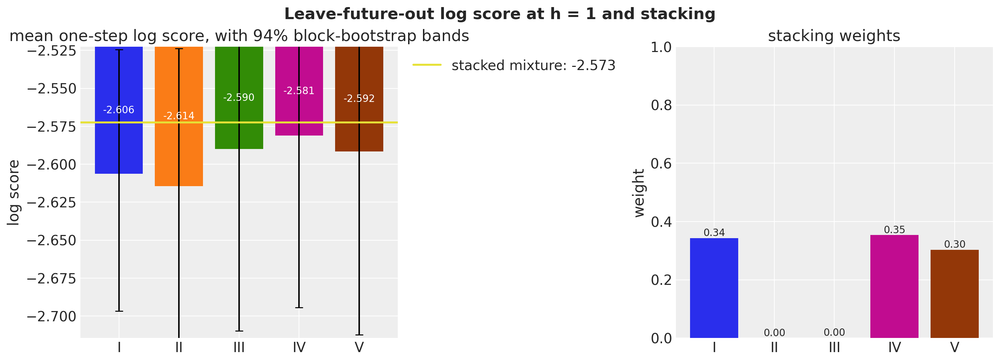

In [53]:
def log_predictive_density(label: str) -> np.ndarray:
    """Log one-step predictive density of the realized growth, ``(origins, states)``."""
    scores = []

    for result, origin in zip(backtest_results[label], origins, strict=True):
        loc, scale, nu = one_step[
            label, origin
        ]  # (samples, states), (samples, states), (samples, states)
        y = growth[result.t1]  # (states,): the first month after the origin
        if nu is None:
            log_density = dist.Normal(loc, scale).log_prob(y)
        else:
            log_density = dist.StudentT(nu, loc, scale).log_prob(y)
        scores.append(np.asarray(logsumexp(log_density, axis=0) - jnp.log(loc.shape[0])))

    return np.stack(scores)


log_scores = {label: log_predictive_density(label) for label in LADDER}  # each (origins, states)
log_score_mean = {label: float(scores.mean()) for label, scores in log_scores.items()}
log_score_band = {
    label: np.quantile(scores.mean(axis=1)[resample].mean(axis=1), (0.03, 0.97))
    for label, scores in log_scores.items()
}

stacked = jnp.stack([log_scores[label].reshape(-1) for label in LADDER], axis=1)  # (cases, rungs)


def negative_stacking_score(logits: Array) -> Array:
    """Minus the mean log score of the mixture with softmax weights ``logits``."""
    log_weights = jax.nn.log_softmax(logits)
    return -logsumexp(stacked + log_weights[None, :], axis=1).mean()


solution = minimize(negative_stacking_score, jnp.zeros(len(LADDER)), method="BFGS")
stacking_weights = np.asarray(jax.nn.softmax(solution.x))
stacked_score = -float(solution.fun)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5), layout="constrained")
labels = list(LADDER)
bars = axes[0].bar(
    labels,
    [log_score_mean[label] for label in labels],
    color=[RUNG_COLORS[label] for label in labels],
)
axes[0].bar_label(bars, fmt="%.3f", label_type="center", color="white")
axes[0].errorbar(
    labels,
    [log_score_mean[label] for label in labels],
    yerr=[
        [log_score_mean[label] - log_score_band[label][0] for label in labels],
        [log_score_band[label][1] - log_score_mean[label] for label in labels],
    ],
    fmt="none",
    color="black",
    capsize=4,
)
axes[0].axhline(stacked_score, color="C6", lw=2, label=f"stacked mixture: {stacked_score:.3f}")
axes[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
axes[0].set(
    title=r"mean one-step log score, with $94\%$ block-bootstrap bands",
    ylabel="log score",
    ylim=(
        min(log_score_mean.values()) - 0.1,
        max(stacked_score, max(log_score_mean.values())) + 0.05,
    ),
)
bars = axes[1].bar(labels, stacking_weights, color=[RUNG_COLORS[label] for label in labels])
axes[1].bar_label(bars, fmt="%.2f")
axes[1].set(title="stacking weights", ylabel="weight", ylim=(0, 1))
fig.suptitle("Leave-future-out log score at h = 1 and stacking", fontsize=16, fontweight="bold");

The one-step log scores are $-2.606$ (I), $-2.614$ (II), $-2.590$ (III), $-2.581$ (IV) and $-2.592$ (V), with bootstrap bands of about $\pm 0.08$ that overlap: on the one-step density the three Student-t rungs score above the two Normal ones by $0.01$ to $0.03$ nats per case, a difference inside the bands. The stacking weights put $0.35$ on Model IV, $0.34$ on Model I and $0.30$ on Model V, and nothing on Models II and III, and the stacked mixture scores $-2.573$, $0.008$ above the best single rung. Stacking combines predictive densities that differ, and the Student-t rungs with their narrow centers and the Normal rung with its wide center are the pair it uses: the mixture covers both the ordinary months and the tails. The gain is small, because the five rungs are close relatives; a mixture of this ladder with a model that uses the comovement across states would have more to combine.

The last check on the backtest is the fits themselves: the divergences and the largest $\hat R$ over the hyperparameters of every fold.

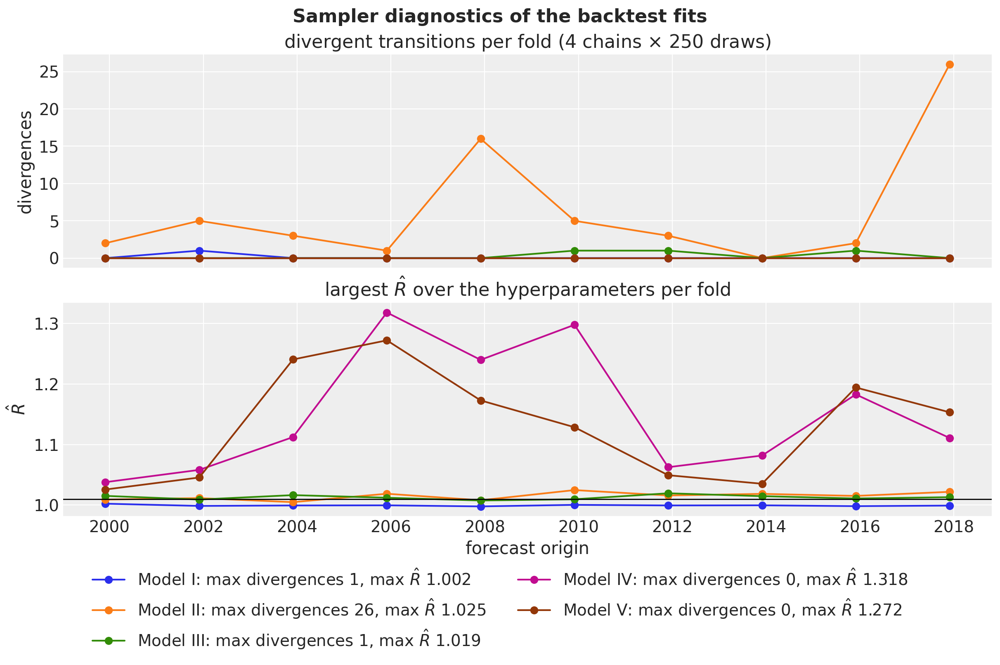

In [54]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 8), sharex=True, layout="constrained")

for label in LADDER:
    rows = [row for row in backtest_fits if row[0] == label]
    axes[0].plot(
        [row[1] for row in rows],
        [row[2] for row in rows],
        marker="o",
        color=RUNG_COLORS[label],
        label=f"Model {label}: max divergences {max(row[2] for row in rows)}, "
        + rf"max $\hat{{R}}$ {max(row[3] for row in rows):.3f}",
    )
    axes[1].plot(
        [row[1] for row in rows], [row[3] for row in rows], marker="o", color=RUNG_COLORS[label]
    )

axes[0].set(
    title=r"divergent transitions per fold (4 chains $\times$ 250 draws)", ylabel="divergences"
)
axes[1].axhline(1.01, color="black", lw=1)
axes[1].set(
    title=r"largest $\hat{R}$ over the hyperparameters per fold",
    ylabel=r"$\hat{R}$",
    xlabel="forecast origin",
)
locator = mdates.AutoDateLocator()
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=2)
fig.suptitle("Sampler diagnostics of the backtest fits", fontsize=16, fontweight="bold");

Every one of the $50$ fits mixes to a largest $\hat R$ below $1.32$ over the hyperparameters with at most $26$ divergent transitions in $1{,}000$ draws: Model II accumulates a handful of divergences at most folds ($26$ at the 2017m12 origin), the price of the centered scale hierarchy on short windows, and Models IV and V reach a largest $\hat R$ of $1.3$ at the 2005m12 and 2009m12 origins; the backtest records only the largest $\hat R$, and `kappa_loc` is the slow site of these two rungs on the full sample. Without the cap on $\ln(\nu_j - 2)$ of the Model III section, the Model III fit at the 2003m12 origin had one chain trapped at $\nu \approx e^{11}$ with $\hat R = 19.7$; with it the fold is like the others. The forecasts of every fold are kept, including the ones with the slow `kappa_loc`: the one-step location and scale do not depend on where that hyperparameter sits, as the Model IV section showed on the full sample.

## Cost

The paper reports about one minute for $4{,}000$ draws of the full RTS model (Models VI and VII included) on the employment data, in Fortran on a 24-core workstation, with a Gibbs sampler that draws the latent paths with a Kalman smoother and the hyperparameters with random-walk Metropolis steps. The figure gives the wall time of the NUTS fits of this notebook on a laptop CPU with four chains in parallel: the full-sample fit of every rung with its diagnostics, and the sum of the 10 backtest fits.

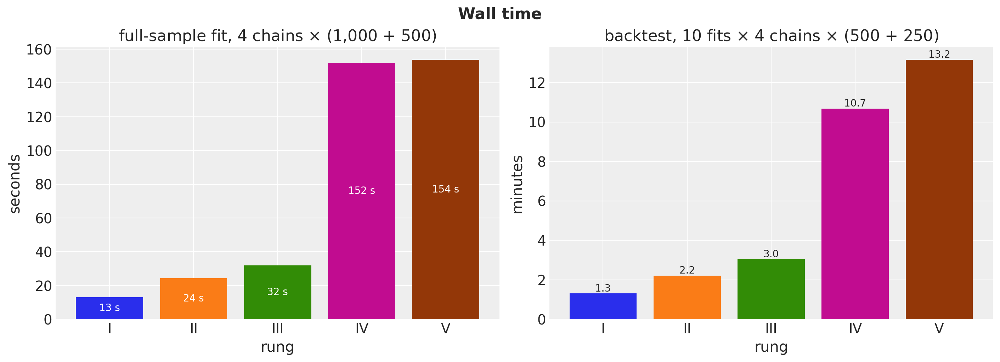

In [55]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5), layout="constrained")
labels = list(FITS)
bars = axes[0].bar(
    labels, [FITS[label][1] for label in labels], color=[RUNG_COLORS[label] for label in labels]
)

axes[0].bar_label(bars, fmt="%.0f s", label_type="center", color="white")
axes[0].set(
    title=r"full-sample fit, 4 chains $\times$ (1,000 + 500)",
    ylabel="seconds",
    xlabel="rung",
)
backtest_minutes = {
    label: sum(row[4] for row in backtest_fits if row[0] == label) / 60.0 for label in LADDER
}
bars = axes[1].bar(
    list(backtest_minutes),
    list(backtest_minutes.values()),
    color=[RUNG_COLORS[label] for label in backtest_minutes],
)
axes[1].bar_label(bars, fmt="%.1f")
axes[1].set(
    title=r"backtest, 10 fits $\times$ 4 chains $\times$ (500 + 250)",
    ylabel="minutes",
    xlabel="rung",
)
fig.suptitle("Wall time", fontsize=16, fontweight="bold");

The full-sample fits take $13$, $24$ and $32$ seconds for Models I to III and $152$ and $154$ seconds for Models IV and V, the two rungs with a latent per observation, and the backtest multiplies that by about four for ten fits with half the iterations: $1.3$ to $3.0$ minutes for the first three rungs and $10.7$ and $13.2$ minutes for the last two, about $30$ minutes for the whole experiment. The paper's Gibbs sampler draws the latent paths in closed form from the Kalman smoother; NUTS pays for those paths with a gradient per leapfrog step through $17{,}697$ outlier latents, and the cost shows where the model has them. The gradient-based sampler is general and needs no model-specific derivation; the paper's sampler is faster by about an order of magnitude on this model.

## Discussion

The ladder of this notebook reproduces the paper's ordering of the models and most of its numbers, from a different sampler and at a tenth of the origins. The hierarchical prior learns the paper's Figure 3 (centers of $0.12$ and $0.16$ at lags two and three, a spread that narrows at lag one), the Student-t rungs find degrees of freedom between $2.5$ and $7.4$ (the paper's Figure 4), the outlier component takes Hurricane Katrina and the volatility path peaks in 2009 as in the paper's Figure 5, and differs from it before and after. In the forecast experiment the Bayesian rungs beat the OLS benchmark by $2\%$ to $4\%$ on the one-step RMSE and by $7\%$ to $24\%$ on the $0.95$ quantile at $h = 6$, with Models IV and V within $0.04$ of the paper's relative RMSE in every cell. What the checks add to the paper's tables is the direction of each remaining failure: the Normal rungs cannot produce the tails, no rung produces the reversals after the mining spikes, no rung reaches the 2009 collapse in coverage, and the Student-t rungs pay for their tails with central intervals that are too narrow one step ahead. The benchmark keeps $4{,}000$ draws where the Bayesian rungs have $1{,}000$, so the sample quantiles of the rungs carry more Monte Carlo error, a small handicap in the tail quantile losses.

What the results say about modeling data of this kind:

- Hierarchical pooling across series is the cheapest rung and the one the data ask for first. The estimated prior differs from the Minnesota prior where every state agrees (lags two to six), and the two hierarchies cost $11$ seconds of sampling time ($13$ to $24$). Its forecast gain over Model I is inside the bootstrap bands at ten origins, which says what ten origins can measure, not that the gain is absent.
- Heavy tails and the outlier component are two different things. The Student-t innovations pass the tail check and lower the upper-quantile losses; the additive outlier component takes the one event the Student-t cannot absorb (Katrina) and leaves the recurrent spikes to the innovations, and the two score the same out of sample in the paper; here Model IV is ahead at $h = 3$ and $h = 6$ (RMSE $0.965$ against $1.044$ and $0.983$ against $1.041$), a difference inside the bootstrap bands.
- The stochastic volatility is slow by construction. Nine cosines over $347$ months follow the 2009 peak and the decline after 2012, and not the first months of 2009; the rung gains at $h = 6$ in the upper quantiles ($0.765$) and pays in one-step coverage ($72.9\%$).
- Stacking the ladder adds little. The rungs are nested, and the mixture gains $0.008$ nats over the best single rung; the weights say which rungs differ most (Model I's Normal center and the tails of Models IV and V).

Open weaknesses:

- Ten origins. The paper re-estimates at $235$ monthly origins; the NUTS ladder re-estimates at every twenty-fourth one. Model 0 at all $235$ origins reproduces the paper's benchmark RMSE on this vintage, so the data and the loss are the paper's, but the relative losses of the Bayesian rungs carry bootstrap bands of $\pm 0.03$ to $\pm 0.1$, the size of the paper's gains, and a difference of a few hundredths between two rungs is inside the noise.
- No time-varying parameters and no common factor. The paper's Models VI and VII add random walks in $\mu_j$ and $\phi_{j,l}$ and a dynamic factor with state-specific loadings; the factor is where the paper's largest point-forecast gain comes from (a relative RMSE of $0.89$ at $h = 3$ against $0.95$ for Model V). The 12-month correlation of $0.64$ across states measured in the data section is the information none of the rungs here uses.
- The outlier component finds the largest shocks only. With the paper's priors and the informed start, Model IV captures the two Katrina months and nothing else in the six states shown; the spike-and-reversal pairs of West Virginia stay innovations, and the reversal check fails for Models IV and V as it does for Model III.
- Fixed $\nu^o$. The degrees of freedom of the outlier distribution are the paper's prior median; the data do not inform them under NUTS.
- The slow hyperparameter. `kappa_loc` reaches an effective sample size of $26$ to $74$ in the full-sample fits, and the backtest fits of Models IV and V reach a largest $\hat R$ of $1.3$ over the hyperparameters. The quantities the component is for mix, and the hyperparameter itself is reported with that caveat.
- The volatility path outside 2009. The common path falls from 1991 to 2004 and after 2012 where the paper's rises; the data section's rolling standard deviations side with the path here, and the cause of the difference is open.
- The seed rows. The first twelve months enter every model as fixed lag values with no outlier and no volatility term, where the paper puts a stationary prior on them.

Fairness notes on the evaluation:

- No information about the forecast horizon enters any model: the windows expand to the origin, the informed start of the outliers is computed on the window, and the forecast uses the posterior at the origin only. The volatility basis of Model V is built for the window, with $q$ terms that grow with it.
- The data are the revised series as published on 2026-11-09, not the vintages a forecaster had at each origin; the paper uses revised data too, so the comparison with its tables is on the same footing, up to the revisions between its vintage and ours. Model 0 at the paper's $235$ origins gives the paper's benchmark RMSE to the first decimal.
- The ten origins are $24$ months apart and the horizon is six months, so no two windows share a forecast month, but the realized paths of the $51$ states at one origin are correlated, which the block bootstrap over origins accounts for and a per-case standard error would not.

The departures from the paper's specification, collected:

1. The common scale $\omega$ is absorbed into the location of the $\ln \sigma_j^2$ prior (`log_omega2`), and the $\kappa$ hierarchy is centered on it; the posterior of every identified quantity is the paper's.
2. Proper diffuse priors $\text{Normal}(0, 10^2)$ on $\mu_j$ and $\ln \omega^2$ instead of flat ones.
3. Fixed initial conditions: the growth rates of 1990m2 to 1991m1 seed the lag window instead of the paper's stationary prior on the twelve values before the sample; the likelihood starts in 1991m2.
4. NUTS on the joint posterior instead of the paper's Gibbs and Metropolis steps, with the Student-t innovations and outliers entering through their densities instead of the paper's scale-mixture latents, and $\ln(\nu_j - 2)$ capped at $8$ for float32.
5. The forecast experiment re-estimates the Bayesian rungs at $10$ origins instead of $235$, with $4$ chains of $500$ warmup iterations and $250$ draws per fit.
6. $\nu^o_j$ fixed at $4$, the paper's prior median.
7. The interval loss uses the constant $2/\alpha$, which makes the 90-10 interval its minimizer, where the paper's display prints $1/\alpha$.
8. The volatility over the horizon continues $\ln \sigma^2_{j,t}$ as a random walk with step variance $v_\xi$; the paper's sentence names $\ln \sigma_{j,t}$.
9. $q$ and the basis: $q = \lfloor (t_{\text{obs}} + 12) / 36 \rfloor$ counts the seed rows as the paper counts its $T$, but the basis itself is built over the $347$ likelihood rows, where the paper's $\varphi_l((t - 1/2) / T)$ runs over all $359$ months.
10. The informed start of the outlier latents at the robust deviations beyond $20$ points, with the start at zero shown for comparison.

## References

- Müller, U. K., Watson, M. W. (2026). [*Forecasting related time series*](https://doi.org/10.1002/jae.70050). Journal of Applied Econometrics, 41(4), 481 to 498. Author version: [Princeton, October 2025](https://www.princeton.edu/~mwatson/papers/MW_RTS_20251022.pdf).
- Doan, T., Litterman, R., Sims, C. (1984). [*Forecasting and conditional projection using realistic prior distributions*](https://doi.org/10.1080/07474938408800053). Econometric Reviews, 3(1).
- Gneiting, T., Raftery, A. E. (2007). [*Strictly proper scoring rules, prediction, and estimation*](https://doi.org/10.1198/016214506000001437). Journal of the American Statistical Association, 102(477).
- Yao, Y., Vehtari, A., Simpson, D., Gelman, A. (2018). [*Using stacking to average Bayesian predictive distributions*](https://doi.org/10.1214/17-BA1091). Bayesian Analysis, 13(3).
- Data: U.S. Bureau of Labor Statistics, Current Employment Statistics (state and area), total nonfarm employees, seasonally adjusted, series `<state>NA` (for example [CANA](https://fred.stlouisfed.org/series/CANA)), retrieved from FRED, Federal Reserve Bank of St. Louis, on 2026-11-09.
- Related examples: [vector autoregression](var.html) (the Minnesota prior and the VAR building blocks), [hierarchical forecasting I](hierarchical_forecasting_1.html) (pooling across series), [trend inflation](trend_inflation.html) (stochastic volatility and a NUTS backtest ladder).